# From Combine movement to NFL decisions: an evidence map

**Some movement transfers; added performance prediction remains uncertain.** This notebook
rebuilds every submission figure and the nine-primary-comparison table from the nine competition
CSVs. It includes the original source so no unpublished repository, cache, remote machine or
credential is needed. Every development model is refitted and frozen before evaluation scoring.

2025 outcomes were used in earlier studies. The cohort split below is retrospective conditional
validation, not a pristine holdout or a draft-time forecast. The route-family measurement gate
failed; no TURN interaction is fitted. Selected favourable and adverse cone findings remain secondary.

Code: MIT license (embedded in the source bundle). Data attribution: NFL / NFL Big Data Bowl 2027,
competition data (CC BY-NC 4.0). The code license does not relicense competition data.
Official source: https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/data .
Local use: set `BDB_INPUT_ROOT` to the raw CSV folder. Each Run All creates a fresh output directory.

In [1]:
import os, sys, json, hashlib, tempfile, time, subprocess
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
os.environ.update(OPENBLAS_NUM_THREADS='2', OMP_NUM_THREADS='2', POLARS_MAX_THREADS='2', MPLBACKEND='Agg')
STARTED = time.monotonic()
INPUT_NAMES = ['players.csv','combine_results.csv','combine_tracking.csv','games.csv',
               'player_play.csv','player_career_successes.csv',
               'game_tracking_2023.csv','game_tracking_2024.csv','game_tracking_2025.csv']
input_base = Path(os.environ.get('BDB_INPUT_ROOT', '/kaggle/input'))
inputs = {}
for name in INPUT_NAMES:
    matches = sorted(input_base.rglob(name))
    if len(matches)!=1:
        raise ValueError(f'Expected one {name} under {input_base}; found {len(matches)}')
    inputs[name] = matches[0].resolve()
output_base = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path(tempfile.gettempdir())
run_root = Path(tempfile.mkdtemp(prefix='bdb_raw_rebuild_', dir=output_base))
for directory in ['src','tests','reports/figures','data/raw','data/interim']:
    (run_root/directory).mkdir(parents=True, exist_ok=True)
for name,path in inputs.items():
    (run_root/'data/raw'/name).symlink_to(path)
print('Fresh raw-input rebuild:', run_root)
print('Input CSVs:', sorted(inputs))

Fresh raw-input rebuild: /tmp/bdb_raw_rebuild_6yezqm_k
Input CSVs: ['combine_results.csv', 'combine_tracking.csv', 'game_tracking_2023.csv', 'game_tracking_2024.csv', 'game_tracking_2025.csv', 'games.csv', 'player_career_successes.csv', 'player_play.csv', 'players.csv']


## Source and environment

The expandable source cell writes the frozen statistical modules and the bounded data pipeline
into the fresh working directory. The reference JSON is used only for assertions **after** all
fits and scores; it never supplies results or coefficients. CSV and source hashes are recorded.
Kaggle installs the recorded package versions when needed (Internet must be enabled).

In [2]:
SOURCE_FILES = json.loads('{"src/__init__.py": "", "src/kinematics.py": "\\"\\"\\"Frame-level kinematics shared by Combine and game tracking.\\n\\nProvided `a` is the *unsigned magnitude* of total acceleration, so we rebuild a signed decomposition\\nfrom positions: a_lon (along the direction of travel: + speeding up, - braking) and a_lat (perpendicular:\\nturning / \\"cornering\\"; sign = left/right). Validated on Combine data: |a| from x,y vs provided `a`\\nr = 0.976; speed from x,y vs `s` r = 0.9995.\\n\\"\\"\\"\\nimport numpy as np\\nimport polars as pl\\nfrom scipy.signal import savgol_filter\\n\\nDT = 0.1  # 10 Hz\\nWINDOW, ORDER = 7, 2  # Savitzky-Golay: 0.7 s window, quadratic\\n\\n\\ndef decompose(x: np.ndarray, y: np.ndarray) -> dict[str, np.ndarray]:\\n    \\"\\"\\"Smoothed speed, longitudinal and lateral acceleration (yd/s, yd/s^2) for one continuous track.\\"\\"\\"\\n    w = min(WINDOW, len(x) - (1 - len(x) % 2))  # odd window <= len\\n    if w <= ORDER:\\n        nan = np.full(len(x), np.nan)\\n        return {\\"sp\\": nan, \\"a_lon\\": nan, \\"a_lat\\": nan, \\"curv\\": nan, \\"hdg\\": nan}\\n    vx = savgol_filter(x, w, ORDER, deriv=1, delta=DT)\\n    vy = savgol_filter(y, w, ORDER, deriv=1, delta=DT)\\n    ax = savgol_filter(x, w, ORDER, deriv=2, delta=DT)\\n    ay = savgol_filter(y, w, ORDER, deriv=2, delta=DT)\\n    sp = np.hypot(vx, vy)\\n    safe = np.maximum(sp, 1e-6)\\n    a_lon = (vx * ax + vy * ay) / safe\\n    a_lat = (vx * ay - vy * ax) / safe\\n    # travel heading (radians, unwrapped so differences are continuous); unreliable when nearly stationary\\n    hdg = np.unwrap(np.arctan2(vy, vx))\\n    return {\\"sp\\": sp, \\"a_lon\\": a_lon, \\"a_lat\\": a_lat, \\"curv\\": a_lat / np.maximum(safe, 0.5) ** 2, \\"hdg\\": hdg}\\n\\n\\ndef add_kinematics(df: pl.DataFrame, track_keys: list[str]) -> pl.DataFrame:\\n    \\"\\"\\"Append sp, a_lon, a_lat, curv to a frame table sorted by time within each track.\\"\\"\\"\\n    out = []\\n    for _, g in df.group_by(track_keys, maintain_order=True):\\n        k = decompose(g[\\"x\\"].to_numpy(), g[\\"y\\"].to_numpy())\\n        out.append(g.with_columns([pl.Series(n, v) for n, v in k.items()]))\\n    return pl.concat(out)\\n", "src/combine_features.py": "\\"\\"\\"Per-player Combine movement-trait features (drill-normalised).\\n\\nRun:  .venv/bin/python -m src.combine_features\\nOut:  data/interim/combine_frames.parquet   frame-level kinematics (PLAYER rows only)\\n      data/interim/combine_attempts.parquet per-attempt raw features\\n      data/interim/combine_traits.parquet   one row per player: z-scored traits + split-half A/B versions\\n\\nWhy drill-normalised: players run different drill mixes, and pooling raw frames across drills made\\nsplit-half reliability ~0 (drill mix swamped the player). Fix: per attempt -> mean per (player, drill)\\n-> z-score within drill -> average across drills. Raw-pool attempt kept in git history (2026-10-08).\\n\\nPer-attempt features (straight-line 40 excluded):\\n  lat   : 90th pct |a_lat|  (turning / cornering capacity)\\n  burst : max a_lon         (re-acceleration)\\n  brake : -min a_lon        (peak braking; positive = harder)  -- low reliability, keep as secondary\\n  vmax  : max speed in drill\\n  dur   : drill duration (s); lower = quicker completion\\n\\"\\"\\"\\nimport polars as pl\\n\\nfrom src.kinematics import add_kinematics\\n\\nINTERIM = \\"data/interim\\"\\nFEATS = [\\"lat\\", \\"burst\\", \\"brake\\", \\"vmax\\", \\"dur\\"]\\n\\n# Canonicalise duplicate drill spellings found in the data.\\nDRILL_ALIASES = {\\n    \\"PASS_PRO-MIRROR_DRILL\\": \\"PASS_PRO_MIRROR_DRILL\\",\\n    \\"LINE\\": \\"LINE_DRILL\\",\\n    \\"SPEED_OUT_LEFT\\": \\"SPEED_OUT_ROUTE_LEFT\\",\\n    \\"OVER_THE_SHOULDER_ADJUST\\": \\"OVER_SHOULDER_ADJUST\\",\\n}\\n\\n\\ndef player_traits(player_drill: pl.DataFrame) -> pl.DataFrame:\\n    return player_drill.group_by(\\"nfl_id\\").agg(\\n        [pl.col(f\\"z_{x}\\").mean().alias(x) for x in FEATS] + [pl.len().alias(\\"n_drills\\")]\\n    )\\n\\n\\ndef main() -> None:\\n    ct = (\\n        pl.scan_parquet(f\\"{INTERIM}/combine_tracking.parquet\\")\\n        .filter(pl.col(\\"entity_type\\") == \\"PLAYER\\")\\n        .with_columns(drill=pl.col(\\"drill_name\\").replace(DRILL_ALIASES))\\n        .sort(\\"event_id\\", \\"time\\")\\n        .collect()\\n    )\\n    frames = add_kinematics(ct, [\\"event_id\\"])\\n    frames.write_parquet(f\\"{INTERIM}/combine_frames.parquet\\")\\n\\n    att = (\\n        frames.filter(pl.col(\\"drill_type\\") != \\"FORTY_YARD_DASH\\")\\n        .group_by(\\"nfl_id\\", \\"drill\\", \\"event_id\\")\\n        .agg(\\n            lat=pl.col(\\"a_lat\\").abs().quantile(0.9),\\n            burst=pl.col(\\"a_lon\\").max(),\\n            brake=-pl.col(\\"a_lon\\").min(),\\n            vmax=pl.col(\\"sp\\").max(),\\n            dur=pl.len() * 0.1,\\n        )\\n    )\\n    att.write_parquet(f\\"{INTERIM}/combine_attempts.parquet\\")\\n\\n    pdz = (\\n        att.group_by(\\"nfl_id\\", \\"drill\\")\\n        .agg([pl.col(x).mean() for x in FEATS])\\n        .with_columns(\\n            [((pl.col(x) - pl.col(x).mean().over(\\"drill\\")) / pl.col(x).std().over(\\"drill\\")).alias(f\\"z_{x}\\") for x in FEATS]\\n        )\\n        .sort(\\"nfl_id\\", \\"drill\\")\\n        .with_columns(half=pl.int_range(pl.len()).over(\\"nfl_id\\") % 2)\\n    )\\n    full = player_traits(pdz)\\n    halves = [\\n        player_traits(pdz.filter(pl.col(\\"half\\") == h)).drop(\\"n_drills\\").rename({x: f\\"{x}_{s}\\" for x in FEATS})\\n        for h, s in [(0, \\"A\\"), (1, \\"B\\")]\\n    ]\\n    out = full.join(halves[0], on=\\"nfl_id\\", how=\\"left\\").join(halves[1], on=\\"nfl_id\\", how=\\"left\\")\\n    out.write_parquet(f\\"{INTERIM}/combine_traits.parquet\\")\\n    print(out.describe())\\n\\n\\nif __name__ == \\"__main__\\":\\n    main()\\n", "src/game_features.py": "\\"\\"\\"Per player-play movement traits from game tracking (same definitions as the Combine traits).\\n\\nRun:  .venv/bin/python -m src.game_features\\nOut:  data/interim/game_play_traits.parquet  one row per (game_id, play_id, nfl_id)\\n\\nWindow (pre-registered amendment 2026-10-29): kinematics on the full track, then frames in\\n[ball_snap, ball_snap + 3.0 s]. lat = 90th pct |a_lat|, burst = max a_lon, vmax = max speed.\\n\\"\\"\\"\\nimport duckdb\\nimport numpy as np\\nimport polars as pl\\nfrom pathlib import Path\\nimport tempfile\\n\\nfrom src.kinematics import decompose\\n\\nINTERIM = \\"data/interim\\"\\nWINDOW_S = 3.0\\nMIN_FRAMES = 10\\n\\n\\ndef season_traits(con: duckdb.DuckDBPyConnection, season: int,\\n                  game_ids: list[int] | None = None) -> pl.DataFrame:\\n    # Batches contain whole games: no player track is split across a boundary.\\n    game_filter = \'\' if game_ids is None else (\\n        \' AND game_id IN (\' + \',\'.join(str(int(g)) for g in game_ids) + \')\')\\n    df = con.sql(f\\"\\"\\"\\n        SELECT game_id, play_id, nfl_id, epoch(time) AS t, x, y, event = \'ball_snap\' AS is_snap\\n        FROM \'{INTERIM}/game_tracking.parquet\' WHERE season = {season}{game_filter}\\n        ORDER BY game_id, play_id, nfl_id, time\\"\\"\\").pl()\\n    key = df.select(\\"game_id\\", \\"play_id\\", \\"nfl_id\\").to_numpy()\\n    t, x, y, snap = (df[c].to_numpy() for c in (\\"t\\", \\"x\\", \\"y\\", \\"is_snap\\"))\\n    snap = np.nan_to_num(snap.astype(float)).astype(bool)\\n    bounds = np.flatnonzero(np.any(key[1:] != key[:-1], axis=1)) + 1\\n    starts, ends = np.r_[0, bounds], np.r_[bounds, len(df)]\\n\\n    rows = []\\n    for s, e in zip(starts, ends):\\n        snaps = np.flatnonzero(snap[s:e])\\n        if len(snaps) == 0 or e - s < 15:\\n            continue\\n        k = decompose(x[s:e], y[s:e])\\n        t0 = t[s + snaps[0]]\\n        w = (t[s:e] >= t0) & (t[s:e] <= t0 + WINDOW_S + 1e-6)\\n        if w.sum() < MIN_FRAMES:\\n            continue\\n        rows.append((*key[s], np.quantile(np.abs(k[\\"a_lat\\"][w]), 0.9), k[\\"a_lon\\"][w].max(), k[\\"sp\\"][w].max(), int(w.sum())))\\n    return pl.DataFrame(rows, schema=[\\"game_id\\", \\"play_id\\", \\"nfl_id\\", \\"lat\\", \\"burst\\", \\"vmax\\", \\"n_frames\\"], orient=\\"row\\")\\n\\n\\ndef main() -> None:\\n    con = duckdb.connect()\\n    con.execute(\\"SET memory_limit=\'256MB\'\\")\\n    con.execute(\'SET threads=2\')\\n    # ~120k frames per batch instead of materialising a whole season in RAM.\\n    with tempfile.TemporaryDirectory(prefix=\'game_batches_\', dir=INTERIM) as temporary:\\n        pieces = []\\n        for season in (2023, 2024, 2025):\\n            games = con.execute(f\\"SELECT game_id, count(*) FROM \'{INTERIM}/game_tracking.parquet\' \\"\\n                                f\\"WHERE season={season} GROUP BY game_id ORDER BY game_id\\").fetchall()\\n            batches, batch, frames = [], [], 0\\n            for game, count in games:\\n                if batch and frames + count > 120000:\\n                    batches.append(batch)\\n                    batch, frames = [], 0\\n                batch.append(game)\\n                frames += count\\n            if batch:\\n                batches.append(batch)\\n            total = 0\\n            for index, games_in_batch in enumerate(batches):\\n                d = season_traits(con, season, games_in_batch).with_columns(season=pl.lit(season))\\n                target = Path(temporary) / f\'{season}_{index:04d}.parquet\'\\n                d.write_parquet(target)\\n                pieces.append(str(target).replace(\\"\'\\", \\"\'\'\\"))\\n                total += d.height\\n                if index % 10 == 0:\\n                    print(f\'{season}: batch {index+1}/{len(batches)}, {total:,} player-plays\', flush=True)\\n            print(season, total, \'player-plays\', flush=True)\\n        paths = \'[\' + \',\'.join(\\"\'\\" + p + \\"\'\\" for p in pieces) + \']\'\\n        con.execute(f\\"COPY (SELECT * FROM read_parquet({paths}) ORDER BY season,game_id,play_id,nfl_id) \\"\\n                    f\\"TO \'{INTERIM}/game_play_traits.parquet\' (FORMAT parquet, COMPRESSION zstd)\\")\\n    con.close()\\n\\n\\nif __name__ == \\"__main__\\":\\n    main()\\n", "src/sprint.py": "\\"\\"\\"Sprint-curve fit on Combine 40-yard dash tracking (Study 2 exposure, reports/prereg.md).\\n\\nRun:  .venv/bin/python -m src.sprint\\nOut:  data/interim/sprint_attempts.parquet, data/interim/sprint_traits.parquet\\n\\nModel: v(t) = vmax * (1 - exp(-(t - t0)/tau)), fitted from movement onset (speed >= 0.5 yd/s) to end of run.\\nA0 = vmax / tau = initial acceleration capacity (yd/s^2).\\n\\"\\"\\"\\nimport numpy as np\\nimport polars as pl\\nfrom scipy.optimize import curve_fit\\n\\nINTERIM = \\"data/interim\\"\\nONSET_SPEED = 0.5\\n\\n\\ndef model(t, vmax, tau, t0):\\n    return np.where(t > t0, vmax * (1 - np.exp(-(t - t0) / tau)), 0.0)\\n\\n\\ndef fit_attempt(s: np.ndarray) -> dict | None:\\n    on = np.flatnonzero(s >= ONSET_SPEED)\\n    if len(on) == 0:\\n        return None\\n    seg = s[on[0]:]\\n    if len(seg) < 20:\\n        return None\\n    t = np.arange(len(seg)) * 0.1\\n    try:\\n        (vmax, tau, t0), _ = curve_fit(model, t, seg, p0=(seg.max(), 1.0, 0.0),\\n                                       bounds=([3, 0.2, -0.3], [14, 4.0, 0.3]), maxfev=5000)\\n    except RuntimeError:\\n        return None\\n    rmse = float(np.sqrt(np.mean((model(t, vmax, tau, t0) - seg) ** 2)))\\n    return {\\"vmax\\": vmax, \\"tau\\": tau, \\"t0\\": t0, \\"A0\\": vmax / tau, \\"rmse\\": rmse, \\"n\\": len(seg)}\\n\\n\\ndef main() -> None:\\n    ct = (\\n        pl.scan_parquet(f\\"{INTERIM}/combine_tracking.parquet\\")\\n        .filter((pl.col(\\"entity_type\\") == \\"PLAYER\\") & (pl.col(\\"drill_type\\") == \\"FORTY_YARD_DASH\\"))\\n        .sort(\\"event_id\\", \\"time\\").collect()\\n    )\\n    rows = []\\n    for (eid, pid, att), g in ct.group_by([\\"event_id\\", \\"nfl_id\\", \\"attempt\\"], maintain_order=True):\\n        r = fit_attempt(g[\\"s\\"].to_numpy())\\n        if r:\\n            rows.append({\\"event_id\\": eid, \\"nfl_id\\": pid, \\"attempt\\": att} | r)\\n    a = pl.DataFrame(rows)\\n    a.write_parquet(f\\"{INTERIM}/sprint_attempts.parquet\\")\\n    traits = a.group_by(\\"nfl_id\\").agg(pl.col(\\"A0\\", \\"vmax\\", \\"tau\\").mean(), pl.len().alias(\\"n_attempts\\"))\\n    traits.write_parquet(f\\"{INTERIM}/sprint_traits.parquet\\")\\n    print(a.select(\\"vmax\\", \\"tau\\", \\"A0\\", \\"rmse\\").describe())\\n    print(\\"players:\\", traits.height)\\n\\n\\nif __name__ == \\"__main__\\":\\n    main()\\n", "src/audit_data.py": "\\"\\"\\"Audit input keys, joins, counts and Study 3 eligibility without fitting outcomes.\\n\\nRun: .venv/bin/python -m src.audit_data\\nAdd --tracking-keys for the full 22M-frame game-key check.\\nWrites reports/audit.md and reports/audit.json; never modifies input data.\\n\\"\\"\\"\\nimport argparse\\nfrom datetime import datetime, timezone\\nimport json\\nfrom pathlib import Path\\n\\nimport duckdb\\n\\n\\nKEYS = {\\n    \\"players\\": [\\"nfl_id\\"],\\n    \\"combine_results\\": [\\"nfl_id\\"],\\n    \\"games\\": [\\"game_id\\"],\\n    \\"player_play\\": [\\"game_id\\", \\"play_id\\", \\"nfl_id\\"],\\n    \\"combine_traits\\": [\\"nfl_id\\"],\\n    \\"combine_attempts\\": [\\"nfl_id\\", \\"drill\\", \\"event_id\\"],\\n    \\"game_play_traits\\": [\\"game_id\\", \\"play_id\\", \\"nfl_id\\"],\\n}\\n\\n\\ndef sql_path(path: Path) -> str:\\n    return \\"\'\\" + str(path).replace(\\"\'\\", \\"\'\'\\") + \\"\'\\"\\n\\n\\ndef records(con, query: str) -> list[dict]:\\n    result = con.execute(query)\\n    names = [c[0] for c in result.description]\\n    return [dict(zip(names, row)) for row in result.fetchall()]\\n\\n\\ndef key_counts(con, view: str, keys: list[str]) -> dict:\\n    columns = \\", \\".join(keys)\\n    nulls = \\" OR \\".join(f\\"{k} IS NULL\\" for k in keys)\\n    return records(con, f\\"\\"\\"\\n        SELECT count(*) AS rows,\\n               count(*) FILTER (WHERE {nulls}) AS null_keys,\\n               count(*) - count(DISTINCT ROW({columns})) AS duplicate_rows\\n        FROM {view}\\n    \\"\\"\\")[0]\\n\\n\\ndef audit(root: Path, tracking_keys: bool = False) -> dict:\\n    con = duckdb.connect()\\n    con.execute(\\"SET memory_limit=\'1GB\'\\")\\n    con.execute(\\"SET threads=2\\")\\n    interim = root / \\"data\\" / \\"interim\\"\\n    for path in sorted(interim.glob(\\"*.parquet\\")):\\n        con.execute(f\\"CREATE VIEW {path.stem} AS SELECT * FROM read_parquet({sql_path(path)})\\")\\n\\n    checks = []\\n    def check(name, value, expected=0, blocking=True):\\n        checks.append(dict(check=name, value=value, expected=expected,\\n                           status=\\"PASS\\" if value == expected else (\\"FAIL\\" if blocking else \\"NOTE\\")))\\n\\n    counts = []\\n    for name, keys in KEYS.items():\\n        summary = key_counts(con, name, keys)\\n        counts.append(dict(table=name, **summary))\\n        check(f\\"{name}: null primary keys\\", summary[\\"null_keys\\"])\\n        check(f\\"{name}: duplicate primary-key rows\\", summary[\\"duplicate_rows\\"])\\n\\n    for child, parent, key in (\\n        (\\"combine_results\\", \\"players\\", \\"nfl_id\\"),\\n        (\\"combine_traits\\", \\"players\\", \\"nfl_id\\"),\\n        (\\"combine_attempts\\", \\"players\\", \\"nfl_id\\"),\\n        (\\"player_play\\", \\"players\\", \\"nfl_id\\"),\\n        (\\"player_play\\", \\"games\\", \\"game_id\\"),\\n        (\\"game_play_traits\\", \\"players\\", \\"nfl_id\\"),\\n        (\\"game_play_traits\\", \\"games\\", \\"game_id\\"),\\n    ):\\n        missing = con.execute(f\\"\\"\\"SELECT count(*) FROM {child} c\\n            WHERE NOT EXISTS (SELECT 1 FROM {parent} p WHERE p.{key}=c.{key})\\"\\"\\").fetchone()[0]\\n        check(f\\"{child} \\u2192 {parent}: missing {key}\\", missing)\\n\\n    check(\\"Combine/player draft-year disagreements\\", con.execute(\\"\\"\\"\\n        SELECT count(*) FROM combine_results c JOIN players p USING(nfl_id)\\n        WHERE c.draft_year IS DISTINCT FROM p.draft_year\\n    \\"\\"\\").fetchone()[0])\\n    check(\\"Player-play rows before draft year\\", con.execute(\\"\\"\\"\\n        SELECT count(*) FROM player_play pp JOIN games g USING(game_id)\\n        JOIN players p USING(nfl_id) WHERE g.season < p.draft_year\\n    \\"\\"\\").fetchone()[0])\\n    check(\\"Game-trait/game season disagreements\\", con.execute(\\"\\"\\"\\n        SELECT count(*) FROM game_play_traits t JOIN games g USING(game_id)\\n        WHERE t.season IS DISTINCT FROM g.season\\n    \\"\\"\\").fetchone()[0])\\n    check(\\"Game-trait rows without player-play outcome/context row\\", con.execute(\\"\\"\\"\\n        SELECT count(*) FROM game_play_traits t ANTI JOIN player_play pp\\n        USING(game_id, play_id, nfl_id)\\n    \\"\\"\\").fetchone()[0], blocking=False)\\n    check(\\"Player-play rows without game-trait row\\", con.execute(\\"\\"\\"\\n        SELECT count(*) FROM player_play pp ANTI JOIN game_play_traits t\\n        USING(game_id, play_id, nfl_id)\\n    \\"\\"\\").fetchone()[0], blocking=False)\\n\\n    raw_counts = []\\n    for name in (\\"players\\", \\"combine_results\\", \\"games\\", \\"player_play\\"):\\n        path = root / \\"data\\" / \\"raw\\" / f\\"{name}.csv\\"\\n        if not path.exists():\\n            raw_counts.append(dict(table=name, csv_rows=None, parquet_rows=None))\\n            continue\\n        n_raw = con.execute(f\\"SELECT count(*) FROM read_csv_auto({sql_path(path)}, nullstr=\'NA\')\\").fetchone()[0]\\n        n_pq = con.execute(f\\"SELECT count(*) FROM {name}\\").fetchone()[0]\\n        raw_counts.append(dict(table=name, csv_rows=n_raw, parquet_rows=n_pq))\\n        check(f\\"{name}: CSV versus Parquet row difference\\", n_raw - n_pq)\\n\\n    con.execute(\\"CREATE VIEW combine_player_frames AS SELECT * FROM combine_tracking WHERE entity_type=\'PLAYER\'\\")\\n    summary = key_counts(con, \\"combine_player_frames\\", [\\"event_id\\", \\"nfl_id\\", \\"time\\"])\\n    counts.append(dict(table=\\"combine_tracking PLAYER\\", **summary))\\n    check(\\"Combine PLAYER frames: null keys\\", summary[\\"null_keys\\"])\\n    check(\\"Combine PLAYER frames: duplicate keys\\", summary[\\"duplicate_rows\\"])\\n    game_frames = records(con, \\"SELECT season, count(*) AS frames FROM game_tracking GROUP BY season ORDER BY season\\")\\n    if tracking_keys:\\n        summary = key_counts(con, \\"game_tracking\\", [\\"game_id\\", \\"play_id\\", \\"nfl_id\\", \\"time\\"])\\n        counts.append(dict(table=\\"game_tracking\\", **summary))\\n        check(\\"Game frames: null keys\\", summary[\\"null_keys\\"])\\n        check(\\"Game frames: duplicate keys\\", summary[\\"duplicate_rows\\"])\\n\\n    seasons = records(con, \\"\\"\\"\\n        SELECT g.season_type, count(*) AS player_plays, count(DISTINCT pp.nfl_id) AS players\\n        FROM player_play pp JOIN games g USING(game_id)\\n        GROUP BY g.season_type ORDER BY g.season_type\\n    \\"\\"\\")\\n    con.execute(\\"\\"\\"CREATE VIEW wr_candidates AS\\n        SELECT pp.*, p.draft_year, g.season,\\n            CASE WHEN pp.route_ran=\'GO\' THEN \'GO\' ELSE \'BREAK\' END AS family\\n        FROM player_play pp JOIN players p USING(nfl_id)\\n        JOIN combine_results c USING(nfl_id) JOIN games g USING(game_id)\\n        WHERE c.combine_position=\'WR\' AND g.season_type=\'REG\'\\n          AND pp.play_nullified_by_penalty=\'N\' AND g.season=p.draft_year\\n          AND pp.route_ran IN (\'SLANT\',\'OUT\',\'GO\')\\n          AND pp.separation_at_pass_forward IS NOT NULL\\n    \\"\\"\\")\\n    eligibility = records(con, \\"\\"\\"\\n        WITH family_counts AS (\\n            SELECT nfl_id, draft_year, family, count(*) AS n FROM wr_candidates\\n            GROUP BY nfl_id, draft_year, family\\n        ), eligible AS (\\n            SELECT nfl_id, draft_year FROM family_counts WHERE n>=10\\n            GROUP BY nfl_id, draft_year HAVING count(*)=2\\n        )\\n        SELECT draft_year, count(*) AS eligible_players FROM eligible\\n        GROUP BY draft_year ORDER BY draft_year\\n    \\"\\"\\")\\n    missingness = records(con, \\"\\"\\"\\n        SELECT draft_year, count(*) AS candidate_plays,\\n            count(*) FILTER (WHERE cushion IS NULL) AS missing_cushion,\\n            count(*) FILTER (WHERE down IS NULL OR yards_to_go IS NULL) AS missing_required_context,\\n            count(*) FILTER (WHERE team_coverage_man_zone IS NULL) AS missing_coverage,\\n            count(*) FILTER (WHERE receiver_alignment IS NULL) AS missing_alignment\\n        FROM wr_candidates GROUP BY draft_year ORDER BY draft_year\\n    \\"\\"\\")\\n    con.close()\\n    return dict(generated_utc=datetime.now(timezone.utc).isoformat(), checks=checks,\\n                table_keys=counts, raw_counts=raw_counts, game_frames=game_frames,\\n                season_types=seasons, study3_eligibility=eligibility,\\n                study3_missingness=missingness, full_game_tracking_keys_checked=tracking_keys)\\n\\n\\ndef markdown_table(rows: list[dict]) -> str:\\n    if not rows:\\n        return \\"No rows.\\\\n\\"\\n    columns = list(rows[0])\\n    lines = [\\"| \\" + \\" | \\".join(columns) + \\" |\\", \\"| \\" + \\" | \\".join(\\"---\\" for _ in columns) + \\" |\\"]\\n    lines += [\\"| \\" + \\" | \\".join(str(row[c]) for c in columns) + \\" |\\" for row in rows]\\n    return \\"\\\\n\\".join(lines) + \\"\\\\n\\"\\n\\n\\ndef write_report(result: dict, reports: Path) -> None:\\n    reports.mkdir(parents=True, exist_ok=True)\\n    sections = [\\"# Data audit\\\\n\\", f\\"Generated UTC: {result[\'generated_utc\']}\\\\n\\",\\n                \\"Counts, integrity and eligibility only; no outcome associations or models fitted.\\\\n\\"]\\n    for title, key in ((\\"Integrity checks\\", \\"checks\\"), (\\"Primary-key summaries\\", \\"table_keys\\"),\\n                       (\\"Raw/Parquet counts\\", \\"raw_counts\\"), (\\"Game frames\\", \\"game_frames\\"),\\n                       (\\"Player-play season types\\", \\"season_types\\"),\\n                       (\\"Study 3 rookie-season eligibility\\", \\"study3_eligibility\\"),\\n                       (\\"Study 3 candidate context missingness\\", \\"study3_missingness\\")):\\n        sections += [f\\"## {title}\\\\n\\", markdown_table(result[key])]\\n    sections += [\\"## Scope and interpretation\\\\n\\",\\n                 \\"FAIL means an input-integrity violation. NOTE means join attrition requiring explanation, not automatic invalidity.\\\\n\\",\\n                 \\"Study 3 eligibility precedes final feature/context checks and measurement reliability screening.\\\\n\\",\\n                 \\"Raw/Parquet row checks cover the four named CSVs; equal counts do not prove cell-level equality.\\\\n\\",\\n                 \\"Full game-frame primary keys were checked.\\\\n\\" if result[\\"full_game_tracking_keys_checked\\"]\\n                 else \\"Full game-frame primary keys were not rescanned; rerun with `--tracking-keys` for that check.\\\\n\\"]\\n    (reports / \\"audit.md\\").write_text(\\"\\\\n\\".join(sections))\\n    (reports / \\"audit.json\\").write_text(json.dumps(result, indent=2) + \\"\\\\n\\")\\n\\n\\ndef main() -> None:\\n    parser = argparse.ArgumentParser(description=__doc__)\\n    parser.add_argument(\\"--project-root\\", type=Path, default=Path(__file__).resolve().parents[1])\\n    parser.add_argument(\\"--tracking-keys\\", action=\\"store_true\\")\\n    args = parser.parse_args()\\n    result = audit(args.project_root.resolve(), args.tracking_keys)\\n    write_report(result, args.project_root / \\"reports\\")\\n    failures = [c for c in result[\\"checks\\"] if c[\\"status\\"] == \\"FAIL\\"]\\n    notes = [c for c in result[\\"checks\\"] if c[\\"status\\"] == \\"NOTE\\"]\\n    print(f\\"Audit: {len(failures)} failures, {len(notes)} join-attrition notes. Report: reports/audit.md\\")\\n    print(\\"Study 3 eligibility:\\", result[\\"study3_eligibility\\"])\\n    raise SystemExit(1 if failures else 0)\\n\\n\\nif __name__ == \\"__main__\\":\\n    main()\\n", "src/join_audit.py": "\\"\\"\\"Explain unmatched game-trait/player-play keys from their tracking inputs.\\n\\nRun: .venv/bin/python -m src.join_audit\\nWrites reports/join_attrition.{md,json}, without changing source data.\\n\\"\\"\\"\\nfrom datetime import datetime, timezone\\nimport json\\nfrom pathlib import Path\\n\\nimport duckdb\\n\\nfrom src.audit_data import markdown_table, records, sql_path\\n\\nROOT = Path(__file__).resolve().parents[1]\\n\\n\\ndef main():\\n    c = duckdb.connect()\\n    c.execute(\\"SET threads=2\\")\\n    c.execute(\\"SET memory_limit=\'1GB\'\\")\\n    for name in [\'game_tracking\', \'game_play_traits\', \'player_play\', \'games\']:\\n        c.execute(f\'CREATE VIEW {name} AS SELECT * FROM read_parquet(\'\\n                  f\'{sql_path(ROOT/\\"data/interim\\"/f\\"{name}.parquet\\")})\')\\n    c.execute(\'CREATE VIEW missing_traits AS SELECT p.* FROM player_play p \'\\n              \'ANTI JOIN game_play_traits USING(game_id, play_id, nfl_id)\')\\n    c.execute(\'CREATE VIEW missing_pp AS SELECT t.* FROM game_play_traits t \'\\n              \'ANTI JOIN player_play USING(game_id, play_id, nfl_id)\')\\n    c.execute(\'\'\'CREATE TEMP TABLE frame_summary AS\\n        SELECT t.game_id, t.play_id, t.nfl_id, count(*) AS frames,\\n               count(*) FILTER(WHERE event=\'ball_snap\') AS snaps,\\n               min(time) FILTER(WHERE event=\'ball_snap\') AS snap_time\\n        FROM game_tracking t SEMI JOIN missing_traits USING(game_id,play_id,nfl_id)\\n        GROUP BY ALL\'\'\')\\n    c.execute(\'\'\'CREATE TEMP TABLE windows AS\\n        SELECT t.game_id,t.play_id,t.nfl_id,count(*) AS window_frames\\n        FROM game_tracking t JOIN frame_summary f USING(game_id,play_id,nfl_id)\\n        WHERE t.time >= f.snap_time AND t.time <= f.snap_time + INTERVAL \'3 seconds\'\\n        GROUP BY ALL\'\'\')\\n    reasons = records(c, \'\'\'SELECT\\n        CASE WHEN f.frames IS NULL THEN \'no game tracking key\'\\n             WHEN f.frames<15 THEN \'track shorter than 15 frames\'\\n             WHEN f.snaps=0 THEN \'no ball_snap event\'\\n             WHEN coalesce(w.window_frames,0)<10 THEN \'fewer than 10 post-snap window frames\'\\n             ELSE \'unexplained\' END AS reason, count(*) AS player_plays\\n        FROM missing_traits p LEFT JOIN frame_summary f USING(game_id,play_id,nfl_id)\\n        LEFT JOIN windows w USING(game_id,play_id,nfl_id) GROUP BY reason ORDER BY reason\'\'\')\\n    # The source tracking confirms traits without context rows, but cannot explain\\n    # why the competition provider omitted those rows. Check play-level availability.\\n    source = records(c, \'\'\'WITH keys AS (\\n        SELECT DISTINCT game_id,play_id,nfl_id FROM game_tracking\\n        SEMI JOIN missing_pp USING(game_id,play_id,nfl_id))\\n        SELECT count(*) AS traits_without_player_play,\\n        count(*) FILTER(WHERE EXISTS (SELECT 1 FROM keys k WHERE\\n          k.game_id=t.game_id AND k.play_id=t.play_id AND k.nfl_id=t.nfl_id)) AS confirmed_in_tracking,\\n        count(*) FILTER(WHERE EXISTS (SELECT 1 FROM player_play p WHERE\\n          p.game_id=t.game_id AND p.play_id=t.play_id)) AS play_has_other_player_context\\n        FROM missing_pp t\'\'\')\\n    seasons = []\\n    for name in [\'missing_traits\', \'missing_pp\']:\\n        seasons.extend([dict(direction=name, **row) for row in records(c, f\'\'\'\\n            SELECT season_type,count(*) AS rows,count(DISTINCT nfl_id) AS players\\n            FROM {name} JOIN games USING(game_id) GROUP BY season_type ORDER BY season_type\'\'\')])\\n    nullified = records(c, \'\'\'SELECT play_nullified_by_penalty,count(*) AS rows\\n        FROM missing_traits GROUP BY 1 ORDER BY 1\'\'\')\\n    study3 = records(c, \'\'\'SELECT count(*) AS candidate_rows,\\n        count(*) FILTER(WHERE t.nfl_id IS NULL) AS without_game_trait\\n        FROM player_play p JOIN games g USING(game_id)\\n        JOIN read_parquet(\'data/interim/combine_results.parquet\') cr USING(nfl_id)\\n        LEFT JOIN game_play_traits t USING(game_id,play_id,nfl_id)\\n        WHERE cr.combine_position=\'WR\' AND g.season_type=\'REG\' AND g.season=cr.draft_year\\n          AND p.play_nullified_by_penalty=\'N\' AND p.route_ran IN (\'SLANT\',\'OUT\',\'GO\')\\n          AND p.separation_at_pass_forward IS NOT NULL\'\'\')\\n    c.close()\\n    result = dict(generated_utc=datetime.now(timezone.utc).isoformat(), reasons=reasons,\\n                  source_confirmation=source, by_season=seasons, nullified=nullified,\\n                  study3=study3)\\n    unexplained = sum(r[\'player_plays\'] for r in reasons if r[\'reason\']==\'unexplained\')\\n    if unexplained:\\n        raise ValueError(f\'{unexplained} missing traits lack an extraction explanation\')\\n    reports = ROOT/\'reports\'\\n    (reports/\'join_attrition.json\').write_text(json.dumps(result, indent=2)+\'\\\\n\')\\n    (reports/\'join_attrition.md\').write_text(\\n        \'# Game-trait / player-play join attrition\\\\n\\\\n\'\\n        f\\"Generated UTC: {result[\'generated_utc\']}.\\\\n\\\\n\\"\\n        \'These tables have different source support. Player-play metadata does not guarantee \'\\n        \'a usable tracking window, and tracking can exist without player-play context.\\\\n\\\\n\'\\n        \'## Player-play rows without derived movement traits\\\\n\\\\n\'\\n        + markdown_table(reasons)\\n        + \'\\\\nMutually exclusive reasons follow the extractor: absent tracking key, track <15 \'\\n        \'frames, no snap, post-snap window <10 frames. Every unmatched row is accounted for.\\\\n\\\\n\'\\n        + markdown_table(nullified)\\n        + \'\\\\n## Derived movement rows without player-play context\\\\n\\\\n\'\\n        + markdown_table(source)\\n        + \'\\\\nThese keys exist in supplied tracking. The reason the provider omitted player-play \'\\n        \'context is unknown; do not label them as extraction errors or fabricate outcomes. \'\\n        \'Inner joins appropriately exclude them from context/outcome models.\\\\n\\\\n\'\\n        + markdown_table(seasons)\\n        + \'\\\\n## Frozen Study 3 sample\\\\n\\\\n\'\\n        + markdown_table(study3)\\n        + \'\\\\nStudy 3 links Combine TURN directly to supplied NFL separation/context; it does \'\\n        \'not require a derived game movement trait. Do not introduce an unnecessary \'\\n        \'game-trait join that removes otherwise eligible performance rows.\\\\n\')\\n    print(markdown_table(reasons), flush=True)\\n    print(markdown_table(source), flush=True)\\n\\n\\nif __name__ == \'__main__\':\\n    main()\\n", "src/reliability.py": "\\"\\"\\"Reproduce movement reliability without any NFL outcome associations.\\n\\nRun: .venv/bin/python -m src.reliability\\nWrites reports/reliability.{md,json} and training-only TURN reference metadata.\\n\\"\\"\\"\\nfrom datetime import datetime, timezone\\nimport json\\nfrom pathlib import Path\\n\\nimport numpy as np\\nimport pandas as pd\\n\\nfrom src.audit_data import markdown_table\\n\\nROOT = Path(__file__).resolve().parents[1]\\nSEED = 20261109\\n\\n\\ndef paired_reliability(x, y, n_boot=10000, seed=SEED):\\n    x, y = np.asarray(x, float), np.asarray(y, float)\\n    valid = np.isfinite(x) & np.isfinite(y)\\n    x, y = x[valid], y[valid]\\n    n = len(x)\\n    if n < 4 or np.std(x) == 0 or np.std(y) == 0:\\n        return dict(n=n, r=None, r_lo=None, r_hi=None, SB=None,\\n                    SB_lo=None, SB_hi=None, valid_bootstraps=0)\\n    r = float(np.corrcoef(x, y)[0, 1])\\n    rng = np.random.default_rng(seed)\\n    draws = rng.integers(n, size=(n_boot, n))\\n    a, b = x[draws], y[draws]\\n    a -= a.mean(axis=1, keepdims=True)\\n    b -= b.mean(axis=1, keepdims=True)\\n    denom = np.sqrt((a*a).sum(axis=1) * (b*b).sum(axis=1))\\n    rs = np.divide((a*b).sum(axis=1), denom,\\n                   out=np.full(n_boot, np.nan), where=denom > 0)\\n    rs = rs[np.isfinite(rs)]\\n    lo, hi = np.quantile(rs, [0.025, 0.975])\\n    # Retain negative estimates; do not turn noise into positive reliability.\\n    sb = lambda v: float(2*v/(1+v)) if v > -1 else None\\n    return dict(n=n, r=r, r_lo=float(lo), r_hi=float(hi), SB=sb(r),\\n                SB_lo=sb(lo), SB_hi=sb(hi), valid_bootstraps=len(rs))\\n\\n\\ndef training_turn(attempts, players):\\n    \\"\\"\\"Original TURN definition with 2023/24 drill reference statistics only.\\"\\"\\"\\n    pd_table = attempts.groupby([\'nfl_id\', \'drill\'], as_index=False).lat.mean()\\n    pd_table = pd_table.merge(players[[\'nfl_id\', \'draft_year\']], validate=\'many_to_one\')\\n    train = pd_table[pd_table.draft_year.isin([2023, 2024])]\\n    ref = train.groupby(\'drill\').lat.agg([\'mean\', \'std\', \'count\'])\\n    keep = (ref[\'count\'] >= 2) & np.isfinite(ref[\'std\']) & (ref[\'std\'] > 0)\\n    excluded = ref.index[~keep].tolist()\\n    unseen = sorted(set(pd_table.drill) - set(ref.index))\\n    ref = ref[keep]\\n    scored = pd_table.merge(ref, left_on=\'drill\', right_index=True, validate=\'many_to_one\')\\n    scored[\'z\'] = (scored.lat - scored[\'mean\']) / scored[\'std\']\\n    scored = scored.sort_values([\'nfl_id\', \'drill\'])\\n    scored[\'half\'] = scored.groupby(\'nfl_id\').cumcount() % 2\\n    full = scored.groupby(\'nfl_id\').z.mean().rename(\'TURN\').to_frame()\\n    half = scored.pivot_table(index=\'nfl_id\', columns=\'half\', values=\'z\', aggfunc=\'mean\')\\n    full = full.join(half.rename(columns={0: \'TURN_A\', 1: \'TURN_B\'})).reset_index()\\n    metadata = dict(reference_classes=[2023, 2024], ddof=1,\\n                    reference_population=\'All development-class Combine athletes, across positions\',\\n                    excluded_constant_or_sparse_drills=excluded, unseen_drills=unseen,\\n                    drill_reference=ref.reset_index().to_dict(orient=\'records\'))\\n    return full, metadata\\n\\n\\ndef main():\\n    interim, reports = ROOT/\'data/interim\', ROOT/\'reports\'\\n    players = pd.read_parquet(interim/\'combine_results.parquet\')\\n    traits = pd.read_parquet(interim/\'combine_traits.parquet\').merge(\\n        players[[\'nfl_id\', \'combine_position\', \'draft_year\']], validate=\'one_to_one\')\\n    attempts = pd.read_parquet(interim/\'combine_attempts.parquet\')\\n    turn, metadata = training_turn(attempts, players)\\n    dev = turn.merge(players, validate=\'one_to_one\')\\n    rows = []\\n    for pos in [\'WR\', \'DB\', \'OL\', \'DL\', \'TE\']:\\n        historical = traits[traits.combine_position == pos]\\n        for feature in [\'lat\', \'burst\', \'brake\', \'vmax\']:\\n            rows.append(dict(sample=\'historical full cohort\', position=pos, feature=feature,\\n                             **paired_reliability(historical[f\'{feature}_A\'], historical[f\'{feature}_B\'])))\\n        d = dev[(dev.combine_position == pos) & dev.draft_year.isin([2023, 2024])]\\n        rows.append(dict(sample=\'development, training reference\', position=pos, feature=\'TURN\',\\n                         **paired_reliability(d.TURN_A, d.TURN_B)))\\n\\n    # Order repeats by explicit attempt number; event ID breaks ties deterministically.\\n    event_order = pd.read_parquet(interim/\'combine_frames.parquet\',\\n                                 columns=[\'event_id\', \'attempt\']).drop_duplicates()\\n    if event_order.event_id.duplicated().any():\\n        raise ValueError(\'An event has inconsistent attempt numbers\')\\n    repeat = attempts.merge(event_order, validate=\'many_to_one\').merge(\\n        players[[\'nfl_id\', \'combine_position\', \'draft_year\']], validate=\'many_to_one\')\\n    repeat = repeat.sort_values([\'nfl_id\', \'drill\', \'attempt\', \'event_id\'])\\n    repeat[\'repeat_index\'] = repeat.groupby([\'nfl_id\', \'drill\']).cumcount()\\n    repeat_rows = []\\n    for (pos, drill), d in repeat.groupby([\'combine_position\', \'drill\']):\\n        pair = d[d.repeat_index < 2].pivot(index=\'nfl_id\', columns=\'repeat_index\', values=\'lat\')\\n        n_pair = int(pair.dropna().shape[0]) if 1 in pair else 0\\n        if n_pair:\\n            estimate = paired_reliability(pair[0], pair[1])\\n            repeat_rows.append(dict(position=pos, drill=drill, **estimate))\\n\\n    qc = dict(attempts=len(attempts), nonfinite_turn_attempts=int((~np.isfinite(attempts.lat)).sum()),\\n              nonpositive_duration=int((attempts.dur <= 0).sum()),\\n              nonfinite_coordinates=None,\\n              dropped_attempts=0,\\n              turn_range=[float(attempts.lat.min()), float(attempts.lat.max())])\\n    import duckdb\\n    con = duckdb.connect()\\n    con.execute(\\"SET threads=2\\")\\n    qc[\'nonfinite_coordinates\'] = con.execute(\\"\\"\\"SELECT count(*) FROM read_parquet(?)\\n        WHERE NOT isfinite(x) OR NOT isfinite(y) OR x IS NULL OR y IS NULL\\"\\"\\",\\n        [str(interim/\'combine_frames.parquet\')]).fetchone()[0]\\n    con.close()\\n    if qc[\'nonfinite_turn_attempts\'] or qc[\'nonfinite_coordinates\'] or qc[\'nonpositive_duration\']:\\n        raise ValueError(f\'Exposure QC failed: {qc}\')\\n    turn.to_parquet(interim/\'study3_turn.parquet\', index=False)\\n    result = dict(generated_utc=datetime.now(timezone.utc).isoformat(), seed=SEED,\\n                  bootstrap_resamples=10000, cross_drill=rows, same_drill_turn=repeat_rows,\\n                  qc=qc, preprocessing=metadata)\\n    (reports/\'reliability.json\').write_text(json.dumps(result, indent=2, allow_nan=False)+\'\\\\n\')\\n    (reports/\'study3_turn_reference.json\').write_text(json.dumps(metadata, indent=2, allow_nan=False)+\'\\\\n\')\\n    display = lambda data: [{k: round(v, 3) if isinstance(v, float) else v\\n                             for k, v in row.items()} for row in data]\\n    (reports/\'reliability.md\').write_text(\\n        \'# Movement reliability reproduction\\\\n\\\\n\'\\n        f\\"Generated UTC: {result[\'generated_utc\']}. Seed {SEED}; 10,000 paired athlete bootstrap resamples.\\\\n\\\\n\\"\\n        \'Cross-drill halves use alphabetically ordered canonical drills, alternating within athlete, \'\\n        \'as in the original pipeline. These measure consistency across different tasks, not \'\\n        \'same-route test\\u2013retest. Spearman\\u2013Brown (SB) assumes comparable halves; negative values \'\\n        \'are retained and intervals describe substantial uncertainty.\\\\n\\\\n\'\\n        + markdown_table(display(rows))\\n        + \'\\\\n## Same-drill TURN repeats\\\\n\\\\n\'\\n        \'First two attempts by recorded attempt number (event ID breaks ties). Pearson r is the \'\\n        \'repeat correlation; SB is a two-attempt composite estimate, not the reliability of a \'\\n        \'single attempt. Fewer than four pairs return no estimate. No reliability-based feature \'\\n        \'selection or attempt exclusion. These descriptive repeats include all classes.\\\\n\\\\n\'\\n        + markdown_table(display(repeat_rows))\\n        + \'\\\\n## Exposure QC and training-only reference\\\\n\\\\n\'\\n        + markdown_table([qc])\\n        + \'\\\\nTraining-reference means/SDs use unique player/drill means from 2023\\u201324 athletes \'\\n        \'across positions. The same reference transforms 2025 without using its distribution. \'\\n        f\\"Excluded constant/sparse drills: {metadata[\'excluded_constant_or_sparse_drills\']}; \\"\\n        f\\"unseen drills: {metadata[\'unseen_drills\']}. Metadata: `study3_turn_reference.json`.\\\\n\\\\n\\"\\n        \'This check uses no NFL outcomes. Trace figures and the route-contrast measurement \'\\n        \'screen are separate requirements. Historical reports remain unchanged.\\\\n\')\\n    print(markdown_table(display([r for r in rows if r[\'position\'] == \'WR\'])), flush=True)\\n\\n\\nif __name__ == \'__main__\':\\n    main()\\n", "src/route_context.py": "\\"\\"\\"Frozen Study 3 measurement screen, prior to TURN/outcome associations.\\n\\nRun: .venv/bin/python -m src.route_context\\nFits the conventional baseline on development players only; stops before the\\nTURN interaction and any 2025 performance evaluation. See study3_protocol.md.\\n\\"\\"\\"\\nfrom datetime import datetime, timezone\\nimport json\\nfrom pathlib import Path\\n\\nimport numpy as np\\nimport pandas as pd\\nimport statsmodels.api as sm\\n\\nfrom src.audit_data import markdown_table\\nfrom src.reliability import paired_reliability\\n\\nROOT = Path(__file__).resolve().parents[1]\\nCONVENTIONAL = [\'weight_z\', \'height_z\', \'forty_z\', \'pick_z\', \'udfa\', \'forty_missing\']\\nCATEGORICAL = [\'route_ran\', \'down\', \'team_coverage_man_zone\', \'receiver_alignment\']\\n\\n\\ndef independent_columns(design, weights):\\n    \\"\\"\\"Keep columns in declared order using a scale-aware orthogonal rank rule.\\"\\"\\"\\n    a = design.to_numpy(float) * np.sqrt(np.asarray(weights))[:, None]\\n    basis, keep, dropped = [], [], []\\n    for j, name in enumerate(design.columns):\\n        v = a[:, j].copy()\\n        scale = np.linalg.norm(v)\\n        if scale:\\n            for _ in range(2):\\n                for q in basis:\\n                    v -= q * np.dot(q, v)\\n        norm = np.linalg.norm(v)\\n        if norm <= 1e-10 * max(scale, 1):\\n            dropped.append(name)\\n        else:\\n            keep.append(name)\\n            basis.append(v/norm)\\n    return design[keep], dropped\\n\\n\\ndef candidate_table():\\n    path = ROOT/\'data/interim\'\\n    pp = pd.read_parquet(path/\'player_play.parquet\')\\n    games = pd.read_parquet(path/\'games.parquet\', columns=[\'game_id\', \'season\', \'season_type\'])\\n    players = pd.read_parquet(path/\'players.parquet\', columns=[\'nfl_id\', \'draft_overall_pick\'])\\n    cr = pd.read_parquet(path/\'combine_results.parquet\')\\n    player_table = cr.merge(players, validate=\'one_to_one\').merge(\\n        pd.read_parquet(path/\'study3_turn.parquet\'), validate=\'one_to_one\')\\n    d = pp.merge(games, validate=\'many_to_one\').merge(player_table, validate=\'many_to_one\')\\n    d = d[(d.combine_position==\'WR\') & (d.season_type==\'REG\') & (d.season==d.draft_year)\\n          & (d.play_nullified_by_penalty==\'N\') & d.route_ran.isin([\'SLANT\', \'OUT\', \'GO\'])\\n          & d.separation_at_pass_forward.notna()].copy()\\n    d[\'BREAK\'] = (d.route_ran!=\'GO\').astype(int)\\n    counts = d.groupby([\'nfl_id\', \'BREAK\']).size().unstack(fill_value=0)\\n    eligible = counts.index[(counts[0]>=10) & (counts[1]>=10)]\\n    d = d[d.nfl_id.isin(eligible)].copy()\\n    before = d.groupby(\'draft_year\').agg(players=(\'nfl_id\',\'nunique\'), plays=(\'nfl_id\',\'size\'))\\n    required = [\'game_id\', \'play_id\', \'nfl_id\', \'down\', \'yards_to_go\',\\n                \'TURN\', \'combine_weight\', \'combine_height\']\\n    d = d.dropna(subset=required).copy()\\n    # Preserve the frozen support threshold after final usable-row checks.\\n    counts = d.groupby([\'nfl_id\',\'BREAK\']).size().unstack(fill_value=0)\\n    eligible = counts.index[(counts[0]>=10) & (counts[1]>=10)]\\n    d = d[d.nfl_id.isin(eligible)].copy()\\n    after = d.groupby(\'draft_year\').agg(players=(\'nfl_id\',\'nunique\'), plays=(\'nfl_id\',\'size\'))\\n    support = before.join(after, lsuffix=\'_initial\', rsuffix=\'_fitted\').reset_index().to_dict(\'records\')\\n    dev = d[d.draft_year.isin([2023,2024])].copy()\\n    eval_count = int(d.loc[d.draft_year==2025, \'nfl_id\'].nunique())\\n    return dev, player_table, support, eval_count\\n\\n\\ndef preprocess_development(dev, player_table, include_turn=True):\\n    reference = player_table[(player_table.combine_position==\'WR\')\\n                             & player_table.draft_year.isin([2023,2024])].copy()\\n    median_forty = float(reference.forty.median())\\n    scalers = {}\\n    for name, d in [(\'reference\', reference), (\'development\', dev)]:\\n        d[\'udfa\'] = d.draft_overall_pick.isna().astype(int)\\n        d[\'pick\'] = d.draft_overall_pick.fillna(260)\\n        d[\'forty_missing\'] = d.forty.isna().astype(int)\\n        d[\'forty\'] = d.forty.fillna(median_forty)\\n        d[\'weight\'], d[\'height\'] = d.combine_weight, d.combine_height\\n        features = [\'weight\', \'height\', \'forty\', \'pick\'] + ([\'TURN\'] if include_turn else [])\\n        for feature in features:\\n            if name==\'reference\':\\n                scalers[feature] = dict(mean=float(d[feature].mean()), sd=float(d[feature].std(ddof=1)))\\n            s = scalers[feature]\\n            if not np.isfinite(s[\'sd\']) or s[\'sd\']<=0:\\n                raise ValueError(f\'Invalid training player SD: {feature}\')\\n            d[f\'{feature}_z\'] = (d[feature]-s[\'mean\'])/s[\'sd\']\\n    missing = dict(cushion=int(dev.cushion.isna().sum()),\\n                   motion=int(dev.in_motion_at_ball_snap.isna().sum()),\\n                   coverage=int(dev.team_coverage_man_zone.isna().sum()),\\n                   alignment=int(dev.receiver_alignment.isna().sum()))\\n    cushion_median = float(dev.cushion.median())\\n    if not np.isfinite(cushion_median):\\n        raise ValueError(\'No observed development cushions\')\\n    dev[\'cushion_missing\'] = dev.cushion.isna().astype(int)\\n    dev[\'cushion_f\'] = dev.cushion.fillna(cushion_median)\\n    dev[\'motion\'] = dev.in_motion_at_ball_snap.fillna(False).astype(int)\\n    for category in CATEGORICAL:\\n        dev[category] = dev[category].fillna(\'UNK\').astype(str)\\n    levels = {category: sorted(dev[category].unique().tolist()) for category in CATEGORICAL}\\n    metadata = dict(reference_players=len(reference), reference_classes=[2023,2024],\\n                    median_forty=median_forty, cushion_median=cushion_median,\\n                    player_scalers=scalers, categories=levels, development_missing=missing,\\n                    evaluation_unknown_rule=\'Unseen levels map to UNK if present, otherwise first training level\')\\n    return dev, metadata\\n\\n\\ndef baseline_design(dev, metadata):\\n    x = pd.DataFrame({\'Intercept\': np.ones(len(dev))}, index=dev.index)\\n    ids = sorted(dev.nfl_id.unique())\\n    for pid in ids[1:]:\\n        x[f\'player_{pid}\'] = (dev.nfl_id==pid).astype(float)\\n    for cat in CATEGORICAL:\\n        for level in metadata[\'categories\'][cat][1:]:\\n            x[f\'{cat}={level}\'] = (dev[cat]==level).astype(float)\\n    for feature in [\'yards_to_go\', \'motion\', \'cushion_f\', \'cushion_missing\']:\\n        x[feature] = dev[feature].astype(float)\\n    for feature in CONVENTIONAL:\\n        x[f\'{feature}:BREAK\'] = dev[feature] * dev.BREAK\\n    weights = 1/dev.groupby([\'nfl_id\',\'BREAK\']).nfl_id.transform(\'size\')\\n    x, dropped = independent_columns(x, weights)\\n    return x, weights, dropped\\n\\n\\ndef measurement_screen(dev, x, weights):\\n    fit = sm.WLS(dev.separation_at_pass_forward, x, weights=weights).fit()\\n    dev = dev.copy()\\n    # Player intercepts cancel in the family difference. Subtract all other baseline\\n    # components, including conventional interactions, as specified by the screen.\\n    component = [name for name in x if name!=\'Intercept\' and not name.startswith(\'player_\')]\\n    dev[\'adjusted\'] = dev.separation_at_pass_forward - x[component].dot(fit.params[component])\\n    game_order = dev[[\'nfl_id\',\'game_id\']].drop_duplicates().sort_values([\'nfl_id\',\'game_id\'])\\n    game_order[\'half\'] = game_order.groupby(\'nfl_id\').cumcount()%2\\n    dev = dev.merge(game_order, validate=\'many_to_one\')\\n    family = dev.groupby([\'nfl_id\',\'half\',\'BREAK\']).agg(\\n        n=(\'nfl_id\',\'size\'), raw=(\'separation_at_pass_forward\',\'mean\'), adjusted=(\'adjusted\',\'mean\'))\\n    counts = family.n.unstack([\'half\',\'BREAK\']).reindex(columns=pd.MultiIndex.from_product([[0,1],[0,1]]))\\n    ids = counts.index[(counts.fillna(0)>=3).all(axis=1)]\\n    contrasts = pd.DataFrame(index=ids)\\n    rows = []\\n    for outcome in [\'raw\',\'adjusted\']:\\n        cells = family[outcome].unstack([\'half\',\'BREAK\'])\\n        for half in [0,1]:\\n            contrasts[f\'{outcome}_{half}\'] = cells.loc[ids, (half,1)]-cells.loc[ids, (half,0)]\\n        rows.append(dict(contrast=outcome, **paired_reliability(\\n            contrasts[f\'{outcome}_0\'], contrasts[f\'{outcome}_1\'])))\\n    adjusted = rows[1]\\n    passes = (len(ids)>=25 and adjusted[\'SB\'] is not None and adjusted[\'SB\']>=0.40)\\n    return rows, contrasts.reset_index(), fit, passes\\n\\n\\ndef plot_screen(contrasts, rows, target):\\n    import matplotlib\\n    matplotlib.use(\'Agg\')\\n    import matplotlib.pyplot as plt\\n    fig, axes = plt.subplots(1,2,figsize=(9,4.3),layout=\'constrained\')\\n    for ax, row, color in zip(axes,rows,[\'#0072B2\',\'#D55E00\']):\\n        kind = row[\'contrast\']\\n        a, b = contrasts[f\'{kind}_0\'], contrasts[f\'{kind}_1\']\\n        ax.scatter(a,b,color=color,alpha=.75,s=28)\\n        limits = [min(a.min(),b.min())-.15, max(a.max(),b.max())+.15]\\n        ax.plot(limits,limits,color=\'#777777\',lw=.8,ls=\'--\')\\n        ax.axhline(0,color=\'#BBBBBB\',lw=.6); ax.axvline(0,color=\'#BBBBBB\',lw=.6)\\n        ax.set(xlim=limits,ylim=limits,xlabel=\'Alternating games: half A (yards)\',\\n               ylabel=\'Alternating games: half B (yards)\')\\n        if row[\'r\'] is not None:\\n            ax.set_title(f\\"{kind.capitalize()} contrast \\u00b7 n={row[\'n\']}\\\\n\\"\\n                         f\\"r={row[\'r\']:.2f} [{row[\'r_lo\']:.2f}, {row[\'r_hi\']:.2f}] \\u00b7 SB={row[\'SB\']:.2f}\\",fontsize=10)\\n    fig.suptitle(\'Does BREAK-minus-GO separation repeat across rookie games?\',fontsize=13)\\n    fig.savefig(target,dpi=200)\\n    plt.close(fig)\\n\\n\\ndef main():\\n    reports = ROOT/\'reports\'\\n    dev, players, support, evaluation_n = candidate_table()\\n    if dev.nfl_id.nunique()<35 or evaluation_n<15:\\n        raise ValueError(f\'Frozen support gate fails: {support}\')\\n    dev, metadata = preprocess_development(dev, players)\\n    x, weights, dropped = baseline_design(dev, metadata)\\n    rows, contrasts, baseline, passes = measurement_screen(dev,x,weights)\\n    result = dict(generated_utc=datetime.now(timezone.utc).isoformat(), stage=\'measurement only\',\\n                  support=support, preprocessing=metadata, dropped_redundant_columns=dropped,\\n                  design_columns=x.columns.tolist(), model_rank=int(np.linalg.matrix_rank(x.to_numpy())),\\n                  development_players=int(dev.nfl_id.nunique()), development_plays=len(dev),\\n                  development_games=int(dev.game_id.nunique()),\\n                  diagnostic=rows, screen_passes=bool(passes),\\n                  primary_TURN_association_fitted=False, evaluation_outcomes_opened=False,\\n                  decision=(\'Screen passes; freeze before separate development interaction fit\' if passes\\n                            else \'Stop primary route-performance claim: frozen reliability screen fails\'))\\n    (reports/\'study3_measurement.json\').write_text(json.dumps(result,indent=2,allow_nan=False)+\'\\\\n\')\\n    (reports/\'study3_preprocessing.json\').write_text(json.dumps(metadata,indent=2,allow_nan=False)+\'\\\\n\')\\n    contrasts.to_parquet(ROOT/\'data/interim/study3_measurement_halves.parquet\',index=False)\\n    # Store the conventional baseline for an auditable screen, without interaction fitting.\\n    (reports/\'study3_baseline.json\').write_text(json.dumps(\\n        dict(coefficients=baseline.params.to_dict(), columns=x.columns.tolist(),\\n             preprocessing=metadata, dropped_columns=dropped),indent=2,allow_nan=False)+\'\\\\n\')\\n    (reports/\'figures\').mkdir(exist_ok=True)\\n    plot_screen(contrasts,rows,reports/\'figures/study3_measurement.png\')\\n    rounded = [{k:round(v,3) if isinstance(v,float) else v for k,v in r.items()} for r in rows]\\n    (reports/\'study3_measurement.md\').write_text(\\n        \'# Study 3 \\u2014 Frozen measurement screen\\\\n\\\\n\'\\n        f\\"Generated UTC: {result[\'generated_utc\']}. **{result[\'decision\']}.**\\\\n\\\\n\\"\\n        \'No TURN\\u2013separation association or 2025 performance evaluation was fitted. The \'\\n        \'only outcome fit is the frozen conventional baseline on 2023\\u201324 rookie REG plays.\\\\n\\\\n\'\\n        + markdown_table(support)\\n        + \'\\\\n## Alternating-game contrast reliability\\\\n\\\\n\'\\n        + markdown_table(rounded)\\n        + \'\\\\nChronological game IDs are ordered within each athlete and alternated. Each \'\\n        \'diagnostic player has \\u22653 outcome-recorded BREAK and GO plays in each half. Raw \'\\n        \'contrast is mean BREAK separation minus mean GO separation, in yards. Adjusted \'\\n        \'contrast removes non-player components of the conventional baseline, including \'\\n        \'conventional-measurable family interactions. The halves share estimated adjustments; \'\\n        \'this is a descriptive screen, not an independent replication. 10,000 paired player \'\\n        \'bootstrap resamples give percentile correlation intervals; negative SB values \'\\n        \'are retained.\\\\n\\\\n\'\\n        \'Frozen gate: \\u226525 diagnostic development players and adjusted SB point estimate \'\\n        \'\\u22650.40. A pass still requires acknowledging its interval; a fail stops the primary \'\\n        \'route-performance claim without trying alternate groups or thresholds.\\\\n\\\\n\'\\n        f\\"Baseline: {len(dev):,} plays, {result[\'development_players\']} players, \\"\\n        f\\"{result[\'development_games\']} games; design rank {result[\'model_rank\']}. \\"\\n        \'Row weight is 1/n(player,family), giving equal total weight to each player/family. \'\\n        \'Player fixed intercepts; separate route/down/coverage/alignment indicators; linear \'\\n        \'yards-to-go, motion, cushion/missing indicator; six conventional BREAK interactions. \'\\n        \'All player SDs and forty imputation use unique 2023\\u201324 WRs; cushion uses development \'\\n        \'plays. No evaluation statistics inform preprocessing.\\\\n\\\\n\'\\n        f\\"Redundant columns removed in declared order: {dropped}.\\\\n\\\\n\\"\\n        \'Saved: `study3_measurement.json`, `study3_preprocessing.json`, \'\\n        \'`study3_baseline.json`; figure `figures/study3_measurement.png`. \'\\n        \'Full-cohort TURN numerical values differ from the training-reference recomputation \'\\n        \'by design. Prior 2025 exposure in Studies 1\\u20132 remains disclosed.\\\\n\')\\n    print(result[\'decision\'],flush=True)\\n    print(markdown_table(rounded),flush=True)\\n\\n\\nif __name__==\'__main__\':\\n    main()\\n", "src/outcomes.py": "\\"\\"\\"Confirmatory outcome tests W1, W2, O1, O2, D1, D2 (reports/prereg.md, frozen 2026-10-29).\\n\\nRun:  .venv/bin/python -m src.outcomes\\nOut:  reports/confirmatory.md\\n\\nModel: play-level linear mixed model, random intercept per player (statsmodels MixedLM).\\nBinary outcomes use the pre-registered fallback (linear probability). Team-season random effect omitted\\n(convergence; allowed by prereg \\"where it converges\\"). Trait effect = coefficient per 1 SD (z within position).\\n\\"\\"\\"\\nimport numpy as np\\nimport polars as pl\\nimport statsmodels.formula.api as smf\\nfrom statsmodels.stats.multitest import multipletests\\n\\nINTERIM = \\"data/interim\\"\\n\\n\\ndef base_table() -> pl.DataFrame:\\n    pp = pl.read_parquet(f\\"{INTERIM}/player_play.parquet\\")\\n    games = pl.read_parquet(f\\"{INTERIM}/games.parquet\\").select(\\"game_id\\", \\"season\\", \\"season_type\\")\\n    players = pl.read_parquet(f\\"{INTERIM}/players.parquet\\").select(\\"nfl_id\\", \\"draft_overall_pick\\")\\n    cr = pl.read_parquet(f\\"{INTERIM}/combine_results.parquet\\").select(\\n        \\"nfl_id\\", \\"combine_position\\", \\"forty\\", \\"combine_weight\\", \\"combine_height\\")\\n    tr = pl.read_parquet(f\\"{INTERIM}/combine_traits.parquet\\").select(\\"nfl_id\\", \\"lat\\", \\"burst\\")\\n    p = (\\n        players.join(cr, on=\\"nfl_id\\").join(tr, on=\\"nfl_id\\")\\n        .with_columns(\\n            udfa=pl.col(\\"draft_overall_pick\\").is_null().cast(pl.Int8),\\n            pick=pl.col(\\"draft_overall_pick\\").fill_null(260),\\n            forty_missing=pl.col(\\"forty\\").is_null().cast(pl.Int8),\\n            forty=pl.col(\\"forty\\").fill_null(pl.col(\\"forty\\").median().over(\\"combine_position\\")),\\n        )\\n        .with_columns(\\n            [((pl.col(c) - pl.col(c).mean().over(\\"combine_position\\")) / pl.col(c).std().over(\\"combine_position\\")).alias(f\\"{c}_z\\")\\n             for c in (\\"lat\\", \\"burst\\", \\"forty\\", \\"combine_weight\\", \\"combine_height\\", \\"pick\\")]\\n        )\\n    )\\n    return (\\n        pp.join(games, on=\\"game_id\\").filter((pl.col(\\"season_type\\") == \\"REG\\") & (pl.col(\\"play_nullified_by_penalty\\") == \\"N\\"))\\n        .join(p, on=\\"nfl_id\\")\\n    )\\n\\n\\nBASE = \\"pick_z + udfa + forty_z + forty_missing + combine_weight_z + combine_height_z + C(season) + C(down) + yards_to_go\\"\\n\\nTESTS = [\\n    # id, position, outcome expr, row filter, extra covariates, trait, expected sign\\n    (\\"W1\\", \\"WR\\", \\"separation_at_pass_forward\\", pl.col(\\"separation_at_pass_forward\\").is_not_null(),\\n     \\"C(route_ran) + cushion_f + cushion_missing + C(team_coverage_man_zone) + C(receiver_alignment) + in_motion\\", \\"lat\\", +1),\\n    (\\"W2\\", \\"WR\\", \\"separation_at_pass_forward\\", pl.col(\\"separation_at_pass_forward\\").is_not_null(),\\n     \\"C(route_ran) + cushion_f + cushion_missing + C(team_coverage_man_zone) + C(receiver_alignment) + in_motion\\", \\"burst\\", +1),\\n    (\\"O1\\", \\"OL\\", \\"pressure_allowed_i\\", pl.col(\\"pressure_allowed\\").is_not_null(),\\n     \\"dropback_duration + pass_rushers_encountered\\", \\"lat\\", -1),\\n    (\\"O2\\", \\"OL\\", \\"pressure_allowed_i\\", pl.col(\\"pressure_allowed\\").is_not_null(),\\n     \\"dropback_duration + pass_rushers_encountered\\", \\"burst\\", -1),\\n    (\\"D1\\", \\"DL\\", \\"player_get_off\\", pl.col(\\"player_get_off\\").is_not_null(), \\"blitz + C(lined_up_position)\\", \\"burst\\", -1),\\n    (\\"D2\\", \\"DL\\", \\"pressure_i\\", pl.col(\\"sack\\").is_not_null(), \\"blitz + C(lined_up_position)\\", \\"lat\\", +1),\\n]\\n\\n\\ndef prep(df: pl.DataFrame) -> pl.DataFrame:\\n    return df.with_columns(\\n        cushion_missing=pl.col(\\"cushion\\").is_null().cast(pl.Int8),\\n        cushion_f=pl.col(\\"cushion\\").fill_null(pl.col(\\"cushion\\").median()),\\n        in_motion=pl.col(\\"in_motion_at_ball_snap\\").fill_null(False).cast(pl.Int8),\\n        blitz=pl.col(\\"blitzing\\").fill_null(False).cast(pl.Int8),\\n        pressure_allowed_i=pl.col(\\"pressure_allowed\\").cast(pl.Int8),\\n        pressure_i=pl.col(\\"time_to_pressure\\").is_not_null().cast(pl.Int8),\\n        team_coverage_man_zone=pl.col(\\"team_coverage_man_zone\\").fill_null(\\"UNK\\"),\\n        receiver_alignment=pl.col(\\"receiver_alignment\\").fill_null(\\"UNK\\"),\\n        route_ran=pl.col(\\"route_ran\\").fill_null(\\"UNK\\"),\\n        lined_up_position=pl.col(\\"lined_up_position\\").fill_null(\\"UNK\\"),\\n    )\\n\\n\\ndef main() -> None:\\n    df = prep(base_table())\\n    rows = []\\n    for tid, pos, y, filt, extra, trait, sign in TESTS:\\n        d = df.filter((pl.col(\\"combine_position\\") == pos) & filt).to_pandas()\\n        formula = f\\"{y} ~ {trait}_z + {BASE} + {extra}\\"\\n        fit = smf.mixedlm(formula, d, groups=d[\\"nfl_id\\"]).fit()  # default optimiser chain; lbfgs alone silently failed\\n        assert fit.converged, f\\"{tid} did not converge\\"\\n        b, se = fit.params[f\\"{trait}_z\\"], fit.bse[f\\"{trait}_z\\"]\\n        p_two = fit.pvalues[f\\"{trait}_z\\"]\\n        p_dir = p_two / 2 if np.sign(b) == sign else 1 - p_two / 2  # one-sided in pre-registered direction\\n        rows.append(dict(id=tid, pos=pos, outcome=y, trait=trait, expected=\\"+\\" if sign > 0 else \\"-\\",\\n                         n_plays=len(d), n_players=d[\\"nfl_id\\"].nunique(), beta=b, lo=b - 1.96 * se, hi=b + 1.96 * se,\\n                         sd_y=d[y].std(), p_dir=p_dir))\\n        print(tid, f\\"beta={b:.4f} [{b - 1.96 * se:.4f},{b + 1.96 * se:.4f}] p_dir={p_dir:.4f} n={len(d)}\\")\\n    res = pl.DataFrame(rows)\\n    res = res.with_columns(p_holm=pl.Series(multipletests(res[\\"p_dir\\"].to_numpy(), method=\\"holm\\")[1]))\\n    with open(\\"reports/confirmatory.md\\", \\"w\\") as f:\\n        f.write(\\"# Confirmatory tests (pre-registered, reports/prereg.md)\\\\n\\\\n\\")\\n        f.write(\\"Play-level LMM, random intercept per player; REG season, non-nullified plays. Effect per 1 SD of trait.\\\\n\\")\\n        f.write(\\"p_dir = one-sided p in the pre-registered direction; Holm across the 6 tests.\\\\n\\\\n\\")\\n        f.write(\\"| id | pos | outcome | trait | exp. | plays | players | \\u03b2 per SD | 95% CI | \\u03b2 / SD(y) | p_dir | p_holm |\\\\n\\")\\n        f.write(\\"|---|---|---|---|---|---|---|---|---|---|---|---|\\\\n\\")\\n        for r in res.iter_rows(named=True):\\n            f.write(f\\"| {r[\'id\']} | {r[\'pos\']} | {r[\'outcome\']} | {r[\'trait\']} | {r[\'expected\']} | {r[\'n_plays\']} | {r[\'n_players\']} | \\"\\n                    f\\"{r[\'beta\']:.4f} | [{r[\'lo\']:.4f}, {r[\'hi\']:.4f}] | {r[\'beta\'] / r[\'sd_y\']:.3f} | {r[\'p_dir\']:.4f} | {r[\'p_holm\']:.4f} |\\\\n\\")\\n    print(open(\\"reports/confirmatory.md\\").read())\\n\\n\\nif __name__ == \\"__main__\\":\\n    main()\\n", "src/study2.py": "\\"\\"\\"Study 2 confirmatory tests F1-F3 (reports/prereg.md, Study 2, frozen 2026-10-29).\\n\\nRun:  .venv/bin/python -m src.study2\\nOut:  reports/study2.md\\n\\"\\"\\"\\nimport warnings\\n\\nimport numpy as np\\nimport polars as pl\\nimport statsmodels.formula.api as smf\\nfrom statsmodels.stats.multitest import multipletests\\n\\nfrom src.outcomes import BASE, TESTS, base_table, prep\\n\\nwarnings.filterwarnings(\\"ignore\\")\\nINTERIM = \\"data/interim\\"\\nCONTEXT = {t[0]: t[4] for t in TESTS}\\nF_TESTS = [  # id, position, outcome, filter, context from Study 1 test, expected sign\\n    (\\"F1\\", \\"DL\\", \\"player_get_off\\", pl.col(\\"player_get_off\\").is_not_null(), CONTEXT[\\"D1\\"], -1),\\n    (\\"F2\\", \\"OL\\", \\"peak_pressure_probability_allowed\\", pl.col(\\"peak_pressure_probability_allowed\\").is_not_null(), CONTEXT[\\"O1\\"], -1),\\n    (\\"F3\\", \\"WR\\", \\"separation_at_pass_forward\\", pl.col(\\"separation_at_pass_forward\\").is_not_null(), CONTEXT[\\"W1\\"], +1),\\n]\\n\\n\\ndef table() -> pl.DataFrame:\\n    sp = pl.read_parquet(f\\"{INTERIM}/sprint_traits.parquet\\").select(\\"nfl_id\\", \\"A0\\")\\n    ten = pl.read_parquet(f\\"{INTERIM}/combine_results.parquet\\").select(\\"nfl_id\\", \\"ten_yd_split\\")\\n    df = prep(base_table()).join(sp, on=\\"nfl_id\\").join(ten, on=\\"nfl_id\\")\\n    return df.with_columns(\\n        ten_missing=pl.col(\\"ten_yd_split\\").is_null().cast(pl.Int8),\\n        ten_f=pl.col(\\"ten_yd_split\\").fill_null(pl.col(\\"ten_yd_split\\").median().over(\\"combine_position\\")),\\n    ).with_columns(\\n        [((pl.col(c) - pl.col(c).mean().over(\\"combine_position\\")) / pl.col(c).std().over(\\"combine_position\\")).alias(f\\"{c}_z\\")\\n         for c in (\\"A0\\", \\"ten_f\\")]\\n    )\\n\\n\\ndef main() -> None:\\n    df = table()\\n    rows = []\\n    for tid, pos, y, filt, extra, sign in F_TESTS:\\n        d = df.filter((pl.col(\\"combine_position\\") == pos) & filt).to_pandas()\\n        base = BASE\\n        for ind in (\\"forty_missing\\", \\"udfa\\"):  # constant within the 40-tracked sample -> collinear with intercept\\n            if d[ind].nunique() < 2:\\n                base = base.replace(f\\" + {ind}\\", \\"\\")\\n        for label, ten in ((\\"confirmatory (+10yd split)\\", \\" + ten_f_z\\" + (\\" + ten_missing\\" if d[\\"ten_missing\\"].nunique() > 1 else \\"\\")), (\\"secondary (no 10yd split)\\", \\"\\")):\\n            fit = smf.mixedlm(f\\"{y} ~ A0_z + {base} + {extra}{ten}\\", d, groups=d[\\"nfl_id\\"]).fit()\\n            assert fit.converged, f\\"{tid} {label} did not converge\\"\\n            b, se, p2 = fit.params[\\"A0_z\\"], fit.bse[\\"A0_z\\"], fit.pvalues[\\"A0_z\\"]\\n            rows.append(dict(id=tid, model=label, pos=pos, outcome=y, n_plays=len(d), n_players=d[\\"nfl_id\\"].nunique(),\\n                             beta=b, lo=b - 1.96 * se, hi=b + 1.96 * se, sd_y=d[y].std(),\\n                             p_dir=p2 / 2 if np.sign(b) == sign else 1 - p2 / 2))\\n    res = pl.DataFrame(rows)\\n    conf = res.filter(pl.col(\\"model\\").str.starts_with(\\"confirmatory\\"))\\n    holm = dict(zip(conf[\\"id\\"], multipletests(conf[\\"p_dir\\"].to_numpy(), method=\\"holm\\")[1]))\\n    with open(\\"reports/study2.md\\", \\"w\\") as f:\\n        f.write(\\"# Study 2 \\u2014 First Step (A0 from 40-yard sprint-curve fit)\\\\n\\\\n\\")\\n        f.write(\\"Pre-registered in reports/prereg.md. Holm applies to the 3 confirmatory rows only.\\\\n\\\\n\\")\\n        f.write(\\"| id | model | pos | outcome | plays | players | \\u03b2 per SD A0 | 95% CI | \\u03b2/SD(y) | p_dir | p_holm |\\\\n|---|---|---|---|---|---|---|---|---|---|---|\\\\n\\")\\n        for r in res.iter_rows(named=True):\\n            ph = f\\"{holm[r[\'id\']]:.4f}\\" if r[\\"model\\"].startswith(\\"confirmatory\\") else \\"\\u2014\\"\\n            f.write(f\\"| {r[\'id\']} | {r[\'model\']} | {r[\'pos\']} | {r[\'outcome\']} | {r[\'n_plays\']} | {r[\'n_players\']} | {r[\'beta\']:.4f} | \\"\\n                    f\\"[{r[\'lo\']:.4f}, {r[\'hi\']:.4f}] | {r[\'beta\'] / r[\'sd_y\']:.3f} | {r[\'p_dir\']:.4f} | {ph} |\\\\n\\")\\n    print(open(\\"reports/study2.md\\").read())\\n\\n\\nif __name__ == \\"__main__\\":\\n    main()\\n", "src/validation.py": "\\"\\"\\"Audit Studies 1\\u20132 with actual fitted samples and corrected uncertainty/scaling.\\n\\nRun: .venv/bin/python -m src.validation\\nWrites separate reports/model_audit.{md,json} and one checkpoint per fitted model.\\nHistorical numerical reports are never overwritten. No new hypothesis family.\\n\\"\\"\\"\\nfrom datetime import datetime, timezone\\nimport json\\nfrom pathlib import Path\\nimport time\\nimport warnings\\n\\nimport numpy as np\\nimport pandas as pd\\nimport patsy\\nimport polars as pl\\nfrom scipy.stats import norm, t\\nimport statsmodels.api as sm\\nfrom statsmodels.stats.multitest import multipletests\\n\\nfrom src.audit_data import markdown_table\\nfrom src.outcomes import BASE, TESTS, base_table, prep\\nfrom src.route_context import independent_columns\\nfrom src.study2 import F_TESTS\\n\\nROOT = Path(__file__).resolve().parents[1]\\n\\n\\ndef study2_player_table():\\n    path = ROOT/\'data/interim\'\\n    p = pd.read_parquet(path/\'sprint_traits.parquet\', columns=[\'nfl_id\',\'A0\'])\\n    p = p.merge(pd.read_parquet(path/\'combine_results.parquet\',\\n               columns=[\'nfl_id\',\'combine_position\',\'ten_yd_split\']),validate=\'one_to_one\')\\n    p[\'ten_missing\'] = p.ten_yd_split.isna().astype(int)\\n    p[\'ten_f\'] = p.ten_yd_split.fillna(p.groupby(\'combine_position\').ten_yd_split.transform(\'median\'))\\n    metadata = []\\n    for feature in [\'A0\',\'ten_f\']:\\n        stats = p.groupby(\'combine_position\')[feature].agg([\'mean\',\'std\',\'count\'])\\n        for pos, row in stats.iterrows():\\n            metadata.append(dict(position=pos,feature=feature,**row.to_dict()))\\n        p[f\'{feature}_z\'] = ((p[feature]-p.groupby(\'combine_position\')[feature].transform(\'mean\'))\\n                              / p.groupby(\'combine_position\')[feature].transform(\'std\'))\\n    return p.drop(columns=\'combine_position\'), metadata\\n\\n\\ndef fit_one(spec, frame, method):\\n    started = time.monotonic()\\n    d = frame.loc[spec[\'filter\']].copy()\\n    formula = spec[\'formula\']\\n    y, x = patsy.dmatrices(formula,d,return_type=\'dataframe\',NA_action=\'drop\')\\n    fitted = d.loc[x.index]\\n    x, dropped = independent_columns(x,np.ones(len(x)))\\n    name = spec[\'coefficient\']\\n    if name not in x:\\n        raise ValueError(f\\"{spec[\'id\']}: exposure is not estimable\\")\\n    captured = []\\n    with warnings.catch_warnings(record=True) as caught:\\n        warnings.simplefilter(\'always\')\\n        if method==\'LMM\':\\n            fit = sm.MixedLM(y.iloc[:,0],x,groups=fitted.nfl_id).fit()\\n            if not fit.converged:\\n                raise RuntimeError(f\\"{spec[\'id\']}: MixedLM failed to converge\\")\\n            beta,se = float(fit.params[name]),float(fit.bse[name])\\n            p_two = float(2*norm.sf(abs(beta/se)))\\n            critical = norm.ppf(.975)\\n            df_ref = None\\n        else:\\n            fit = sm.OLS(y.iloc[:,0],x).fit(cov_type=\'cluster\',\\n                cov_kwds={\'groups\':fitted.nfl_id.to_numpy(),\'use_correction\':True},use_t=True)\\n            beta,se = float(fit.params[name]),float(fit.bse[name])\\n            df_ref = int(fitted.nfl_id.nunique()-1)\\n            p_two = float(2*t.sf(abs(beta/se),df_ref))\\n            critical = t.ppf(.975,df_ref)\\n        captured = sorted(set(str(w.message) for w in caught))\\n    if not np.isfinite(se) or se<=0:\\n        raise RuntimeError(f\\"{spec[\'id\']}: invalid coefficient uncertainty\\")\\n    p_dir = p_two/2 if np.sign(beta)==spec[\'sign\'] else 1-p_two/2\\n    controls = []\\n    for feature in [\'combine_weight_z\',\'combine_height_z\',\'pick_z\',\'forty_z\']:\\n        if feature in x:\\n            b,s = float(fit.params[feature]),float(fit.bse[feature])\\n            controls.append(dict(feature=feature,beta=b,lo=float(b-critical*s),hi=float(b+critical*s)))\\n    return dict(id=spec[\'id\'],study=spec[\'study\'],model=spec[\'model\'],method=method,\\n                position=spec[\'position\'],outcome=spec[\'outcome\'],coefficient=name,\\n                candidate_plays=len(d),fitted_plays=len(x),dropped_missing_plays=len(d)-len(x),\\n                players=int(fitted.nfl_id.nunique()),design_rank=x.shape[1],\\n                dropped_redundant_columns=dropped,beta=beta,lo=float(beta-critical*se),\\n                hi=float(beta+critical*se),se=se,p_two=p_two,p_dir_historical=p_dir,\\n                cluster_t_df=df_ref,converged=True,warnings=captured,controls=controls,\\n                seconds=round(time.monotonic()-started,2),formula=formula)\\n\\n\\ndef main():\\n    reports = ROOT/\'reports\'\\n    checkpoint = reports/\'model_audit_checkpoints\'\\n    checkpoint.mkdir(exist_ok=True)\\n    frame = prep(base_table()).to_pandas()\\n    sp, scalers = study2_player_table()\\n    frame2 = frame.merge(sp,validate=\'many_to_one\')\\n    specifications = []\\n    pl_frame = pl.from_pandas(frame)\\n    for tid,pos,y,filt,extra,trait,sign in TESTS:\\n        selected = pl_frame.filter((pl.col(\'combine_position\')==pos)&filt)\\n        # Convert the Polars filter to explicit key membership, avoiding expression duplication.\\n        selected_keys = pd.MultiIndex.from_frame(selected.select(\'game_id\',\'play_id\',\'nfl_id\').to_pandas())\\n        mask = pd.MultiIndex.from_frame(frame[[\'game_id\',\'play_id\',\'nfl_id\']]).isin(selected_keys)\\n        spec = dict(id=tid,study=1,model=\'original specification\',position=pos,outcome=y,\\n                    coefficient=f\'{trait}_z\',sign=sign,filter=mask,\\n                    formula=f\'{y} ~ {trait}_z + {BASE} + {extra}\')\\n        specifications.append((spec,frame,\'LMM\'))\\n        if tid in [\'O1\',\'O2\',\'D2\']:\\n            specifications.append((spec,frame,\'player-clustered LPM sensitivity\'))\\n    for tid,pos,y,filt,extra,sign in F_TESTS:\\n        mask = (frame2.combine_position==pos)&frame2[y].notna()\\n        for model,ten in [(\'confirmatory, player SDs\',\' + ten_f_z + ten_missing\'),\\n                          (\'secondary, player SDs\',\'\')]:\\n            spec = dict(id=tid,study=2,model=model,position=pos,outcome=y,\\n                        coefficient=\'A0_z\',sign=sign,filter=mask,\\n                        formula=f\'{y} ~ A0_z + {BASE} + {extra}{ten}\')\\n            specifications.append((spec,frame2,\'LMM\'))\\n    rows = []\\n    for spec,d,method in specifications:\\n        # Always refit on invocation. Checkpoints make partial progress reviewable;\\n        # cached coefficients are not silently accepted after source changes.\\n        result = fit_one(spec,d,method)\\n        key = f\\"{spec[\'id\']}_{\'primary\' if spec[\'model\'].startswith((\'original\',\'confirmatory\')) else \'secondary\'}_{\'lmm\' if method==\'LMM\' else \'cluster\'}\\"\\n        (checkpoint/f\'{key}.json\').write_text(json.dumps(result,indent=2,allow_nan=False)+\'\\\\n\')\\n        rows.append(result)\\n        print(f\\"{key}: n={result[\'fitted_plays\']:,}/{result[\'players\']} players; \\"\\n              f\\"beta={result[\'beta\']:.5f} [{result[\'lo\']:.5f},{result[\'hi\']:.5f}]; \\"\\n              f\\"p(two)={result[\'p_two\']:.4f}; {result[\'seconds\']}s\\",flush=True)\\n    families = [[r for r in rows if r[\'study\']==1 and r[\'method\']==\'LMM\'],\\n                [r for r in rows if r[\'study\']==2 and r[\'model\'].startswith(\'confirmatory\')],\\n                [r for r in rows if r[\'method\']!=\'LMM\']]\\n    for family in families:\\n        for r,p in zip(family,multipletests([r[\'p_two\'] for r in family],method=\'holm\')[1]):\\n            r[\'p_two_holm\'] = float(p)\\n    result = dict(generated_utc=datetime.now(timezone.utc).isoformat(),models=rows,\\n                  study2_player_scalers=scalers,all_converged=True,\\n                  primary_two_sided_holm_significant=sum(\\n                      r.get(\'p_two_holm\',1)<.05 for r in families[0]+families[1]),\\n                  binary_cluster_sensitivity_holm_significant=sum(\\n                      r.get(\'p_two_holm\',1)<.05 for r in families[2]))\\n    (reports/\'model_audit.json\').write_text(json.dumps(result,indent=2,allow_nan=False)+\'\\\\n\')\\n    display = []\\n    for r in rows:\\n        display.append(dict(id=r[\'id\'],model=r[\'model\'],method=r[\'method\'],plays=r[\'fitted_plays\'],\\n                            players=r[\'players\'],beta=round(r[\'beta\'],5),\\n                            ci95=f\\"[{r[\'lo\']:.5f}, {r[\'hi\']:.5f}]\\",p_two=round(r[\'p_two\'],4),\\n                            p_two_holm=round(r[\'p_two_holm\'],4) if \'p_two_holm\' in r else \'\\u2014\'))\\n    (reports/\'model_audit.md\').write_text(\\n        \'# Studies 1\\u20132 model audit\\\\n\\\\n\'\\n        f\\"Generated UTC: {result[\'generated_utc\']}. All recorded fits converged. \\"\\n        f\\"Two-sided Holm-significant original-family rows: {result[\'primary_two_sided_holm_significant\']}/9; \\"\\n        f\\"binary cluster-sensitivity rows: {result[\'binary_cluster_sensitivity_holm_significant\']}/3.\\\\n\\\\n\\"\\n        + markdown_table(display)\\n        + \'\\\\n## Corrections and limits\\\\n\\\\n\'\\n        \'Historical reports remain unchanged. Study 1 LMM rows reproduce the original \'\\n        \'specification and are shown for audit, including its model-based binary SE deviation. \'\\n        \'Separate binary OLS linear-probability fits use player-clustered sandwich SE, \'\\n        \'finite-sample correction and t reference with players\\u22121 degrees of freedom. \'\\n        \'They change the estimator as well as uncertainty and are explicitly sensitivities.\\\\n\\\\n\'\\n        \'The preregistration stated expected signs but did not explicitly state one-sided \'\\n        \'testing. Original code used directional p-values. This audit conservatively reports \'\\n        \'two-sided p-values and Holm across the six Study 1 LMM and three Study 2 confirmatory \'\\n        \'rows separately. The three cluster sensitivities form a separately labelled Holm \'\\n        \'family. Historical directional values are saved in JSON, not promoted as new findings.\\\\n\\\\n\'\\n        \'Study 2 A0 and 10-yard-split imputation/SDs now use unique sprint-tracked athletes \'\\n        \'within position, before joining to plays. Historical code weighted these moments \'\\n        \'by opportunity. Baseline Study 1 preprocessing is retained. This is a full-cohort \'\\n        \'historical audit, not held-out prediction or a pristine 2025 evaluation.\\\\n\\\\n\'\\n        \'Patsy removes only rows missing required formula fields; model groups follow the \'\\n        \'actual retained indices. Constant/redundant columns are removed by an ordered rank \'\\n        \'rule before fitting; actual samples, dropped terms, warnings, covariate estimates \'\\n        \'and timings are recorded in `model_audit.json` and per-model checkpoints. \'\\n        \'Normal-reference LMM intervals retain the original continuous-model method. \'\\n        \'Covariate estimates are descriptive checks, not an additional confirmatory family.\\\\n\\\\n\'\\n        \'A non-significant result does not establish equivalence or no predictive value. \'\\n        \'Held-out evaluation and same-sample 3-cone sensitivity remain separate required work.\\\\n\')\\n    print(f\\"Audit complete: {result[\'primary_two_sided_holm_significant\']}/9 two-sided Holm-significant original-family tests\\",flush=True)\\n\\n\\nif __name__==\'__main__\':\\n    main()\\n", "src/evaluate.py": "\\"\\"\\"Frozen Studies 1\\u20132 cohort prediction; develop and evaluate in separate invocations.\\n\\nRun: python -m src.evaluate --stage develop\\nThen: python -m src.evaluate --stage evaluate\\nSee reports/evaluation_protocol.md. Never fits evaluation-player random effects.\\n\\"\\"\\"\\nimport argparse\\nfrom datetime import datetime, timezone\\nimport hashlib\\nimport json\\nfrom pathlib import Path\\nimport time\\nimport warnings\\n\\nimport duckdb\\nimport numpy as np\\nimport pandas as pd\\nfrom scipy.stats import norm, t\\nimport statsmodels.api as sm\\n\\nfrom src.audit_data import markdown_table, sql_path\\nfrom src.route_context import independent_columns\\n\\nROOT = Path(__file__).resolve().parents[1]\\nSEED = 20261110\\nKEYS = [\'game_id\', \'play_id\', \'nfl_id\']\\nPLAYER_NUMERIC = [\'pick\', \'forty\', \'combine_weight\', \'combine_height\']\\nCONTEXT = {\\n    \'WR\': ([\'season\', \'down\', \'route_ran\', \'team_coverage_man_zone\', \'receiver_alignment\'],\\n           [\'yards_to_go\', \'cushion_f\', \'cushion_missing\', \'in_motion\']),\\n    \'OL\': ([\'season\', \'down\'], [\'yards_to_go\', \'dropback_duration\', \'pass_rushers_encountered\']),\\n    \'DL\': ([\'season\', \'down\', \'lined_up_position\'], [\'yards_to_go\', \'blitz\']),\\n}\\n\\n\\ndef specifications():\\n    rows = [\\n        (\'W1\', \'WR\', \'separation_at_pass_forward\', [\'lat\'], 1),\\n        (\'W2\', \'WR\', \'separation_at_pass_forward\', [\'burst\'], 1),\\n        (\'O1\', \'OL\', \'pressure_allowed_i\', [\'lat\'], 1),\\n        (\'O2\', \'OL\', \'pressure_allowed_i\', [\'burst\'], 1),\\n        (\'D1\', \'DL\', \'player_get_off\', [\'burst\'], 1),\\n        (\'D2\', \'DL\', \'pressure_i\', [\'lat\'], 1),\\n        (\'F1\', \'DL\', \'player_get_off\', [\'A0\'], 2),\\n        (\'F2\', \'OL\', \'peak_pressure_probability_allowed\', [\'A0\'], 2),\\n        (\'F3\', \'WR\', \'separation_at_pass_forward\', [\'A0\'], 2),\\n    ]\\n    specs = [dict(id=i, position=p, outcome=y, traits=tr, study=s, family=\'primary\',\\n                  ten_split=s==2, cone=False) for i,p,y,tr,s in rows]\\n    for original in [\'W1\', \'O1\', \'D1\', \'D2\']:\\n        parent = next(r for r in specs if r[\'id\']==original)\\n        specs.append(dict(parent, id=original+\'_joint\', traits=[\'lat\', \'burst\'], family=\'joint secondary\'))\\n    for original in [\'F1\', \'F2\', \'F3\']:\\n        parent = next(r for r in specs if r[\'id\']==original)\\n        specs.append(dict(parent, id=original+\'_no10\', ten_split=False, family=\'no-10yd secondary\'))\\n    for parent in list(specs[:9]):\\n        specs.append(dict(parent, id=parent[\'id\']+\'_cone\', cone=True, family=\'cone sensitivity\'))\\n    return specs\\n\\n\\ndef training_traits(attempts, players):\\n    \\"\\"\\"Two historical exposures, with drill reference athletes restricted to development.\\"\\"\\"\\n    pd_table = attempts.groupby([\'nfl_id\', \'drill\'], as_index=False)[[\'lat\', \'burst\']].mean()\\n    pd_table = pd_table.merge(players[[\'nfl_id\', \'draft_year\']], validate=\'many_to_one\')\\n    train = pd_table[pd_table.draft_year.isin([2023, 2024])]\\n    references, scored = {}, pd_table[[\'nfl_id\', \'drill\']].copy()\\n    for feature in [\'lat\', \'burst\']:\\n        ref = train.groupby(\'drill\')[feature].agg([\'mean\', \'std\', \'count\'])\\n        valid = (ref[\'count\']>=2) & np.isfinite(ref[\'std\']) & (ref[\'std\']>0)\\n        references[feature] = dict(excluded_drills=sorted(set(pd_table.drill)-set(ref.index[valid])),\\n                                  reference=ref[valid].reset_index().to_dict(\'records\'))\\n        values = pd_table.merge(ref[valid], left_on=\'drill\', right_index=True, validate=\'many_to_one\')\\n        values[feature] = (values[feature]-values[\'mean\'])/values[\'std\']\\n        scored = scored.merge(values[[\'nfl_id\', \'drill\', feature]], how=\'left\', validate=\'one_to_one\')\\n    traits = scored.groupby(\'nfl_id\')[[\'lat\', \'burst\']].mean().reset_index()\\n    return traits, references\\n\\n\\ndef load_players():\\n    path = ROOT/\'data/interim\'\\n    p = pd.read_parquet(path/\'combine_results.parquet\', columns=[\\n        \'nfl_id\', \'draft_year\', \'combine_position\', \'forty\', \'ten_yd_split\',\\n        \'combine_weight\', \'combine_height\', \'three_cone\'])\\n    p = p.merge(pd.read_parquet(path/\'players.parquet\', columns=[\'nfl_id\', \'draft_overall_pick\']),\\n                validate=\'one_to_one\')\\n    tr, reference = training_traits(pd.read_parquet(path/\'combine_attempts.parquet\'), p)\\n    p = p.merge(tr, validate=\'one_to_one\').merge(pd.read_parquet(\\n        path/\'sprint_traits.parquet\', columns=[\'nfl_id\', \'A0\']), how=\'left\', validate=\'one_to_one\')\\n    return p, reference\\n\\n\\ndef load_plays(classes):\\n    \\"\\"\\"Development invocation does not materialise 2025 outcome rows.\\"\\"\\"\\n    con = duckdb.connect()\\n    con.execute(\\"SET memory_limit=\'1GB\'\\")\\n    con.execute(\'SET threads=2\')\\n    for name in [\'player_play\', \'games\', \'combine_results\']:\\n        con.execute(f\'CREATE VIEW {name} AS SELECT * FROM read_parquet(\'\\n                    f\'{sql_path(ROOT/\\"data/interim\\"/f\\"{name}.parquet\\")})\')\\n    years = \',\'.join(str(int(c)) for c in classes)\\n    rows = con.sql(f\'\'\'SELECT pp.game_id,pp.play_id,pp.nfl_id,g.season,cr.draft_year,\\n        pp.down,pp.yards_to_go,pp.route_ran,pp.cushion,pp.team_coverage_man_zone,\\n        pp.receiver_alignment,pp.in_motion_at_ball_snap,pp.dropback_duration,\\n        pp.pass_rushers_encountered,pp.blitzing,pp.lined_up_position,pp.pressure_allowed,\\n        pp.sack,pp.time_to_pressure,pp.player_get_off,pp.separation_at_pass_forward,\\n        pp.peak_pressure_probability_allowed\\n        FROM player_play pp JOIN games g USING(game_id)\\n        JOIN combine_results cr USING(nfl_id)\\n        WHERE cr.draft_year IN ({years}) AND cr.combine_position IN (\'WR\',\'OL\',\'DL\')\\n          AND g.season=cr.draft_year AND g.season_type=\'REG\'\\n          AND pp.play_nullified_by_penalty=\'N\' ORDER BY pp.game_id,pp.play_id,pp.nfl_id\'\'\').df()\\n    con.close()\\n    if rows[KEYS].isna().any().any() or rows.duplicated(KEYS).any():\\n        raise ValueError(\'Null/duplicate prediction keys\')\\n    rows[\'pressure_allowed_i\'] = rows.pressure_allowed.astype(float)\\n    rows[\'pressure_i\'] = rows.time_to_pressure.notna().astype(int)\\n    return rows\\n\\n\\ndef select_sample(plays, players, spec):\\n    d = plays.merge(players.drop(columns=\'draft_year\'), validate=\'many_to_one\')\\n    d = d[d.combine_position==spec[\'position\']].copy()\\n    before = len(d)\\n    if spec[\'outcome\']==\'pressure_i\':\\n        d = d[d.sack.notna()].copy()\\n    d = d[d[spec[\'outcome\']].notna()].copy()\\n    recorded = len(d)\\n    required = KEYS + [\'down\', \'yards_to_go\', \'combine_weight\', \'combine_height\'] + spec[\'traits\']\\n    if spec[\'position\']==\'OL\':\\n        required += [\'dropback_duration\', \'pass_rushers_encountered\']\\n    if spec[\'cone\']:\\n        required += [\'three_cone\']\\n    d = d.dropna(subset=required).copy().reset_index(drop=True)\\n    if not np.isfinite(d[spec[\'outcome\']].to_numpy(float)).all():\\n        raise ValueError(\'Nonfinite outcome\')\\n    return d, dict(position_rookie_rows=before, outcome_recorded_rows=recorded, fitted_rows=len(d),\\n                   dropped_required_or_exposure=recorded-len(d), players=int(d.nfl_id.nunique()))\\n\\n\\ndef fit_preprocessing(d, players, spec):\\n    ref = players[(players.combine_position==spec[\'position\']) & players.draft_year.isin([2023, 2024])].copy()\\n    if spec[\'study\']==2:\\n        ref = ref[ref.A0.notna()].copy()\\n    median = {name:float(ref[name].median()) for name in [\'forty\', \'ten_yd_split\']}\\n    ref[\'pick\'] = ref.draft_overall_pick.fillna(260)\\n    ref[\'forty\'] = ref.forty.fillna(median[\'forty\'])\\n    ref[\'ten_f\'] = ref.ten_yd_split.fillna(median[\'ten_yd_split\'])\\n    features = PLAYER_NUMERIC + spec[\'traits\'] + ([\'ten_f\'] if spec[\'ten_split\'] else [])\\n    scalers = {}\\n    for feature in features:\\n        mean, sd = float(ref[feature].mean()), float(ref[feature].std(ddof=1))\\n        if not np.isfinite(mean):\\n            raise ValueError(f\'No training reference for {feature}\')\\n        scalers[feature] = dict(mean=mean, sd=sd if np.isfinite(sd) and sd>0 else 0.)\\n    if spec[\'cone\']:\\n        cone = ref.three_cone.dropna()\\n        if len(cone)<2 or cone.std(ddof=1)<=0:\\n            raise ValueError(\'No estimable training cone reference\')\\n        scalers[\'three_cone\'] = dict(mean=float(cone.mean()), sd=float(cone.std(ddof=1)))\\n    categorical, _ = CONTEXT[spec[\'position\']]\\n    context, most_frequent = {}, {}\\n    for column in categorical:\\n        v = d[column].fillna(\'UNK\').astype(str)\\n        context[column] = sorted(v.unique().tolist())\\n        most_frequent[column] = str(v.value_counts().index[0])\\n    cushion = float(d.cushion.median()) if spec[\'position\']==\'WR\' else 0.\\n    if not np.isfinite(cushion):\\n        raise ValueError(\'No development cushion median\')\\n    return dict(player_reference_n=len(ref), development_classes=[2023, 2024],\\n                player_medians=median, player_scalers=scalers, cushion_median=cushion,\\n                categories=context, most_frequent=most_frequent, latest_season=str(int(d.season.max())))\\n\\n\\ndef transform(d, meta):\\n    d = d.copy()\\n    missing = {column:int(d[column].isna().sum()) for column in\\n               [\'forty\', \'ten_yd_split\', \'cushion\', \'in_motion_at_ball_snap\', \'blitzing\']}\\n    d[\'pick\'] = d.draft_overall_pick.fillna(260)\\n    d[\'udfa\'] = d.draft_overall_pick.isna().astype(int)\\n    d[\'forty_missing\'] = d.forty.isna().astype(int)\\n    d[\'ten_missing\'] = d.ten_yd_split.isna().astype(int)\\n    d[\'forty\'] = d.forty.fillna(meta[\'player_medians\'][\'forty\'])\\n    d[\'ten_f\'] = d.ten_yd_split.fillna(meta[\'player_medians\'][\'ten_yd_split\'])\\n    d[\'cushion_missing\'] = d.cushion.isna().astype(int)\\n    d[\'cushion_f\'] = d.cushion.fillna(meta[\'cushion_median\'])\\n    d[\'in_motion\'] = d.in_motion_at_ball_snap.fillna(False).astype(int)\\n    d[\'blitz\'] = d.blitzing.fillna(False).astype(int)\\n    for feature, scaler in meta[\'player_scalers\'].items():\\n        d[feature+\'_z\'] = ((d[feature]-scaler[\'mean\'])/scaler[\'sd\']) if scaler[\'sd\'] else 0.\\n    unknown = {}\\n    for column, levels in meta[\'categories\'].items():\\n        values = d[column].fillna(\'UNK\').astype(str)\\n        unseen = ~values.isin(levels)\\n        unknown[column] = values[unseen].value_counts().to_dict()\\n        fallback = meta[\'latest_season\'] if column==\'season\' else (\\n            \'UNK\' if \'UNK\' in levels else meta[\'most_frequent\'][column])\\n        d[column] = values.where(~unseen, fallback)\\n    return d, dict(missing=missing, unknown_categories=unknown)\\n\\n\\ndef design(d, meta, spec):\\n    x = pd.DataFrame({\'Intercept\':np.ones(len(d))}, index=d.index)\\n    for feature in PLAYER_NUMERIC:\\n        x[feature+\'_z\'] = d[feature+\'_z\']\\n    for feature in [\'udfa\', \'forty_missing\']:\\n        x[feature] = d[feature]\\n    if spec[\'ten_split\']:\\n        x[\'ten_f_z\'], x[\'ten_missing\'] = d.ten_f_z, d.ten_missing\\n    if spec[\'cone\']:\\n        x[\'three_cone_z\'] = d.three_cone_z\\n    categorical, numeric = CONTEXT[spec[\'position\']]\\n    for column in categorical:\\n        for level in meta[\'categories\'][column][1:]:\\n            x[column+\'=\'+level] = (d[column]==level).astype(float)\\n    for column in numeric:\\n        x[column] = d[column].astype(float)\\n    full = x.copy()\\n    for feature in spec[\'traits\']:\\n        full[feature+\'_z\'] = d[feature+\'_z\']\\n    return x, full\\n\\n\\ndef fit_model(y, x, groups, binary):\\n    started = time.monotonic()\\n    optimizer = \'OLS\' if binary else \'default\'\\n    initial_diagnostics = []\\n    with warnings.catch_warnings(record=True) as caught:\\n        warnings.simplefilter(\'always\')\\n        if binary:\\n            fit = sm.OLS(y,x).fit(cov_type=\'cluster\',\\n                cov_kwds={\'groups\':np.asarray(groups),\'use_correction\':True},use_t=True)\\n            params = fit.params\\n            critical = t.ppf(.975, len(np.unique(groups))-1)\\n            variance, converged = None, True\\n        else:\\n            model = sm.MixedLM(y,x,groups=np.asarray(groups))\\n            try:\\n                fit = model.fit()\\n            except np.linalg.LinAlgError as exc:\\n                fit = None\\n                initial_diagnostics.append(f\'Default optimizer raised {type(exc).__name__}: {exc}\')\\n            initial_diagnostics += sorted(set(str(w.message) for w in caught))\\n            invalid = (fit is None or not fit.converged or not np.isfinite(fit.fe_params).all()\\n                       or not np.isfinite(fit.bse[x.columns]).all()\\n                       or (fit.bse[x.columns]<=0).any()\\n                       or any(\'Hessian\' in message for message in initial_diagnostics))\\n            if invalid:\\n                optimizer = \'Powell after invalid default covariance/convergence\'\\n                fit = model.fit(method=\'powell\')\\n            if not fit.converged:\\n                raise RuntimeError(\'Development MixedLM did not converge\')\\n            params = fit.fe_params\\n            critical = norm.ppf(.975)\\n            variance, converged = float(fit.cov_re.iloc[0,0]), bool(fit.converged)\\n        diagnostics = sorted(set(str(w.message) for w in caught))\\n    coefficient = {name:dict(beta=float(params[name]), se=float(fit.bse[name]),\\n                            lo=float(params[name]-critical*fit.bse[name]),\\n                            hi=float(params[name]+critical*fit.bse[name])) for name in x}\\n    if (not np.isfinite(np.array(list(params))).all()\\n            or not np.isfinite(fit.bse[x.columns]).all() or (fit.bse[x.columns]<=0).any()):\\n        raise ValueError(\'Invalid fixed coefficient uncertainty after development retry\')\\n    return dict(coefficients=params.to_dict(), coefficient_intervals=coefficient,\\n                method=\'player-clustered LPM\' if binary else \'player random-intercept LMM\',\\n                player_random_variance=variance, converged=converged, warnings=diagnostics,\\n                optimizer=optimizer, initial_diagnostics=initial_diagnostics,\\n                seconds=round(time.monotonic()-started,3))\\n\\n\\ndef freeze_pair(d, players, spec):\\n    meta = fit_preprocessing(d,players,spec)\\n    transformed, logs = transform(d,meta)\\n    x0, x1 = design(transformed,meta,spec)\\n    x0, dropped0 = independent_columns(x0,np.ones(len(x0)))\\n    x1, dropped1 = independent_columns(x1,np.ones(len(x1)))\\n    added = [feature+\'_z\' for feature in spec[\'traits\']]\\n    if any(name not in x1 for name in added):\\n        raise ValueError(\'Exposure not estimable under ordered rank rule\')\\n    if not set(x0).issubset(x1):\\n        raise ValueError(\'Augmented model does not preserve baseline columns\')\\n    binary = spec[\'outcome\'] in [\'pressure_i\', \'pressure_allowed_i\']\\n    y = d[spec[\'outcome\']].to_numpy(float)\\n    model0 = fit_model(y,x0,d.nfl_id,binary)\\n    model1 = fit_model(y,x1,d.nfl_id,binary)\\n    _, context_numeric = CONTEXT[spec[\'position\']]\\n    context_columns = [name for name in x0 if \'=\' in name or name in context_numeric]\\n    return dict(spec=spec,preprocessing=meta,training_missingness=logs,\\n                columns0=x0.columns.tolist(),columns1=x1.columns.tolist(),\\n                dropped0=dropped0,dropped1=dropped1,context_columns=context_columns,\\n                training_players=int(d.nfl_id.nunique()),training_plays=len(d),\\n                training_player_ids=sorted(map(int,d.nfl_id.unique())),\\n                training_outcome_sd=float(np.std(y,ddof=1)),baseline=model0,augmented=model1)\\n\\n\\ndef scores(d, model):\\n    \\"\\"\\"Outcome-independent fixed prediction; outcomes enter only the final error calculation.\\"\\"\\"\\n    original = d.copy()\\n    d, logs = transform(d,model[\'preprocessing\'])\\n    x0,x1 = design(d,model[\'preprocessing\'],model[\'spec\'])\\n    beta0 = pd.Series(model[\'baseline\'][\'coefficients\'])\\n    beta1 = pd.Series(model[\'augmented\'][\'coefficients\'])\\n    p0 = x0[model[\'columns0\']].dot(beta0)\\n    p1 = x1[model[\'columns1\']].dot(beta1)\\n    ctx = model[\'context_columns\']\\n    common_context = x0[ctx].dot(beta0[ctx]) if ctx else pd.Series(0.,index=d.index)\\n    rows = pd.DataFrame(dict(nfl_id=d.nfl_id, observed=original[model[\'spec\'][\'outcome\']],\\n                             baseline=p0, augmented=p1, common_context=common_context))\\n    per_player = rows.groupby(\'nfl_id\').agg(plays=(\'nfl_id\',\'size\'),observed=(\'observed\',\'mean\'),\\n        baseline=(\'baseline\',\'mean\'),augmented=(\'augmented\',\'mean\'),common_context=(\'common_context\',\'mean\'))\\n    per_player[\'observed_adjusted\'] = per_player.observed-per_player.common_context\\n    per_player[\'baseline_adjusted\'] = per_player.baseline-per_player.common_context\\n    per_player[\'augmented_adjusted\'] = per_player.augmented-per_player.common_context\\n    per_player[\'error0\'] = per_player.observed-per_player.baseline\\n    per_player[\'error1\'] = per_player.observed-per_player.augmented\\n    return per_player.reset_index(), logs\\n\\n\\ndef paired_metrics(table, family_size=1, n_boot=10000):\\n    if len(table)<2:\\n        return dict(players=len(table), status=\'insufficient evaluation players\')\\n    a,b = table.error0.to_numpy(float),table.error1.to_numpy(float)\\n    rmse0,rmse1 = float(np.sqrt(np.mean(a*a))),float(np.sqrt(np.mean(b*b)))\\n    mae0,mae1 = float(np.abs(a).mean()),float(np.abs(b).mean())\\n    rng = np.random.default_rng(SEED)\\n    samples = rng.integers(len(a),size=(n_boot,len(a)))\\n    rb = np.sqrt((a[samples]**2).mean(axis=1))\\n    ra = np.sqrt((b[samples]**2).mean(axis=1))\\n    gain = rb-ra\\n    lo,hi = np.quantile(gain,[.025,.975])\\n    sl,sh = np.quantile(gain,[.025/family_size,1-.025/family_size])\\n    relative = 100*gain/np.maximum(rb,1e-12)\\n    rlo,rhi = np.quantile(relative,[.025,.975])\\n    return dict(players=len(a), status=\'scored\',rmse0=rmse0,rmse1=rmse1,\\n                improvement=rmse0-rmse1,improvement_lo=float(lo),improvement_hi=float(hi),\\n                simultaneous_lo=float(sl),simultaneous_hi=float(sh),family_size=family_size,\\n                mae0=mae0,mae1=mae1,mae_improvement=mae0-mae1,\\n                relative_improvement_percent=100*(rmse0-rmse1)/rmse0,\\n                relative_lo=float(rlo),relative_hi=float(rhi),\\n                min_plays=int(table.plays.min()),median_plays=float(table.plays.median()),\\n                max_plays=int(table.plays.max()))\\n\\n\\ndef provenance():\\n    paths = [\'src/evaluate.py\',\'src/route_context.py\',\'reports/evaluation_protocol.md\',\\n             \'requirements.txt\'] + [\'data/interim/\'+n+\'.parquet\' for n in\\n             [\'players\',\'combine_results\',\'combine_attempts\',\'sprint_traits\',\'games\',\'player_play\']]\\n    return {name:hashlib.sha256((ROOT/name).read_bytes()).hexdigest() for name in paths}\\n\\n\\ndef develop():\\n    players, reference = load_players()\\n    plays = load_plays([2023,2024])\\n    assert set(plays.draft_year).issubset({2023,2024})\\n    models = []\\n    directory = ROOT/\'reports/evaluation_models\'\\n    directory.mkdir(exist_ok=True)\\n    for spec in specifications():\\n        d,attrition = select_sample(plays,players,spec)\\n        if len(d)==0:\\n            raise ValueError(f\\"{spec[\'id\']}: empty training sample\\")\\n        model = freeze_pair(d,players,spec)\\n        model[\'attrition\'] = attrition\\n        (directory/(spec[\'id\']+\'.json\')).write_text(json.dumps(model,indent=2,allow_nan=False)+\'\\\\n\')\\n        models.append(model)\\n        print(f\\"Frozen {spec[\'id\']}: {model[\'training_players\']} players, \\"\\n              f\\"{model[\'training_plays\']:,} plays; {len(model[\'columns0\'])}/{len(model[\'columns1\'])} columns\\",flush=True)\\n    snapshot = dict(frozen_utc=datetime.now(timezone.utc).isoformat(), models=models,\\n                    drill_reference=reference, provenance=provenance(),\\n                    evaluation_outcomes_opened=False, evaluation_players_fitted=False)\\n    (ROOT/\'reports/evaluation_development.json\').write_text(json.dumps(snapshot,indent=2,allow_nan=False)+\'\\\\n\')\\n    print(f\'All {len(models)} development pairs frozen before evaluation.\',flush=True)\\n\\n\\ndef write_report(result):\\n    rows = []\\n    for entry in result[\'results\']:\\n        m = entry[\'metrics\']\\n        rows.append(dict(test=entry[\'id\'],family=entry[\'family\'],train_players=entry[\'training_players\'],\\n            eval_players=m[\'players\'],eval_plays=entry[\'evaluation_attrition\'][\'fitted_rows\'],\\n            baseline_RMSE=round(m[\'rmse0\'],5),tracking_RMSE=round(m[\'rmse1\'],5),\\n            improvement=round(m[\'improvement\'],5),\\n            ci95=f\\"[{m[\'improvement_lo\']:.5f}, {m[\'improvement_hi\']:.5f}]\\",\\n            family_interval=f\\"[{m[\'simultaneous_lo\']:.5f}, {m[\'simultaneous_hi\']:.5f}]\\"))\\n    main = [r for r in rows if r[\'family\']==\'primary\']\\n    extra = [r for r in rows if r[\'family\']!=\'primary\']\\n    text = \'# Studies 1\\u20132 cohort prediction validation\\\\n\\\\n\'\\n    text += f\\"Generated UTC: {result[\'generated_utc\']}. Frozen development: {result[\'frozen_utc\']}.\\\\n\\\\n\\"\\n    text += \'Positive improvement means lower equal-player RMSE with tracking. Units are yards \'\\n    text += \'for WR separation, seconds for DL get-off, and outcome-scale probability/proportion \'\\n    text += \'units for pressure outcomes. This is retrospective conditional prediction on realised NFL context.\\\\n\\\\n\'\\n    text += markdown_table(main)+\'\\\\n## Prespecified secondary and cone comparisons\\\\n\\\\n\'+markdown_table(extra)\\n    text += \'\\\\n## Validation boundaries\\\\n\\\\n\'\\n    text += \'Rookie REG, non-nullified plays; 2023\\u201324 development and 2025 evaluation. \'\\n    text += \'No evaluation-player effects, imputation moments, context coefficients or recalibration \'\\n    text += \'are fitted from evaluation outcomes. Fixed predictions are averaged within athlete; \'\\n    text += \'a common baseline context adjustment leaves the compared errors unchanged. \'\\n    text += \'All nine original exposures/outcomes are reported, without promoting a winning secondary.\\\\n\\\\n\'\\n    text += \'10,000 paired athlete resamples give percentile improvement intervals conditional \'\\n    text += \'on the frozen development fits. Primary family intervals use Bonferroni-adjusted \'\\n    text += \'percentiles within six Study 1 / three Study 2 comparisons; finite bootstrap tails \'\\n    text += \'and small evaluation samples limit precision. Training uncertainty is not included. \'\\n    text += \'The \\u226530-play sensitivity, MAE, relative changes and unknown-level counts are in JSON.\\\\n\\\\n\'\\n    text += \'The historical studies already used 2025 outcomes: this is not a pristine holdout. \'\\n    text += \'An unseen 2025 calendar intercept maps to the latest trained season; other unseen \'\\n    text += \'context levels use frozen UNK/modal encodings. Boundary warnings are retained in \'\\n    text += \'development metadata. Binary LPM predictions are not clipped or described as \'\\n    text += \'calibrated probabilities. Small cone subsets are sensitivities, not general scouting validation.\\\\n\\\\n\'\\n    text += \'No Study 3 interaction is fitted; its measurement gate remains failed. Full protocol: \'\\n    text += \'`evaluation_protocol.md`; frozen preprocessing/coefficients: `evaluation_development.json`, \'\\n    text += \'`evaluation_models/`; per-athlete errors: `data/interim/evaluation_player_scores.parquet`.\\\\n\'\\n    (ROOT/\'reports/validation.md\').write_text(text)\\n\\n\\ndef evaluate():\\n    snapshot = json.loads((ROOT/\'reports/evaluation_development.json\').read_text())\\n    if snapshot[\'provenance\']!=provenance():\\n        raise RuntimeError(\'Frozen source/protocol/inputs changed; regenerate development before evaluation\')\\n    players,_ = load_players()\\n    plays = load_plays([2025])\\n    all_scores, results = [], []\\n    for model in snapshot[\'models\']:\\n        spec = model[\'spec\']\\n        d,attrition = select_sample(plays,players,spec)\\n        if set(d.nfl_id)&set(model[\'training_player_ids\']):\\n            raise ValueError(\'Training/evaluation player overlap\')\\n        table,logs = scores(d,model)\\n        family_size = (6 if spec[\'study\']==1 else 3) if spec[\'family\']==\'primary\' else 1\\n        metrics = paired_metrics(table,family_size=family_size)\\n        if metrics[\'status\']!=\'scored\':\\n            raise ValueError(f\\"{spec[\'id\']}: insufficient evaluation support\\")\\n        results.append(dict(id=spec[\'id\'],study=spec[\'study\'],family=spec[\'family\'],\\n            position=spec[\'position\'],outcome=spec[\'outcome\'],training_players=model[\'training_players\'],\\n            evaluation_attrition=attrition,evaluation_context=logs,metrics=metrics,\\n            minimum30_sensitivity=paired_metrics(table[table.plays>=30],family_size=family_size)))\\n        all_scores.append(table.assign(test=spec[\'id\'],family=spec[\'family\']))\\n        print(f\\"Scored {spec[\'id\']}: n={metrics[\'players\']}; RMSE gain=\\"\\n              f\\"{metrics[\'improvement\']:+.5f} [{metrics[\'improvement_lo\']:+.5f},\\"\\n              f\\"{metrics[\'improvement_hi\']:+.5f}]\\",flush=True)\\n    result = dict(generated_utc=datetime.now(timezone.utc).isoformat(),frozen_utc=snapshot[\'frozen_utc\'],\\n                  results=results,seed=SEED,bootstrap_resamples=10000,\\n                  prior_2025_exposure=True,evaluation_players_fitted=False,\\n                  source_provenance=snapshot[\'provenance\'])\\n    (ROOT/\'reports/validation.json\').write_text(json.dumps(result,indent=2,allow_nan=False)+\'\\\\n\')\\n    pd.concat(all_scores,ignore_index=True).to_parquet(ROOT/\'data/interim/evaluation_player_scores.parquet\',index=False)\\n    write_report(result)\\n    print(\'All frozen comparisons scored; report: reports/validation.md\',flush=True)\\n\\n\\ndef main():\\n    parser = argparse.ArgumentParser(description=__doc__)\\n    parser.add_argument(\'--stage\', choices=[\'develop\',\'evaluate\'],required=True)\\n    args = parser.parse_args()\\n    if args.stage==\'develop\':\\n        develop()\\n    else:\\n        evaluate()\\n\\n\\nif __name__==\'__main__\':\\n    main()\\n", "src/cone_sensitivity.py": "\\"\\"\\"Same-row historical 3-cone sensitivity; no invented cone times.\\n\\nRun after cohort development is frozen: python -m src.cone_sensitivity\\nKeeps prior all-REG models separate from rookie-only cohort prediction.\\n\\"\\"\\"\\nfrom datetime import datetime, timezone\\nimport json\\n\\nimport numpy as np\\nimport pandas as pd\\nimport patsy\\nimport polars as pl\\n\\nfrom src.audit_data import markdown_table\\nfrom src.evaluate import ROOT, fit_model\\nfrom src.outcomes import BASE, TESTS, base_table, prep\\nfrom src.route_context import independent_columns\\nfrom src.study2 import F_TESTS\\nfrom src.validation import study2_player_table\\n\\n\\ndef availability():\\n    path = ROOT/\'data/interim\'\\n    p = pd.read_parquet(path/\'combine_results.parquet\',columns=[\\n        \'nfl_id\',\'draft_year\',\'combine_position\',\'three_cone\',\'forty\',\'combine_weight\',\'combine_height\'])\\n    p = p.merge(pd.read_parquet(path/\'players.parquet\',columns=[\'nfl_id\',\'draft_overall_pick\']),\\n                validate=\'one_to_one\')\\n    p = p[p.combine_position.isin([\'WR\',\'OL\',\'DL\'])].copy()\\n    p[\'cone_recorded\'] = p.three_cone.notna()\\n    p[\'draft_status\'] = np.where(p.draft_overall_pick.isna(),\'UDFA\',\'drafted\')\\n    classes = p.groupby([\'combine_position\',\'draft_year\']).agg(\\n        players=(\'nfl_id\',\'size\'),cone_recorded=(\'cone_recorded\',\'sum\')).reset_index()\\n    status = p.groupby([\'combine_position\',\'draft_status\']).agg(\\n        players=(\'nfl_id\',\'size\'),cone_recorded=(\'cone_recorded\',\'sum\')).reset_index()\\n    profiles = p.groupby([\'combine_position\',\'cone_recorded\']).agg(\\n        players=(\'nfl_id\',\'size\'),median_weight=(\'combine_weight\',\'median\'),\\n        median_forty=(\'forty\',\'median\'),median_pick_drafted=(\'draft_overall_pick\',\'median\'),\\n        UDFA_fraction=(\'draft_status\',lambda s:(s==\'UDFA\').mean())).reset_index()\\n    return p,dict(by_class=classes.to_dict(\'records\'),by_draft_status=status.to_dict(\'records\'),\\n                  descriptive_profiles=profiles.to_dict(\'records\'))\\n\\n\\ndef fit_comparison(d, formula, trait):\\n    # Determine all retained rows using the fullest specification first; every\\n    # nested model shares this row mask, observed cone values and player groups.\\n    y, full = patsy.dmatrices(formula,d,return_type=\'dataframe\',NA_action=\'drop\')\\n    retained = d.loc[full.index]\\n    baseline_cols = [name for name in full if name not in [\'cone_z\',trait]]\\n    ordered = full[baseline_cols+[\'cone_z\',trait]]\\n    reduced,dropped = independent_columns(ordered,np.ones(len(full)))\\n    if trait not in reduced or \'cone_z\' not in reduced:\\n        raise ValueError(\'Cone/trait not estimable on same rows\')\\n    candidates = {\\n        \'baseline\': [c for c in reduced if c not in [trait,\'cone_z\']],\\n        \'baseline_tracking\': [c for c in reduced if c!=\'cone_z\'],\\n        \'baseline_cone\': [c for c in reduced if c!=trait],\\n        \'baseline_cone_tracking\': list(reduced),\\n    }\\n    outcome = y.columns[0]\\n    binary = outcome in [\'pressure_i\',\'pressure_allowed_i\']\\n    models = {name:fit_model(y.iloc[:,0].to_numpy(float),reduced[columns],retained.nfl_id,binary)\\n              for name,columns in candidates.items()}\\n    return dict(candidate_plays=len(d),fitted_plays=len(retained),players=int(retained.nfl_id.nunique()),\\n        players_by_class=retained.groupby(\'draft_year\').nfl_id.nunique().to_dict(),\\n        dropped_missing=len(d)-len(retained),dropped_redundant_columns=dropped,\\n        identical_row_mask=True,models=models,trait_without_cone=models[\'baseline_tracking\'][\'coefficient_intervals\'][trait],\\n        trait_with_cone=models[\'baseline_cone_tracking\'][\'coefficient_intervals\'][trait],\\n        cone_with_tracking=models[\'baseline_cone_tracking\'][\'coefficient_intervals\'][\'cone_z\'])\\n\\n\\ndef main():\\n    # Require a completed development snapshot. No prediction models are tuned\\n    # using these full-cohort sensitivity fits.\\n    if not (ROOT/\'reports/evaluation_development.json\').exists():\\n        raise RuntimeError(\'Freeze development before opening full-cohort sensitivity outcomes\')\\n    p,support = availability()\\n    frame = prep(base_table()).join(pl.from_pandas(p[[\'nfl_id\',\'draft_year\',\'three_cone\']]),on=\'nfl_id\').to_pandas()\\n    observed = p[p.three_cone.notna()].copy()\\n    moments = observed.groupby(\'combine_position\').three_cone.agg([\'mean\',\'std\',\'count\'])\\n    frame[\'cone_z\'] = ((frame.three_cone-frame.combine_position.map(moments[\'mean\']))\\n                      / frame.combine_position.map(moments[\'std\']))\\n    sprint,_ = study2_player_table()\\n    frame2 = frame.merge(sprint,validate=\'many_to_one\')\\n    rows = []\\n    for tid,pos,y,filt,extra,trait,sign in TESTS:\\n        pl_frame = pl.from_pandas(frame)\\n        selected = pl_frame.filter((pl.col(\'combine_position\')==pos)&filt&pl.col(\'three_cone\').is_not_null()).to_pandas()\\n        all_outcome = pl_frame.filter((pl.col(\'combine_position\')==pos)&filt)\\n        formula = f\'{y} ~ {BASE} + {extra} + cone_z + {trait}_z\'\\n        result = fit_comparison(selected,formula,trait+\'_z\')\\n        rows.append(dict(id=tid,position=pos,study=1,outcome=y,\\n            outcome_players_without_cone_restriction=all_outcome[\'nfl_id\'].n_unique(),**result))\\n        print(f\\"Cone {tid}: {result[\'players\']} players, {result[\'fitted_plays\']:,} identical rows; \\"\\n              f\\"tracking beta={result[\'trait_with_cone\'][\'beta\']:+.5f}\\",flush=True)\\n    for tid,pos,y,filt,extra,sign in F_TESTS:\\n        all_outcome = frame2[(frame2.combine_position==pos)&frame2[y].notna()]\\n        selected = all_outcome[all_outcome.three_cone.notna()].copy()\\n        formula = f\'{y} ~ {BASE} + {extra} + ten_f_z + ten_missing + cone_z + A0_z\'\\n        result = fit_comparison(selected,formula,\'A0_z\')\\n        rows.append(dict(id=tid,position=pos,study=2,outcome=y,\\n                         outcome_players_without_cone_restriction=int(all_outcome.nfl_id.nunique()),**result))\\n        print(f\\"Cone {tid}: {result[\'players\']} players, {result[\'fitted_plays\']:,} identical rows; \\"\\n              f\\"tracking beta={result[\'trait_with_cone\'][\'beta\']:+.5f}\\",flush=True)\\n    result = dict(generated_utc=datetime.now(timezone.utc).isoformat(),comparisons=rows,\\n                  availability=support,cone_reference=moments.reset_index().to_dict(\'records\'),\\n                  historical_all_REG=True,cone_times_imputed=False)\\n    (ROOT/\'reports/cone_sensitivity.json\').write_text(json.dumps(result,indent=2,allow_nan=False)+\'\\\\n\')\\n    display = []\\n    for r in rows:\\n        before,after = r[\'trait_without_cone\'],r[\'trait_with_cone\']\\n        display.append(dict(test=r[\'id\'],outcome_players=r[\'outcome_players_without_cone_restriction\'],\\n            cone_players=r[\'players\'],plays=r[\'fitted_plays\'],\\n            beta_without_cone=round(before[\'beta\'],5),ci_without=f\\"[{before[\'lo\']:.5f}, {before[\'hi\']:.5f}]\\",\\n            beta_with_cone=round(after[\'beta\'],5),ci_with=f\\"[{after[\'lo\']:.5f}, {after[\'hi\']:.5f}]\\"))\\n    text = \'# Same-sample 3-cone sensitivity\\\\n\\\\n\'\\n    text += f\\"Generated UTC: {result[\'generated_utc\']}. Recorded cone times only; no imputation.\\\\n\\\\n\\"\\n    text += markdown_table(display)\\n    text += \'\\\\n## Support and selection\\\\n\\\\n\'+markdown_table(support[\'by_class\'])+\'\\\\n\'+markdown_table(support[\'by_draft_status\'])\\n    text += \'\\\\n\'+markdown_table(support[\'descriptive_profiles\'])\\n    text += \'\\\\n## Interpretation and method\\\\n\\\\n\'\\n    text += \'These secondary association fits use all available REG non-nullified plays \'\\n    text += \'and include all cohorts, preserving the historical analysis window. They are \'\\n    text += \'separate from the frozen rookie-season cohort prediction models; no prediction \'\\n    text += \'coefficients are changed using these results. Every comparison uses identical \'\\n    text += \'players/plays for baseline, baseline+tracking, baseline+cone and baseline+cone+tracking. \'\\n    text += \'Intervals are two-sided, normal-reference LMM for continuous outcomes and \'\\n    text += \'player-clustered finite-sample t for binary LPM. This is not a new confirmatory family.\\\\n\\\\n\'\\n    text += \'Trait scaling retains the historical player-level definitions and the audited \'\\n    text += \'unique-player Study 2 preprocessing. Cone SD is calculated from unique cone-observed \'\\n    text += \'athletes within position. No missing times are fabricated. Exact retained samples, \'\\n    text += \'rank removals, numerical retry warnings and all nested coefficients are saved in JSON. \'\\n    text += \'Small selected samples can yield wide intervals; no universal incremental ranking \'\\n    text += \'claim follows. Cohort cone-subset prediction appears separately in `validation.md`.\\\\n\'\\n    (ROOT/\'reports/cone_sensitivity.md\').write_text(text)\\n    print(\'Saved reports/cone_sensitivity.md\',flush=True)\\n\\n\\nif __name__==\'__main__\':\\n    main()\\n", "src/transfer_audit.py": "\\"\\"\\"Reproduce movement transfer with explicit season scope and size adjustment.\\n\\nRun: .venv/bin/python -m src.transfer_audit\\nWrites reports/transfer_audit.{md,json} and player-season cached traits.\\nThe full-cohort descriptive transfer estimates are not held-out prediction.\\n\\"\\"\\"\\nfrom datetime import datetime, timezone\\nimport json\\nfrom pathlib import Path\\n\\nimport numpy as np\\nimport pandas as pd\\n\\nfrom src.audit_data import markdown_table\\nfrom src.reliability import paired_reliability\\n\\nROOT = Path(__file__).resolve().parents[1]\\nTRAITS = [\'lat\',\'burst\',\'vmax\']\\n\\n\\ndef game_aggregation(d, by_season=False):\\n    d = d.copy()\\n    cell = [\'lined_up_position\',\'play_type\']\\n    if by_season:\\n        cell = [\'season\']+cell\\n    for trait in TRAITS:\\n        groups = d.groupby(cell,dropna=False)[trait]\\n        d[f\'z_{trait}\'] = (d[trait]-groups.transform(\'mean\'))/groups.transform(\'std\')\\n    keys = [\'nfl_id\',\'combine_position\'] + ([\'season\'] if by_season else [])\\n    d[\'half\'] = d.groupby(keys).game_id.rank(method=\'dense\').astype(int)%2\\n    full = d.groupby(keys).agg(n_plays=(\'nfl_id\',\'size\'),\\n        **{f\'g_{t}\':(f\'z_{t}\',\'mean\') for t in TRAITS})\\n    for half in [0,1]:\\n        h = d[d.half==half].groupby(keys).agg(\\n            **{f\'g_{t}_{half}\':(f\'z_{t}\',\'mean\') for t in TRAITS})\\n        full = full.join(h)\\n    return full[full.n_plays>=30].reset_index()\\n\\n\\ndef adjusted_correlation(d, trait, covariates, n_boot=2000):\\n    columns = [trait,f\'g_{trait}\']+covariates\\n    d = d.dropna(subset=columns)\\n    values = d[columns].to_numpy(float)\\n    def estimate(a):\\n        x,y = a[:,0],a[:,1]\\n        z = np.column_stack([np.ones(len(a)),a[:,2:]])\\n        xr = x-z@np.linalg.lstsq(z,x,rcond=None)[0]\\n        yr = y-z@np.linalg.lstsq(z,y,rcond=None)[0]\\n        if np.std(xr)<1e-12 or np.std(yr)<1e-12:\\n            return np.nan\\n        return float(np.corrcoef(xr,yr)[0,1])\\n    r = estimate(values)\\n    rng = np.random.default_rng(20261109)\\n    rs = np.array([estimate(values[rng.integers(len(values),size=len(values))]) for _ in range(n_boot)])\\n    rs = rs[np.isfinite(rs)]\\n    lo,hi = np.quantile(rs,[.025,.975])\\n    return dict(n=len(d),r=r,lo=float(lo),hi=float(hi),valid_bootstraps=len(rs))\\n\\n\\ndef main():\\n    path = ROOT/\'data/interim\'\\n    pp = pd.read_parquet(path/\'player_play.parquet\',columns=[\\n        \'game_id\',\'play_id\',\'nfl_id\',\'lined_up_position\',\'route_ran\',\'dropback_duration\',\'sack\'])\\n    gt = pd.read_parquet(path/\'game_play_traits.parquet\')\\n    cr = pd.read_parquet(path/\'combine_results.parquet\')\\n    games = pd.read_parquet(path/\'games.parquet\',columns=[\'game_id\',\'season_type\'])\\n    d = gt.merge(pp,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'one_to_one\').merge(\\n        cr[[\'nfl_id\',\'combine_position\']],validate=\'many_to_one\').merge(games,validate=\'many_to_one\')\\n    d[\'play_type\'] = \'ALL\'\\n    receiver = d.combine_position.isin([\'WR\',\'TE\'])\\n    d.loc[receiver,\'play_type\'] = d.loc[receiver,\'route_ran\'].fillna(\'NO_ROUTE\')\\n    for pos,field in [(\'OL\',\'dropback_duration\'),(\'DL\',\'sack\')]:\\n        m = d.combine_position==pos\\n        d.loc[m,\'play_type\'] = np.where(d.loc[m,field].notna(),\'PASS\',\'RUN\')\\n    ct = pd.read_parquet(path/\'combine_traits.parquet\',columns=[\'nfl_id\']+TRAITS)\\n    player = ct.merge(cr[[\'nfl_id\',\'combine_weight\',\'combine_height\',\'forty\']],validate=\'one_to_one\')\\n    rows = []\\n    for scope,selected in [(\'historical, PRE+REG+POST\',d),\\n                           (\'corrected, PRE+REG\',d[d.season_type.isin([\'PRE\',\'REG\'])]),\\n                           (\'sensitivity, REG only\',d[d.season_type==\'REG\'])]:\\n        gp = game_aggregation(selected)\\n        joined = gp.merge(player,validate=\'one_to_one\')\\n        if scope.startswith(\'corrected\'):\\n            gp.to_parquet(path/\'game_player_traits_audited.parquet\',index=False)\\n            game_aggregation(selected,by_season=True).to_parquet(\\n                path/\'game_player_season_traits_audited.parquet\',index=False)\\n        for pos in [\'WR\',\'OL\',\'DL\',\'TE\',\'DB\']:\\n            p = joined[joined.combine_position==pos].copy()\\n            p[\'forty_missing\'] = p.forty.isna().astype(int)\\n            p[\'forty_f\'] = p.forty.fillna(p.forty.median())\\n            for trait in TRAITS:\\n                rel = paired_reliability(p[f\'g_{trait}_0\'],p[f\'g_{trait}_1\'],n_boot=2000)\\n                for label,cov in [(\'raw\',[]),(\'weight-adjusted\',[\'combine_weight\']),\\n                    (\'size+forty-adjusted\',[\'combine_weight\',\'combine_height\',\'forty_f\',\'forty_missing\'])]:\\n                    result = adjusted_correlation(p,trait,cov)\\n                    rows.append(dict(scope=scope,position=pos,trait=trait,adjustment=label,\\n                                     game_SB=rel[\'SB\'],**result))\\n    result = dict(generated_utc=datetime.now(timezone.utc).isoformat(),rows=rows,\\n                  input_joined_plays=len(d),excluded_postseason_plays=int((d.season_type==\'POST\').sum()),\\n                  bootstrap_resamples=2000,seed=20261109)\\n    reports = ROOT/\'reports\'\\n    (reports/\'transfer_audit.json\').write_text(json.dumps(result,indent=2,allow_nan=False)+\'\\\\n\')\\n    headline = [r for r in rows if (r[\'position\'],r[\'trait\']) in [(\'WR\',\'lat\'),(\'DL\',\'burst\')]]\\n    display = [{k:round(v,3) if isinstance(v,float) else v for k,v in r.items()} for r in headline]\\n    (reports/\'transfer_audit.md\').write_text(\\n        \'# Movement transfer audit\\\\n\\\\n\'\\n        f\\"Generated UTC: {result[\'generated_utc\']}.\\\\n\\\\n\\"\\n        + markdown_table(display)\\n        + \'\\\\nEach athlete contributes one pooled-season movement trait (\\u226530 player-plays). \'\\n        \'All seasons are full-cohort descriptive measurements, not development/evaluation \'\\n        \'prediction. Historical scope included POST; corrected scope explicitly excludes \'\\n        \'POST while retaining PRE+REG, as specified in the measurement preregistration. \'\\n        \'REG-only is a season-type sensitivity. Per-season traits with season-specific \'\\n        \'normalisation are also cached for later checks; these correlations are pooled.\\\\n\\\\n\'\\n        \'Game normalisation retains the original lined-up-position \\u00d7 play-type cells. \'\\n        \'Receiver play type uses recorded route, OL uses dropback availability and DL uses \'\\n        \'sack availability. No outcome-nullification filter is newly added to historical \'\\n        \'movement measurement. Context is available only for the inner-joined source rows.\\\\n\\\\n\'\\n        \'Adjusted correlations residualise both Combine and game traits on the stated \'\\n        \'covariates plus an intercept, within position. Size+forty uses position-sample \'\\n        \'median forty and a missing indicator. 2,000 paired athlete bootstrap resamples \'\\n        \'refit residualisation each time; percentile intervals. Adjustment definitions \'\\n        \'are explicit and need not match undocumented historical exploratory calculations. \'\\n        \'Game SB is alternating-game split-half reliability. Complete position/trait \'\\n        \'tables are in JSON, without selecting new performance hypotheses.\\\\n\\\\n\'\\n        f\\"Joined movement plays: {len(d):,}; POST excluded from corrected scope: \\"\\n        f\\"{result[\'excluded_postseason_plays\']:,}. Historical `transfer.md` is unchanged.\\\\n\\")\\n    print(markdown_table(display),flush=True)\\n\\n\\nif __name__==\'__main__\':\\n    main()\\n", "src/audit_figures.py": "\\"\\"\\"Draft figures from audited outputs and an exposure-only route-trace rule.\\"\\"\\"\\nimport json\\nfrom pathlib import Path\\n\\nimport matplotlib\\nmatplotlib.use(\'Agg\')\\nimport matplotlib.pyplot as plt\\nimport numpy as np\\nimport pandas as pd\\n\\nROOT = Path(__file__).resolve().parents[1]\\n\\n\\ndef transfer_panel():\\n    rows = json.loads((ROOT/\'reports/transfer_audit.json\').read_text())[\'rows\']\\n    fig,axes = plt.subplots(1,2,figsize=(9,3.8),layout=\'constrained\')\\n    for ax,pos,trait,label in zip(axes,[\'WR\',\'DL\'],[\'lat\',\'burst\'],[\'Receiver turning\',\'Defensive-line burst\']):\\n        data = [r for r in rows if r[\'scope\']==\'corrected, PRE+REG\'\\n                and r[\'position\']==pos and r[\'trait\']==trait]\\n        for y,row,color in zip([2,1,0],data,[\'#0072B2\',\'#D55E00\',\'#009E73\']):\\n            ax.errorbar(row[\'r\'],y,xerr=[[row[\'r\']-row[\'lo\']],[row[\'hi\']-row[\'r\']]],\\n                        fmt=\'o\',color=color,capsize=3)\\n            ax.text(.66,y,f\\"{row[\'r\']:.2f}\\",va=\'center\',fontsize=10)\\n        ax.set(yticks=[2,1,0],yticklabels=[\'Unadjusted\',\'Weight adjusted\',\'Size + 40 adjusted\'],\\n               xlim=(-.05,.73),ylim=(-.5,2.5),xlabel=\'Correlation (95% athlete-bootstrap interval)\')\\n        ax.set_title(f\\"{label} \\u00b7 n={data[0][\'n\']} athletes\\",fontsize=11)\\n        ax.axvline(0,color=\'#888888\',lw=.8)\\n        ax.spines[[\'top\',\'right\']].set_visible(False)\\n    fig.suptitle(\'Movement carries over; body size explains part of DL burst\\\\nPRE + REG games; 2,000 athlete bootstrap resamples\',fontsize=12)\\n    fig.savefig(ROOT/\'reports/figures/transfer_audited.png\',dpi=200)\\n    plt.close(fig)\\n\\n\\ndef route_trace():\\n    path = ROOT/\'data/interim\'\\n    p = pd.read_parquet(path/\'combine_results.parquet\')\\n    turn = pd.read_parquet(path/\'study3_turn.parquet\')\\n    p = p.merge(turn,validate=\'one_to_one\')\\n    p = p[(p.combine_position==\'WR\')&p.draft_year.isin([2023,2024])&p.forty.notna()].copy()\\n    all_dev = turn.merge(pd.read_parquet(path/\'combine_results.parquet\'),validate=\'one_to_one\')\\n    all_dev = all_dev[(all_dev.combine_position==\'WR\')&all_dev.draft_year.isin([2023,2024])]\\n    p[\'TURN_z\'] = (p.TURN-all_dev.TURN.mean())/all_dev.TURN.std(ddof=1)\\n    p = p.sort_values(\'nfl_id\')\\n    candidates = []\\n    for i,a in enumerate(p.itertuples()):\\n        for b in list(p.itertuples())[i+1:]:\\n            if abs(a.forty-b.forty)<=.03+1e-12:\\n                candidates.append((abs(a.TURN_z-b.TURN_z),int(a.nfl_id),int(b.nfl_id)))\\n    if not candidates:\\n        raise ValueError(\'No pair satisfies the exposure-only trace rule\')\\n    _,a,b = sorted(candidates,key=lambda r:(-r[0],r[1],r[2]))[0]\\n    selected = p[p.nfl_id.isin([a,b])].sort_values(\'TURN_z\')\\n    frames = pd.read_parquet(path/\'combine_frames.parquet\',\\n        columns=[\'nfl_id\',\'event_id\',\'drill\',\'attempt\',\'time\',\'x\',\'y\',\'a_lat\'])\\n    frames = frames[frames.nfl_id.isin([a,b])&(frames.drill==\'SPEED_OUT_ROUTE_LEFT\')]\\n    attempt_traits = pd.read_parquet(path/\'combine_attempts.parquet\').set_index(\'event_id\')\\n    fig,axes = plt.subplots(2,2,figsize=(9,7.2),layout=\'constrained\')\\n    metadata = []\\n    for col,(row,color,label) in enumerate(zip(selected.itertuples(),[\'#0072B2\',\'#D55E00\'],[\'A\',\'B\'])):\\n        attempt = frames[frames.nfl_id==row.nfl_id].sort_values([\'attempt\',\'event_id\',\'time\'])\\n        event = attempt.iloc[0].event_id\\n        f = attempt[attempt.event_id==event].sort_values(\'time\')\\n        x,y = f.x-f.x.iloc[0],f.y-f.y.iloc[0]\\n        elapsed = (f.time-f.time.iloc[0]).dt.total_seconds()\\n        axes[0,col].plot(x,y,color=color,lw=2)\\n        axes[0,col].scatter([0],[0],color=color,s=28)\\n        axes[0,col].set(xlabel=\'Start-relative x (yards)\',ylabel=\'Start-relative y (yards)\',aspect=\'equal\')\\n        axes[0,col].set_title(f\\"WR {label} \\u00b7 40: {row.forty:.2f} s\\\\nCombine TURN: {row.TURN_z:+.2f} athlete SD\\",fontsize=11)\\n        axes[1,col].plot(elapsed,np.abs(f.a_lat),color=color,lw=1.6)\\n        q=float(attempt_traits.loc[event,\'lat\'])\\n        axes[1,col].axhline(q,color=color,ls=\'--\',lw=.9,label=f\'Attempt 90th percentile: {q:.2f}\')\\n        axes[1,col].set(xlabel=\'Attempt time (seconds)\',ylabel=\'Absolute lateral acceleration (yd/s\\u00b2)\')\\n        axes[1,col].legend(frameon=False,fontsize=8)\\n        metadata.append(dict(label=f\'WR {label}\',nfl_id=int(row.nfl_id),event_id=event,\\n                             forty=float(row.forty),TURN_z=float(row.TURN_z),\\n                             frames=len(f),attempt_turn=q))\\n    # Comparable geometry/acceleration axes, without rotating or deforming the trace.\\n    for row_axes in axes:\\n        xlim=[min(ax.get_xlim()[0] for ax in row_axes),max(ax.get_xlim()[1] for ax in row_axes)]\\n        ylim=[min(ax.get_ylim()[0] for ax in row_axes),max(ax.get_ylim()[1] for ax in row_axes)]\\n        for ax in row_axes:\\n            ax.set(xlim=xlim,ylim=ylim)\\n            ax.spines[[\'top\',\'right\']].set_visible(False)\\n    fig.suptitle(\'Similar 40 times, different movement across Combine drills\\\\nActual speed-out traces; TURN averages multiple non-40 drills\',fontsize=13)\\n    fig.savefig(ROOT/\'reports/figures/combine_route_trace.png\',dpi=200)\\n    plt.close(fig)\\n    (ROOT/\'reports/route_trace_selection.json\').write_text(json.dumps(dict(\\n        rule=\'2023/24 WRs with observed forty, within 0.03 s; greatest training-reference TURN difference; \'\\n             \'ties by ascending athlete IDs; first recorded speed-out attempt\',\\n        outcome_information_used=False,coordinate_transform=\'Translation to attempt start only\',\\n        players=metadata),indent=2)+\'\\\\n\')\\n\\n\\ndef main():\\n    transfer_panel()\\n    route_trace()\\n    print(\'Saved transfer_audited.png and combine_route_trace.png; pair selection metadata recorded.\')\\n\\n\\nif __name__==\'__main__\':\\n    main()\\n", "src/evaluation_figures.py": "\\"\\"\\"Export the frozen cohort-evaluation table and a review figure, without refitting.\\"\\"\\"\\nimport json\\n\\nimport matplotlib\\nmatplotlib.use(\'Agg\')\\nimport matplotlib.pyplot as plt\\nimport pandas as pd\\n\\nfrom src.evaluate import ROOT\\n\\nLABELS = {\\n    \'W1\':\'WR turning \\u2192 separation\', \'W2\':\'WR burst \\u2192 separation\',\\n    \'O1\':\'OL turning \\u2192 pressure allowed\', \'O2\':\'OL burst \\u2192 pressure allowed\',\\n    \'D1\':\'DL burst \\u2192 get-off time\', \'D2\':\'DL turning \\u2192 pressure generated\',\\n    \'F1\':\'DL first step \\u2192 get-off time\', \'F2\':\'OL first step \\u2192 peak pressure allowed\',\\n    \'F3\':\'WR first step \\u2192 separation\',\\n}\\n\\n\\ndef main():\\n    result = json.loads((ROOT/\'reports/validation.json\').read_text())\\n    rows = [r for r in result[\'results\'] if r[\'family\']==\'primary\']\\n    table = []\\n    fig,ax = plt.subplots(figsize=(10.5,6.4),layout=\'constrained\')\\n    for y,row in zip(range(8,-1,-1),rows):\\n        m = row[\'metrics\']\\n        point = m[\'relative_improvement_percent\']\\n        color = \'#0072B2\' if row[\'study\']==1 else \'#D55E00\'\\n        ax.errorbar(point,y,xerr=[[point-m[\'relative_lo\']],[m[\'relative_hi\']-point]],\\n                    fmt=\'o\',color=color,capsize=3,lw=1.6)\\n        ax.text(10.5,y,f\\"n={m[\'players\']} \\u00b7 {point:+.2f}%\\",va=\'center\',fontsize=9)\\n        unit = \'yards\' if row[\'position\']==\'WR\' else (\\n            \'seconds\' if row[\'outcome\']==\'player_get_off\' else \'proportion\')\\n        table.append(dict(test=row[\'id\'],comparison=LABELS[row[\'id\']],units=unit,\\n            training_players=row[\'training_players\'],evaluation_players=m[\'players\'],\\n            baseline_RMSE=m[\'rmse0\'],tracking_RMSE=m[\'rmse1\'],RMSE_improvement=m[\'improvement\'],\\n            improvement_95_lo=m[\'improvement_lo\'],improvement_95_hi=m[\'improvement_hi\'],\\n            family_interval_lo=m[\'simultaneous_lo\'],family_interval_hi=m[\'simultaneous_hi\'],\\n            baseline_MAE=m[\'mae0\'],tracking_MAE=m[\'mae1\']))\\n    ax.set(yticks=range(8,-1,-1),yticklabels=[LABELS[r[\'id\']] for r in rows],\\n           xlabel=\'Relative reduction in equal-player RMSE (%) \\u00b7 positive is better\',\\n           xlim=(-19,17),ylim=(-.7,8.7))\\n    ax.axvline(0,color=\'#666666\',lw=1,ls=\'--\')\\n    ax.spines[[\'top\',\'right\']].set_visible(False)\\n    ax.set_title(\'No primary tracking addition shows a supported prediction gain\\\\n\'\\n                 \'2025 rookie REG; fixed 2023\\u201324 development models\',loc=\'left\',fontsize=12)\\n    fig.supxlabel(\'Bars: marginal 95% paired athlete-bootstrap intervals, conditional on training fits.\\\\n\'\\n                   \'Prior studies used 2025 outcomes; this is not a pristine holdout.\',fontsize=9)\\n    fig.savefig(ROOT/\'reports/figures/cohort_prediction.png\',dpi=200)\\n    plt.close(fig)\\n    pd.DataFrame(table).to_csv(ROOT/\'reports/evaluation_table.csv\',index=False)\\n    print(\'Saved cohort_prediction.png and evaluation_table.csv; no model refits.\')\\n\\n\\nif __name__==\'__main__\':\\n    main()\\n", "src/submission_pipeline.py": "\\"\\"\\"Portable raw-input conversion and bounded subprocess execution for the notebook.\\n\\nStatistical modules are embedded unchanged. No cached coefficients are used.\\n\\"\\"\\"\\nimport argparse\\nfrom datetime import datetime, timezone\\nimport hashlib\\nimport json\\nimport os\\nfrom pathlib import Path\\nimport subprocess\\nimport sys\\nimport time\\n\\n\\ndef sha256(path):\\n    digest = hashlib.sha256()\\n    with Path(path).open(\'rb\') as stream:\\n        for chunk in iter(lambda: stream.read(1024 * 1024), b\'\'):\\n            digest.update(chunk)\\n    return digest.hexdigest()\\n\\n\\ndef convert(root):\\n    import duckdb\\n    from src.audit_data import sql_path\\n    raw, out = root/\'data/raw\', root/\'data/interim\'\\n    out.mkdir(parents=True, exist_ok=True)\\n    con = duckdb.connect()\\n    con.execute(\\"SET memory_limit=\'768MB\'\\")\\n    con.execute(\'SET threads=2\')\\n    con.execute(\'SET preserve_insertion_order=false\')\\n    for csv in sorted(raw.glob(\'*.csv\')):\\n        if csv.stem.startswith(\'game_tracking_\'):\\n            continue\\n        target = out/(csv.stem+\'.parquet\')\\n        con.execute(f\\"COPY (SELECT * FROM read_csv_auto({sql_path(csv)}, sample_size=-1, nullstr=\'NA\')) \\"\\n                    f\\"TO {sql_path(target)} (FORMAT parquet, COMPRESSION zstd)\\")\\n        print(f\'{csv.name} converted\', flush=True)\\n    seasons = [raw/f\'game_tracking_{year}.csv\' for year in [2023, 2024, 2025]]\\n    union = \' UNION ALL \'.join(\\n        f\\"SELECT {year}::SMALLINT AS season,* FROM read_csv_auto({sql_path(csv)}, nullstr=\'NA\')\\"\\n        for year, csv in zip([2023, 2024, 2025], seasons))\\n    con.execute(f\\"COPY ({union}) TO {sql_path(out/\'game_tracking.parquet\')} \\"\\n                \'(FORMAT parquet, COMPRESSION zstd, ROW_GROUP_SIZE 500000)\')\\n    counts = {}\\n    for target in sorted(out.glob(\'*.parquet\')):\\n        counts[target.stem] = con.execute(f\'SELECT count(*) FROM read_parquet({sql_path(target)})\').fetchone()[0]\\n    con.close()\\n    expected = {\'players\':510, \'combine_results\':510, \'player_play\':314197, \'game_tracking\':22654290}\\n    for name, n in expected.items():\\n        if counts[name] != n:\\n            raise ValueError(f\'{name}: expected {n}, received {counts[name]}\')\\n    manifest = {\'generated_utc\':datetime.now(timezone.utc).isoformat(), \'source\':\'raw CSVs\',\\n                \'counts\':counts, \'raw_sha256\':{p.name:sha256(p) for p in sorted(raw.glob(\'*.csv\'))}}\\n    (root/\'reports/raw_input_manifest.json\').write_text(json.dumps(manifest, indent=2)+\'\\\\n\')\\n    print(counts, flush=True)\\n\\n\\ndef process_memory_kib(pid):\\n    \\"\\"\\"Linux RSS of the stage and its children; return zero on other platforms.\\"\\"\\"\\n    try:\\n        status = Path(f\'/proc/{pid}/status\').read_text()\\n        rss = int(next(line.split()[1] for line in status.splitlines() if line.startswith(\'VmRSS:\')))\\n        children = Path(f\'/proc/{pid}/task/{pid}/children\').read_text().split()\\n        return rss + sum(process_memory_kib(int(child)) for child in children)\\n    except (OSError, StopIteration):\\n        return 0\\n\\n\\ndef run_stage(root, module, arguments=()):\\n    root = Path(root)\\n    label = module.rsplit(\'.\',1)[-1] + (\'_\'+\'_\'.join(arguments).replace(\'--\',\'\') if arguments else \'\')\\n    logfile = root/\'reports\'/f\'rebuild_{label}.log\'\\n    environment = dict(os.environ, OPENBLAS_NUM_THREADS=\'2\', OMP_NUM_THREADS=\'2\',\\n                       POLARS_MAX_THREADS=\'2\', MPLBACKEND=\'Agg\', PYTHONUNBUFFERED=\'1\')\\n    started, peak = time.monotonic(), 0\\n    command = [sys.executable, \'-m\', module, *arguments]\\n    with logfile.open(\'w\') as log:\\n        process = subprocess.Popen(command, cwd=root, env=environment, stdout=log, stderr=subprocess.STDOUT)\\n        while process.poll() is None:\\n            peak = max(peak, process_memory_kib(process.pid))\\n            time.sleep(.25)\\n    elapsed = round(time.monotonic()-started, 2)\\n    print(f\'{label}: {elapsed}s, sampled peak RSS {peak/1024:.0f} MiB\', flush=True)\\n    tail = logfile.read_text().splitlines()[-5:]\\n    print(\'\\\\n\'.join(tail), flush=True)\\n    if process.returncode:\\n        raise RuntimeError(f\'{label} failed ({process.returncode}); see {logfile}\')\\n    target = root/\'reports/rebuild_stages.json\'\\n    records = json.loads(target.read_text()) if target.exists() else []\\n    records.append({\'module\':module, \'arguments\':list(arguments), \'seconds\':elapsed,\\n                    \'sampled_peak_RSS_MiB\':round(peak/1024,1), \'exit_code\':process.returncode})\\n    target.write_text(json.dumps(records, indent=2)+\'\\\\n\')\\n\\n\\ndef main():\\n    parser = argparse.ArgumentParser()\\n    parser.add_argument(\'--convert\', action=\'store_true\')\\n    args = parser.parse_args()\\n    if args.convert:\\n        convert(Path(__file__).resolve().parents[1])\\n\\n\\nif __name__ == \'__main__\':\\n    main()\\n", "src/submission_figures.py": "\\"\\"\\"Final support figure and scout evidence card from regenerated artifacts only.\\"\\"\\"\\nimport json\\nfrom pathlib import Path\\n\\nimport duckdb\\nimport matplotlib\\nmatplotlib.use(\'Agg\')\\nimport matplotlib.pyplot as plt\\nfrom matplotlib.patches import FancyBboxPatch\\nimport pandas as pd\\n\\nfrom src.audit_data import sql_path\\n\\nROOT = Path(__file__).resolve().parents[1]\\nBLUE, ORANGE, GREEN, INK = \'#0072B2\', \'#D55E00\', \'#009E73\', \'#253747\'\\n\\n\\ndef support():\\n    con = duckdb.connect()\\n    con.execute(\\"SET memory_limit=\'256MB\'\\")\\n    for name in [\'combine_results\', \'combine_traits\', \'sprint_traits\']:\\n        con.execute(f\'CREATE VIEW {name} AS SELECT * FROM read_parquet(\'\\n                    f\'{sql_path(ROOT/\\"data/interim\\"/(name+\\".parquet\\"))})\')\\n    cohorts = con.sql(\'\'\'SELECT c.combine_position AS position,c.draft_year,\\n        count(*) AS total,count(t.nfl_id) AS movement,count(s.nfl_id) AS sprint\\n        FROM combine_results c LEFT JOIN combine_traits t USING(nfl_id)\\n        LEFT JOIN sprint_traits s USING(nfl_id)\\n        WHERE c.combine_position IN (\'WR\',\'OL\',\'DL\')\\n        GROUP BY c.combine_position,c.draft_year ORDER BY c.combine_position,c.draft_year\'\'\').df()\\n    con.close()\\n    validation = json.loads((ROOT/\'reports/validation.json\').read_text())\\n    lookup = {r[\'id\']:r for r in validation[\'results\']}\\n    fig, axes = plt.subplots(1,3, figsize=(11.5,4.4), layout=\'constrained\', sharey=True)\\n    values = []\\n    for ax,pos,primary,first in zip(axes,[\'WR\',\'OL\',\'DL\'],[\'W1\',\'O1\',\'D1\'],[\'F3\',\'F2\',\'F1\']):\\n        d = cohorts[(cohorts.position==pos)&(cohorts.draft_year==2025)].iloc[0]\\n        counts = [int(d.total),int(d.movement),lookup[primary][\'metrics\'][\'players\'],\\n                  lookup[first][\'metrics\'][\'players\']]\\n        labels = [\'Combine cohort\',\'Non-40 movement\',\'Primary REG outcome\',\'Sprint + REG outcome\']\\n        ax.barh(range(3,-1,-1),counts,color=[INK,BLUE,BLUE,ORANGE],height=.58)\\n        for y,n in zip(range(3,-1,-1),counts):\\n            ax.text(n+.6,y,str(n),va=\'center\',fontsize=12,fontweight=\'bold\',color=INK)\\n        ax.set(yticks=range(3,-1,-1),yticklabels=labels,xlim=(0,max(cohorts.total.max()+5,44)),\\n               xlabel=\'Unique athletes\')\\n        ax.set_title(pos,loc=\'left\',fontweight=\'bold\',color=INK)\\n        ax.spines[[\'top\',\'right\',\'left\']].set_visible(False)\\n        values.append({\'position\':pos,\'counts\':dict(zip(labels,counts))})\\n    fig.suptitle(\'The independent evaluation sample is athletes, not plays\\\\n2025 rookie cohort; outcome and exposure availability determine support\',\\n                 fontsize=14,x=.01,ha=\'left\',color=INK)\\n    fig.supxlabel(\'Displayed outcome: WR separation, OL pressure allowed, DL get-off.\\\\n\'\\n                  \'First-step samples require sprint tracking; comparisons use the same rows within each test.\',fontsize=9)\\n    fig.savefig(ROOT/\'reports/figures/evidence_support.png\',dpi=200)\\n    plt.close(fig)\\n    (ROOT/\'reports/evidence_support.json\').write_text(json.dumps(values,indent=2)+\'\\\\n\')\\n\\n\\ndef evidence_card():\\n    reliability = json.loads((ROOT/\'reports/reliability.json\').read_text())\\n    turn = next(r for r in reliability[\'cross_drill\'] if r[\'position\']==\'WR\'\\n                and r[\'feature\']==\'TURN\' and r[\'sample\']==\'development, training reference\')\\n    transfer = json.loads((ROOT/\'reports/transfer_audit.json\').read_text())\\n    move = next(r for r in transfer[\'rows\'] if r[\'position\']==\'WR\' and r[\'trait\']==\'lat\'\\n                and r[\'scope\']==\'corrected, PRE+REG\' and r[\'adjustment\']==\'raw\')\\n    validation = json.loads((ROOT/\'reports/validation.json\').read_text())\\n    score = next(r for r in validation[\'results\'] if r[\'id\']==\'W1\')[\'metrics\']\\n    measurement = json.loads((ROOT/\'reports/study3_measurement.json\').read_text())\\n    adjusted = next(r for r in measurement[\'diagnostic\'] if r[\'contrast\']==\'adjusted\')\\n    fig,ax = plt.subplots(figsize=(10.8,6.8))\\n    fig.subplots_adjust(left=.025,right=.975,top=.96,bottom=.03)\\n    ax.set(xlim=(0,1),ylim=(0,1)); ax.axis(\'off\')\\n    ax.text(.02,.96,\'WR turning: a scout\\u2019s evidence card\',fontsize=21,fontweight=\'bold\',color=INK)\\n    rows = [\\n        (\'MEASUREMENT\',\'Cross-drill consistency\',\\n         f\\"SB {turn[\'SB\']:.2f} [{turn[\'SB_lo\']:.2f}, {turn[\'SB_hi\']:.2f}] \\u00b7 {turn[\'n\']} development WRs\\",\\n         \'Observe repeatable movement; this is not single-route test\\u2013retest.\',BLUE),\\n        (\'TRANSFER\',\'Modest movement carryover\',\\n         f\\"r {move[\'r\']:.2f} [{move[\'lo\']:.2f}, {move[\'hi\']:.2f}] \\u00b7 {move[\'n\']} WRs \\u00b7 PRE + REG\\",\\n         \'Use as movement context alongside film; size/speed adjustment is shown separately.\',GREEN),\\n        (\'PERFORMANCE\',\'Added prediction remains uncertain\',\\n         f\\"RMSE gain {score[\'improvement\']:+.5f} yd [{score[\'improvement_lo\']:.5f}, {score[\'improvement_hi\']:.5f}] \\u00b7 {score[\'players\']} WRs\\",\\n         \'No automatic draft upgrade or validated separation ranking.\',ORANGE),\\n    ]\\n    for y,(label,title,stat,use,color) in zip([.72,.49,.26],rows):\\n        ax.add_patch(FancyBboxPatch((.015,y-.055),.97,.20,boxstyle=\'round,pad=.008\',\\n                                    facecolor=\'#F3F6F8\',edgecolor=\'#DDE4E9\'))\\n        ax.text(.035,y+.102,label,fontsize=9,fontweight=\'bold\',color=color)\\n        ax.text(.035,y+.058,title,fontsize=15,fontweight=\'bold\',color=INK)\\n        ax.text(.035,y+.015,stat,fontsize=11,color=INK)\\n        ax.text(.035,y-.023,use,fontsize=10,color=INK)\\n    ax.text(.025,.11,f\\"Route-family screen: adjusted SB {adjusted[\'SB\']:.2f} < frozen 0.40 gate; primary interaction not fitted.\\",\\n            fontsize=10,color=INK)\\n    ax.text(.025,.065,\'Intervals: 95% athlete bootstrap. Prediction is conditional on trained models and realised NFL contexts.\\\\n\'\\n            \'Prior 2025 exposure disclosed. Observational evidence does not establish a causal training benefit.\',fontsize=9,color=INK)\\n    fig.savefig(ROOT/\'reports/figures/scout_evidence_card.png\',dpi=200)\\n    plt.close(fig)\\n\\n\\ndef main():\\n    (ROOT/\'reports/figures\').mkdir(exist_ok=True)\\n    support()\\n    evidence_card()\\n    print(\'Saved evidence_support.png and scout_evidence_card.png; no new model fits.\')\\n\\n\\nif __name__==\'__main__\':\\n    main()\\n", "src/submission_verify.py": "\\"\\"\\"Verify rebuilt headline results and all frozen athlete scores against the review record.\\"\\"\\"\\nimport json\\nfrom pathlib import Path\\n\\nimport numpy as np\\nimport pandas as pd\\n\\nfrom src.evaluate import paired_metrics, provenance\\n\\nROOT = Path(__file__).resolve().parents[1]\\n\\n\\ndef selected_values(root):\\n    def read(name):\\n        return json.loads((root/\'reports\'/(name+\'.json\')).read_text())\\n    validation, audit = read(\'validation\'), read(\'model_audit\')\\n    measurement, reliability, transfer = read(\'study3_measurement\'), read(\'reliability\'), read(\'transfer_audit\')\\n    cone = read(\'cone_sensitivity\')\\n    result = {\'counts\':{\'primary_association_significant\':audit[\'primary_two_sided_holm_significant\'],\\n                         \'binary_sensitivity_significant\':audit[\'binary_cluster_sensitivity_holm_significant\'],\\n                         \'route_development_players\':measurement[\'development_players\'],\\n                         \'route_development_plays\':measurement[\'development_plays\']},\\n              \'screen_passes\':measurement[\'screen_passes\'], \'prediction\':{},\'measurement\':{},\\n              \'reliability\':{},\'transfer\':{},\'association\':{},\'cone\':{}}\\n    for r in validation[\'results\']:\\n        result[\'prediction\'][r[\'id\']] = {k:r[\'metrics\'][k] for k in [\\n            \'players\',\'rmse0\',\'rmse1\',\'improvement\',\'improvement_lo\',\'improvement_hi\',\'simultaneous_lo\',\'simultaneous_hi\']}\\n    for r in measurement[\'diagnostic\']:\\n        result[\'measurement\'][r[\'contrast\']] = {k:r[k] for k in [\'n\',\'r\',\'SB\',\'SB_lo\',\'SB_hi\']}\\n    for r in reliability[\'cross_drill\']:\\n        if r[\'position\']==\'WR\' and r[\'feature\'] in [\'lat\',\'TURN\']:\\n            result[\'reliability\'][r[\'sample\']+\'/\'+r[\'feature\']] = {k:r[k] for k in [\'n\',\'SB\',\'SB_lo\',\'SB_hi\']}\\n    for r in transfer[\'rows\']:\\n        if r[\'scope\']==\'corrected, PRE+REG\' and (r[\'position\'],r[\'trait\']) in [(\'WR\',\'lat\'),(\'DL\',\'burst\')]:\\n            result[\'transfer\'][r[\'position\']+\'/\'+r[\'adjustment\']] = {k:r[k] for k in [\'n\',\'r\',\'lo\',\'hi\']}\\n    for r in audit[\'models\']:\\n        key = r[\'id\']+\'/\'+r[\'method\']+\'/\'+r[\'model\']\\n        result[\'association\'][key] = {k:r[k] for k in [\'players\',\'fitted_plays\',\'beta\',\'lo\',\'hi\']}\\n    for r in cone[\'comparisons\']:\\n        result[\'cone\'][r[\'id\']] = {\'players\':r[\'players\']}\\n        for name in [\'baseline_tracking\',\'baseline_cone_tracking\']:\\n            # Names are retained exactly as recorded in the original artifact.\\n            if name in r[\'models\']:\\n                interval = r[\'models\'][name][\'coefficient_intervals\']\\n                trait = \'A0_z\' if r[\'study\']==2 else (\'lat_z\' if r[\'id\'] in [\'W1\',\'O1\',\'D2\'] else \'burst_z\')\\n                result[\'cone\'][r[\'id\']][name] = interval[trait]\\n    return result\\n\\n\\ndef compare(expected, actual, path=\'\', checks=None):\\n    checks = [] if checks is None else checks\\n    if isinstance(expected,dict):\\n        if set(expected)!=set(actual):\\n            raise AssertionError(f\'{path}: different fields\')\\n        for key,value in expected.items():\\n            compare(value,actual[key],path+\'/\'+str(key),checks)\\n    elif isinstance(expected,(float,int)) and not isinstance(expected,bool):\\n        # Numerical reproduction tolerance only; never a model/claim selection rule.\\n        if not np.isclose(expected,actual,rtol=2e-4,atol=2e-6):\\n            raise AssertionError(f\'{path}: recorded {expected}, rebuilt {actual}\')\\n        checks.append(path)\\n    elif expected != actual:\\n        raise AssertionError(f\'{path}: recorded {expected}, rebuilt {actual}\')\\n    return checks\\n\\n\\ndef main():\\n    expected = json.loads((ROOT/\'reports/reference_headlines.json\').read_text())\\n    checks = compare(expected,selected_values(ROOT))\\n    development = json.loads((ROOT/\'reports/evaluation_development.json\').read_text())\\n    validation = json.loads((ROOT/\'reports/validation.json\').read_text())\\n    if development[\'provenance\']!=provenance():\\n        raise AssertionError(\'Frozen source or rebuilt inputs changed after development\')\\n    if validation[\'evaluation_players_fitted\'] or development[\'evaluation_players_fitted\']:\\n        raise AssertionError(\'Evaluation player effects were fitted\')\\n    if development[\'frozen_utc\']>=validation[\'generated_utc\']:\\n        raise AssertionError(\'Evaluation preceded development freeze\')\\n    scores = pd.read_parquet(ROOT/\'data/interim/evaluation_player_scores.parquet\')\\n    verified = []\\n    for r in validation[\'results\']:\\n        model = next(m for m in development[\'models\'] if m[\'spec\'][\'id\']==r[\'id\'])\\n        subset = scores[scores.test==r[\'id\']]\\n        if set(subset.nfl_id)&set(model[\'training_player_ids\']):\\n            raise AssertionError(r[\'id\']+\': athlete overlap\')\\n        metrics = paired_metrics(subset,family_size=r[\'metrics\'][\'family_size\'])\\n        for key in [\'rmse0\',\'rmse1\',\'improvement\',\'improvement_lo\',\'improvement_hi\']:\\n            np.testing.assert_allclose(metrics[key],r[\'metrics\'][key],rtol=1e-10,atol=1e-12)\\n        np.testing.assert_allclose(subset.error0,subset.observed_adjusted-subset.baseline_adjusted,atol=1e-12)\\n        np.testing.assert_allclose(subset.error1,subset.observed_adjusted-subset.augmented_adjusted,atol=1e-12)\\n        verified.append(r[\'id\'])\\n    result = {\'headline_numeric_checks\':len(checks),\'comparisons_verified\':verified,\\n              \'raw_input_rebuild\':True,\'frozen_hashes_match\':True,\'no_player_overlap\':True,\\n              \'no_evaluation_player_effects\':True,\'reference_results_used_for_fitting\':False,\\n              \'relative_tolerance\':2e-4,\'absolute_tolerance\':2e-6}\\n    (ROOT/\'reports/submission_verification.json\').write_text(json.dumps(result,indent=2)+\'\\\\n\')\\n    print(json.dumps(result,indent=2))\\n\\n\\nif __name__==\'__main__\':\\n    main()\\n", "src/submission_replay.py": "\\"\\"\\"Replay the originally recorded historical cone solver; no coefficient cache.\\n\\nThe source statistical model, rows and inference remain unchanged. On raw rebuilding,\\nunordered Polars joins can alter the default optimizer\'s retry path. The recorded\\nhistorical Powell choice is replayed from a source-only solver plan, not selected anew.\\n\\"\\"\\"\\nfrom datetime import datetime, timezone\\nimport json\\nfrom pathlib import Path\\nimport time\\nimport warnings\\n\\nimport numpy as np\\nfrom scipy.stats import norm\\nimport statsmodels.api as sm\\n\\nfrom src import cone_sensitivity\\nfrom src.evaluate import fit_model\\n\\nROOT = Path(__file__).resolve().parents[1]\\n\\n\\ndef main():\\n    plans = json.loads((ROOT/\'reports/historical_solver_plan.json\').read_text())\\n    replayed = []\\n\\n    def recorded_fit(y,x,groups,binary):\\n        plan = next((p for p in plans if list(x)==p[\'columns\']),None)\\n        if binary or plan is None:\\n            return fit_model(y,x,groups,binary)\\n        started = time.monotonic()\\n        with warnings.catch_warnings(record=True) as caught:\\n            warnings.simplefilter(\'always\')\\n            fit = sm.MixedLM(y,x,groups=np.asarray(groups)).fit(method=\'powell\')\\n        if (not fit.converged or not np.isfinite(fit.fe_params).all()\\n                or not np.isfinite(fit.bse[x.columns]).all() or (fit.bse[x.columns]<=0).any()):\\n            raise RuntimeError(\'Recorded historical Powell fit failed numerical checks\')\\n        critical = norm.ppf(.975)\\n        coefficients = {name:{\'beta\':float(fit.fe_params[name]),\'se\':float(fit.bse[name]),\\n                              \'lo\':float(fit.fe_params[name]-critical*fit.bse[name]),\\n                              \'hi\':float(fit.fe_params[name]+critical*fit.bse[name])} for name in x}\\n        replayed.append({\'id\':plan[\'id\'],\'model\':plan[\'model\'],\'solver\':\'Powell\',\\n                         \'reason\':\'Replay recorded historical retry, unchanged model/sample\'})\\n        return {\'coefficients\':fit.fe_params.to_dict(),\'coefficient_intervals\':coefficients,\\n                \'method\':\'player random-intercept LMM\',\'player_random_variance\':float(fit.cov_re.iloc[0,0]),\\n                \'converged\':True,\'warnings\':sorted(set(str(w.message) for w in caught)),\\n                \'optimizer\':\'Powell replay of recorded historical retry\',\\n                \'initial_diagnostics\':[plan[\'recorded_optimizer\']],\\n                \'seconds\':round(time.monotonic()-started,3)}\\n\\n    cone_sensitivity.fit_model = recorded_fit\\n    cone_sensitivity.main()\\n    (ROOT/\'reports/historical_solver_replay.json\').write_text(json.dumps(\\n        {\'generated_utc\':datetime.now(timezone.utc).isoformat(),\'replayed\':replayed,\\n         \'cached_coefficients_used\':False,\'outcome_model_or_sample_changed\':False},indent=2)+\'\\\\n\')\\n\\n\\nif __name__==\'__main__\':\\n    main()\\n", "requirements.txt": "# Versions used for the initial local audit/notebook run.\\nduckdb==1.5.6\\npolars==2.0.0\\nnumpy==2.5.3\\npandas==3.0.6\\nscipy==1.18.1\\nstatsmodels==0.15.0\\nmatplotlib==3.11.2\\nnbformat==5.11.1\\nnbclient==0.11.0\\nipykernel==7.4.0\\n", "LICENSE": "MIT License\\n\\nCopyright (c) 2026 rajm012\\n\\nPermission is hereby granted, free of charge, to any person obtaining a copy\\nof this software and associated documentation files (the \\"Software\\"), to deal\\nin the Software without restriction, including without limitation the rights\\nto use, copy, modify, merge, publish, distribute, sublicense, and/or sell\\ncopies of the Software, and to permit persons to whom the Software is\\nfurnished to do so, subject to the following conditions:\\n\\nThe above copyright notice and this permission notice shall be included in all\\ncopies or substantial portions of the Software.\\n\\nTHE SOFTWARE IS PROVIDED \\"AS IS\\", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR\\nIMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,\\nFITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE\\nAUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER\\nLIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,\\nOUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE\\nSOFTWARE.\\n", "reports/evaluation_protocol.md": "# Studies 1\\u20132 cohort evaluation and 3-cone sensitivity\\n\\nFrozen implementation **2026-11-10**, before new development/evaluation fits in this block.\\nThis implements the 2026-10-29 incremental-value requirement, not a new hypothesis family.\\nPrior Studies 1\\u20132 already used 2025 outcomes: this is a retrospective cohort split, **not a\\npristine untouched holdout**. The Study 3 gate remains failed and its primary claim stopped.\\n\\n## Scope and preprocessing\\n\\n- Primary prediction uses rookie-season REG, non-nullified plays. This makes follow-up\\n  duration comparable across classes; it is a documented prediction specification, distinct\\n  from the historical association models pooling all available REG seasons.\\n- Develop on 2023/24 rookie seasons; evaluate on the 2025 rookie season. Preserve the nine\\n  outcome/exposure definitions W1\\u2013D2 and F1\\u2013F3 and their original NFL context covariates.\\n- Require recorded original outcome/filter and nonmissing model keys, down, yards-to-go\\n  and required OL dropback/pass-rusher context. No minimum-play threshold in the primary\\n  score; show counts and a separately labelled \\u226530-valid-play sensitivity for noisy targets.\\n- Rebuild TURN/BURST from player/drill attempt means, centring/scaling within drill on\\n  2023/24 athletes across positions only. Exclude constant/sparse/unseen drills using\\n  exposure-only rules; transform 2025 with the frozen reference. A0 is the existing mean\\n  sprint-curve acceleration. Never use game movement or outcomes to construct exposures.\\n- Player medians/SDs (ddof=1) use unique development-class athletes within position,\\n  restricted to sprint-tracked athletes for Study 2. UDFA=260 + indicator. Missing forty\\n  and 10-yard split use development-player medians + indicators. No cone-time imputation.\\n- Cushion median uses development plays for that specific outcome; missing categorical\\n  context maps to UNK, motion/blitz nulls to false with counts. Freeze context levels.\\n  Unseen 2025 levels map to UNK if trained, otherwise the most frequent training level.\\n- An unseen calendar year cannot have an estimated training coefficient: map evaluation\\n  season 2025 to the latest development season (2024). This explicitly assumes the latest\\n  trained calendar intercept persists. Record other unknown-level counts, without tuning.\\n- Drop only constant/redundant columns by the ordered rank rule, preserving the baseline\\n  columns before added traits. Save actual players/plays, dropped terms and convergence.\\n\\n## Prediction models and scores\\n\\n- Continuous outcomes: original unweighted play-level LMM with player random intercepts;\\n  prediction uses **fixed components only**. Binary outcomes: separately documented OLS\\n  linear-probability fallback with player-clustered SE, finite-sample correction and\\n  players\\u22121 t reference. Do not clip its predictions or call it a calibrated probability.\\n- For each original test compare identical training/evaluation rows: conventional baseline\\n  B0 against B1 adding only the prescribed exposure. Study 2 baseline includes 10-yard split.\\n- Original prespecified secondary comparisons: joint TURN/BURST on each of the four\\n  distinct Study 1 outcomes, and the three Study 2 comparisons omitting 10-yard split.\\n  They cannot replace a failed primary comparison or be promoted as a new discovery.\\n- For each evaluation athlete, compute observed mean outcome and mean fixed prediction\\n  over those same realised NFL contexts. A common B0 context adjustment can be subtracted\\n  from observations and both predictions; the errors are unchanged. No evaluation player\\n  intercepts, recalibration or coefficients are estimated using evaluation outcomes.\\n- Primary score: equal-athlete RMSE of those mean errors. Improvement is RMSE(B0)\\u2212RMSE(B1),\\n  positive is better; MAE is secondary. These conditional retrospective predictions do not\\n  establish prospect rankings or forecasts of future NFL role/context/opportunity.\\n- 10,000 paired evaluation-athlete bootstrap samples give percentile improvement intervals,\\n  conditional on the trained models. Also report conservative Bonferroni simultaneous\\n  percentile intervals within the original six/three primary prediction families to avoid\\n  selecting one of nine apparent gains. These are bootstrap uncertainty intervals, not\\n  the original coefficient Holm tests. No claim that an uncertain interval proves zero.\\n- Save all development preprocessing/coefficients and source/protocol hashes before opening\\n  evaluation. Separate `--stage develop` and `--stage evaluate`; evaluation refuses a changed\\n  source/protocol. Save per-athlete errors, support/attrition and unknown-level counts.\\n- The 200 training-bootstrap refits in Study 3 were conditional on its screen passing;\\n  Study 3 stopped. The present required prediction intervals condition on the training fits;\\n  explicitly acknowledge they omit training uncertainty rather than imply it was assessed.\\n\\n## Same-sample 3-cone checks\\n\\n1. Cohort sensitivity: train cone-observed development athletes and score cone-observed\\n   2025 athletes. Same rows for B0 + cone versus B0 + cone + the original exposure; same\\n   frozen player/drill reference as the parent test, and cone SD from unique development\\n   athletes with observed cone times. No invented times or threshold changes after scoring.\\n2. Historical association sensitivity: on cone-observed athletes in all available REG\\n   seasons, compare the original tracking coefficient with and without cone adjustment on\\n   **identical rows**. Preserve audited player-level Study 2 preprocessing; continuous LMM,\\n   binary player-clustered LPM. Report two-sided intervals; secondary findings, not a new\\n   confirmatory family. Report rank/actual samples and estimability failures honestly.\\n3. Show cone availability and retained athletes by position/class/draft status, including\\n   those without NFL outcome support. Contrast cone-present/absent conventional profiles\\n   descriptively. Opt-outs/selection prevent generalising a small subset to all prospects.\\n\\n## Decision and output\\n\\nNo primary performance-ranking claim without coherent development direction and cohort\\nimprovement supported by uncertainty; account for the nine comparisons and small evaluation\\nsamples. The evidence-map narrative remains the selected path. No Study 3 interaction fit,\\nnew trait or post-evaluation model tuning. Deliver `src/evaluate.py`,\\n`src/cone_sensitivity.py`, `reports/validation.md`, `reports/cone_sensitivity.md`, frozen\\nmodel metadata, evaluation tables and a draft figure. Then update the submission plan/state.\\n\\n## Numerical-fit rule \\u2014 added 2026-11-10 before evaluation\\n\\nDevelopment fitting exposed a singular random-effect covariance/invalid fixed-effect SE\\nin the no-10-yard secondary baseline. Convergence alone is insufficient. For any continuous\\nmodel, require finite fixed coefficients and positive finite fixed-effect SE; retry the\\nsame model with Powell if default fitting fails this check or reports a nonpositive Hessian.\\nRecord both attempts/warnings and fail explicitly if the retry remains invalid. This\\nnumerical rule uses development diagnostics only and changes no exposure, outcome or sample.\\n", "reports/study3_protocol.md": "# Study 3 \\u2014 Route-family specificity of Combine turning\\n\\nFrozen **2026-11-09**, before fitting any new route-family TURN\\u2013separation association.\\nThis is a subsequent, predeclared analysis informed by Studies 1\\u20132, not an independent\\nuntouched discovery. The 2025 cohort\'s outcomes were already included in prior studies.\\nThe current turn to route context and the support inspection are disclosed in `PLAN.md`.\\nNo new outcome association was computed during the planning block.\\n\\n## Question and one primary test\\n\\nDoes the existing Combine TURN measurement relate to a receiver\'s separation on SLANT/OUT\\nrelative to GO? A common positive interaction would support route-specific incremental\\ninformation that an all-route main effect could miss. It would not establish causality.\\n\\n- Exposure: TURN, the existing 90th-percentile absolute lateral acceleration per attempt,\\n  averaged within player/drill, standardised within drill and averaged across non-40 drills.\\n- Outcome: `separation_at_pass_forward`, in yards.\\n- Route set: `SLANT`, `OUT`, `GO`; `BREAK=1` for SLANT/OUT and 0 for GO. Retain separate route\\n  intercepts. The family name is an analytical grouping, not proof every recorded route has\\n  a sharp or equivalently timed break.\\n- Primary parameter: coefficient of `TURN_z \\u00d7 BREAK` in the development model below.\\n  Expected positive; **two-sided alpha=0.05**, 95% interval. One primary coefficient, no\\n  confirmatory family of route/coverage subtests.\\n- No new braking, burst, route-score composite or optimised metric weights in this study.\\n\\n## Sample and evaluation boundary\\n\\nWR by `combine_position`; join on unique `nfl_id` and unique player-play keys.\\nUse REG only, `play_nullified_by_penalty == \'N\'`, recorded outcome and one of the three\\nroutes. Restrict `season == draft_year` so all classes contribute rookie-season performance.\\nRequire at least **10 outcome-recorded plays in each of BREAK and GO per player** before\\nmodelling; outcome availability, not outcome size, defines eligibility.\\n\\nDevelopment: 2023/2024 draft classes. Evaluation: 2025. Counts before final joins are\\n25/17/16 eligible athletes respectively. Require at least **35 development and 15 evaluation\\nathletes** after feature/key checks. If this fails, do not weaken the threshold after viewing\\nassociations; report feasibility and use the evidence-map narrative.\\n\\nDo not inspect new 2025 exposure\\u2013outcome associations until the development specification,\\npreprocessing and outputs are saved. Count/label/missingness checks are permitted. Prior\\n2025 exposure prevents a pristine-holdout claim. No model tuning after evaluation is opened.\\n\\n## Preprocessing\\n\\nRebuild the same TURN definition from `combine_attempts.parquet` with **training-class-only**\\ndrill centring/scaling. Use 2023\\u201324 athletes across positions for the original drill reference\\npopulation; average attempts per player/drill before computing reference statistics. Transform\\n2025 with saved means/SDs; do not compute their own reference distribution. Unseen or constant\\ndrills are excluded by a recorded exposure-only rule for both groups. This is a leakage-aware\\nrecomputation of the existing measurement, not exactly the full-cohort historical numerical trait.\\n\\nThen scale TURN and conventional numeric player covariates on unique development-class WRs,\\nnot joined plays. Do not weight these SDs by opportunity. Freeze scaler/imputation metadata.\\n\\nConventional covariates: weight, height, forty, draft pick (UDFA=260), UDFA indicator and\\nforty-missing indicator. Impute missing forty with the development WR median. Median-impute\\ncushion from development plays and add a cushion-missing indicator. Map missing categorical\\ncontext to `UNK`, unseen evaluation categories to the saved unknown/reference encoding.\\nFill missing motion with false and report the count, retaining the existing pipeline convention.\\nDrop rows with missing outcome, key, down or yards-to-go; report actual fitted n.\\nDrop constant/redundant indicator columns by a rank-based rule and record them.\\n\\n## Measurement screen, before TURN associations\\n\\n1. Reproduce the existing cross-drill TURN split-half reliability with uncertainty on the\\n   development cohort. Report the different questions answered by cross-drill consistency\\n   and same-drill test\\u2013retest. Three slant repeats cannot establish a slant-specific trait.\\n2. For eligible development players, split chronological games into alternating halves.\\n   In each half compute the mean BREAK separation minus mean GO separation. Require at least\\n   three recorded plays of each family in each half for this diagnostic.\\n3. Show raw and baseline-context-adjusted contrast reliability. The latter uses the baseline\\n   model below, with no TURN. It is a descriptive screen sharing estimated context adjustments;\\n   report that limitation. Estimate split-half correlation, its interval and Spearman\\u2013Brown\\n   reliability; bootstrap players, not plays.\\n4. If fewer than 25 development players support the diagnostic, or adjusted contrast\\n   Spearman\\u2013Brown point reliability is below **0.40**, stop a primary route-performance claim.\\n   Report wide intervals even if the point threshold passes. This prespecified screen does\\n   not turn marginal reliability into proof of a stable trait.\\n\\nRecord exposure-only trace QC, dropped attempts and all screen results before associations.\\nDo not select features using the outcome reliability check.\\n\\n## Development model\\n\\nWeighted linear model with player fixed intercepts:\\n\\n`separation ~ player + route + down + yards_to_go + coverage + alignment + motion + cushion + cushion_missing + conventional_covariates:BREAK + TURN_z:BREAK`\\n\\n`coverage` is `team_coverage_man_zone`; alignment is `receiver_alignment`. Down/route/coverage/\\nalignment are categorical, other context terms linear. Conventional covariates are the\\nsix numeric/indicator fields defined above. Player-invariant main effects are absorbed by\\nplayer intercepts. Their BREAK interactions are necessary because size/speed/draft capital\\nmay themselves be associated with the route-family contrast.\\n\\nWeight each row by `1 / n(player, family)`, giving equal total weight to each eligible player\\nand each of their two families. Baseline B0 omits only `TURN_z:BREAK`; B1 adds it. No separate\\nfull-sample search for route, coverage, spline, nonlinear or composite features.\\n\\nUse two-way player/game cluster-robust uncertainty with finite-sample corrections and a\\nt reference using the smaller cluster count minus one. Record cluster counts and covariance\\nimplementation. If the two-way estimate is invalid, report player-clustered inference as a\\ndocumented fallback plus a game-clustering sensitivity; do not silently substitute model-based SE.\\n\\nReport coefficient in yards per athlete SD, 95% interval, actual players/plays, model rank,\\nmeasurement results and effect plots. A player fixed effect does not identify a general\\nbetween-player TURN main effect; this test is explicitly the differential route association.\\n\\n## Evaluation on 2025\\n\\nFreeze B0/B1 development coefficients first. For every eligible evaluation player calculate:\\n\\n- Observed contrast: mean separation on BREAK minus mean separation on GO.\\n- Predicted contrast: the difference of mean fixed-component predictions on those same plays.\\n  Unknown player intercepts cancel, so no evaluation player effects are estimated from outcomes.\\n  Use saved training context encodings and scaler/imputation values.\\n\\nThis tests conditional prediction of the route-family contrast, not absolute separation or\\na pre-draft prediction of future context. The mix of SLANT/OUT in BREAK is the player\'s actual\\nmix; separate route intercepts handle average differences, not all route-use selection.\\n\\nPrimary evaluation score: **equal-player RMSE** of contrasts. Improvement is RMSE(B0)-RMSE(B1),\\npositive means better. Report equal-player MAE as secondary and the distribution of paired\\nathlete errors. Use 10,000 paired player bootstrap resamples for a 95% improvement interval,\\nexplicitly conditional on the fitted development models. Use 200 development-player bootstrap\\nrefits as an additional training-uncertainty sensitivity if feasible; disclose absence/failures.\\nDo not interpret a wide interval from 16 athletes as strong evidence for or against small gains.\\n\\nPromote a validated route-context claim only if the development interval is positive and\\nexcludes zero, evaluation improvement is positive with its interval supporting improvement,\\nand the direction is not dependent on one influential athlete. Otherwise label the new\\nfinding exploratory/uncertain or negative, as appropriate. No new fitting after evaluation.\\n\\n## Prespecified sensitivities, not new primary tests\\n\\n- Show SLANT and OUT components separately, without claiming significance from whichever wins.\\n- Equal-weight SLANT/OUT inside BREAK where both are supported; report the reduced sample.\\n- Unweighted play-level fit, leave-one-development-player-out influence, and player-only\\n  versus two-way clustering.\\n- Same-sample 3-cone-observed analysis, adding cone main/family terms as identifiable;\\n  report limited n and selection into observed cone times.\\n- Missingness/eligibility by class, draft status and route; more/less inclusive support\\n  only as labelled sensitivity, with the original primary result retained.\\n- All available REG seasons as a secondary follow-up sensitivity, clearly separated from\\n  the rookie-season analysis and its unequal exposure.\\n\\nPlanning band: **\\u00b10.10 yard per SD** for discussing practical scale; show \\u00b10.05/\\u00b10.20 bands.\\nThese are not established scouting utility cutoffs. Do not call a null significant test\\nequivalence; any formal equivalence analysis needs its own clearly labelled method.\\n\\n## Artifacts and deadline\\n\\nPlanned: `src/route_context.py`, `reports/study3.md`, frozen preprocessing/model metadata,\\neligibility table, evaluation table and a notebook figure. These do not exist yet.\\n\\nMeasurement/development done by November 16; evaluate and select final story by **November 20**.\\nIf the screen fails, publish the failure in the research record and build the audited evidence\\nmap. Preserve old outputs and all amendments. Future edits append a dated amendment here.\\n\\n## Execution record \\u2014 2026-11-09 (no protocol change)\\n\\nThe frozen screen failed: 41 diagnostic development WRs, adjusted contrast SB=0.296,\\nbelow 0.40 (95% athlete-bootstrap interval \\u22120.257 to 0.606). Support remains 42 development\\nand 16 evaluation WRs after feature/context checks. **Stop the primary route-performance\\nclaim.** No TURN interaction or new 2025 performance evaluation was fitted; no thresholds,\\nroute groups or hypotheses were changed. Conventional baseline and training-only metadata\\nare saved. Results: `study3.md`, `study3_measurement.md`, `study3_measurement.json`.\\n", "reports/prereg.md": "# Pre-registration (frozen 2026-10-29, before any Combine-trait \\u2194 outcome analysis)\\n\\nWritten before fitting any model that relates Combine traits to NFL outcomes. Changes after this date\\nmust be appended under \\"Amendments\\" with a date and reason, never edited in place.\\n\\n## Traits (exposures) \\u2014 fixed\\nFrom `src/combine_features.py` (drill-normalised, agility + position drills, 40 excluded):\\n- **TURN** = `lat` (90th pct |lateral accel| per attempt, z within drill, averaged across drills)\\n- **BURST** = `burst` (max forward accel per attempt, z within drill, averaged across drills)\\nBoth z-scored again within combine_position before modelling. No other trait enters a confirmatory test.\\n\\n## Confirmatory hypotheses (6 tests, Holm-corrected at family \\u03b1 = 0.05)\\n\\n| ID | Group | Outcome (REG season, play not nullified) | Expected sign |\\n|---|---|---|---|\\n| W1 | WR | `separation_at_pass_forward` on every route with a recorded value | TURN + |\\n| W2 | WR | same | BURST + |\\n| O1 | OL | `pressure_allowed` (binary) on pass-block snaps (`pressure_allowed` not null) | TURN \\u2212 (less pressure) |\\n| O2 | OL | same | BURST \\u2212 |\\n| D1 | DL | `player_get_off` (s, lower = faster) on snaps where recorded | BURST \\u2212 (faster) |\\n| D2 | DL | pressure generated (`time_to_pressure` not null) on pass-rush snaps (`sack` not null) | TURN + |\\n\\n## Models \\u2014 fixed\\nPlay-level mixed models, random intercept for player (and for team-season where it converges):\\n- **Baseline covariates (all):** draft slot (`draft_overall_pick`, UDFA = 260, plus UDFA indicator), `forty`\\n  (missing \\u2192 position median + missing indicator), `combine_weight`, `combine_height`, season, down, yards_to_go.\\n- **WR extra context:** `route_ran`, `cushion`, `team_coverage_man_zone`, `receiver_alignment`, `in_motion_at_ball_snap`.\\n  (`pass_length` excluded: partly a consequence of separation.)\\n- **OL extra context:** `dropback_duration`, `pass_rushers_encountered`.\\n- **DL extra context:** `blitzing`, `lined_up_position`.\\n- Linear mixed model for continuous outcomes; logistic GLMM (or linear probability with robust SE as fallback) for binary.\\n- Test = trait coefficient (one trait at a time added to baseline; plus both together as secondary).\\n- Effect reported per 1 SD of trait, with 95% interval.\\n\\n## Incremental-value test (headline)\\nFor each group: compare baseline vs baseline + trait(s) by (a) the trait coefficient and (b) out-of-sample\\nprediction of player-level adjusted outcome on the **2025 draft class** after fitting on 2023\\u201324 classes.\\nSecondary model on the subset with a 3-cone time: does the trait still add over the 3-cone?\\n\\n## Transfer test (go/no-go; PLAN.md \\u00a72)\\nSame traits computed from game tracking (per player-season, REG + PRE frames, normalised within lined-up position).\\nGo if Combine\\u2194game trait correlation \\u2265 0.3 for the chosen group AND the confirmatory test for that group holds\\n(Holm-adjusted p < 0.05 or 95% interval excluding 0 in the expected direction).\\n\\n## Exploratory (labelled as such in the writeup)\\nEverything else: other traits (brake, vmax, cut features), TE, DB, career outcomes, interactions with route type.\\n\\n## Amendments\\n- **2026-10-29 (before computing any transfer correlation):** game-side trait measurement fixed as:\\n  per player-play, kinematics from `src/kinematics.py` on the full track, then frames in the window\\n  [ball_snap, ball_snap + 3.0 s] (truncated at track end); lat = 90th pct |a_lat|, burst = max a_lon, vmax = max speed.\\n  Plays without a ball_snap tag are dropped. Normalisation: z within (lined_up_position \\u00d7 play type), where play type =\\n  `route_ran` for WR/TE and pass vs run for OL/DL (OL: `dropback_duration` not null; DL: `sack` not null); player-season trait = mean z over plays\\n  (min 30 plays). Transfer correlation = Pearson r between Combine trait and the player\'s game trait pooled over seasons.\\n\\n---\\n\\n# Study 1 result (2026-10-29)\\nAll six confirmatory tests null (reports/confirmatory.md). Go/no-go rule \\u2192 **no-go** for the envelope thesis.\\nTransfer: DL burst r=0.45 (0.21 net of weight); WR lat r=0.28 (unchanged net of weight/role/40) \\u2014 reports/transfer.md.\\n\\n# Study 2 pre-registration \\u2014 \\"First Step\\" (frozen 2026-10-29, before computing any 40-yard tracking feature)\\n\\nMotivation (from outcome-reliability check, which used no Combine traits): DL `player_get_off` and OL\\n`peak_pressure_probability_allowed` are the most reliable player-level outcomes (split-half SB 0.80 each).\\nStudy 1 used agility-drill burst; the plan\'s backup (PLAN.md \\u00a72) specified **start-of-40 acceleration**, untested so far.\\n\\n## Exposure (fixed)\\nFrom FORTY_YARD_DASH tracking, per attempt: movement onset = first frame with speed \\u2265 0.5 yd/s; fit the mono-exponential\\nsprint model v(t) = vmax\\u00b7(1 \\u2212 exp(\\u2212(t \\u2212 t0)/\\u03c4)) to speed from onset to the end of the run (least squares, t0 free in\\n[\\u22120.3, 0.3] s around onset). Derived: **A0 = vmax/\\u03c4** (initial acceleration capacity, yd/s\\u00b2). Player value = mean over attempts;\\nz-scored within combine_position. One exposure only: **A0**.\\n\\n## Confirmatory tests (Holm across 3)\\n| ID | Group | Outcome | Expected |\\n|---|---|---|---|\\n| F1 | DL | `player_get_off` (lower = faster) | A0 \\u2212 |\\n| F2 | OL | `peak_pressure_probability_allowed` | A0 \\u2212 |\\n| F3 | WR | `separation_at_pass_forward` | A0 + |\\nModel, filters and covariates identical to Study 1 (same BASE + group context; DL F1 uses D1 context, OL F2 uses O1 context,\\nWR F3 uses W1 context). **Plus** `ten_yd_split` (missing \\u2192 position median + indicator) as an extra covariate, so the test is\\n\\"does tracking-derived A0 add beyond the stopwatch\'s own acceleration measure?\\"\\n\\n## Secondary (pre-specified, not in Holm family)\\nSame models without `ten_yd_split` (to show what the stopwatch already captures); reliability of A0 (attempt 1 vs 2).\\n\\n---\\n\\n# Study 3 \\u2014 Route-family specificity (frozen 2026-11-09)\\n\\nThe complete appended protocol is [study3_protocol.md](study3_protocol.md). It specifies one\\nprimary TURN \\u00d7 SLANT/OUT-versus-GO interaction on rookie-season REG separation, development\\non 2023\\u201324 classes, reserved 2025 evaluation, player-aware uncertainty, measurement/support\\nscreens and a November 20 stop date. No new trait\\u2013outcome associations were fitted during\\nthe planning block. Eligibility counts and prior study results informed this follow-up.\\n\\nThe 2025 cohort already appeared in Studies 1\\u20132, so this is **not a pristine untouched\\nholdout**. Report prior outcome exposure. The primary exposure retains the original TURN\\ndefinition but recomputes drill/player scaling from development classes only. Route-specific\\nscores and other features are not additional confirmatory tests. Studies 1\\u20132 above remain\\nunchanged; any numerical corrections receive dated amendments and separate reports.\\n\\n## 2026-11-09 \\u2014 Historical audit execution disclosure\\n\\nStudies 1\\u20132 retain their hypotheses/features. The audit implements the already documented\\nunique-player Study 2 scaling correction, records actual fitted samples and adds a separate\\nplayer-clustered OLS linear-probability sensitivity for binary outcomes. This is not silently\\ndescribed as the historical MixedLM or a new confirmatory success.\\n\\nExpected signs in the original record did not explicitly define one-sided tests, while\\nthe original implementation used directional p-values. The separate numerical audit uses\\nconservative two-sided p-values, Holm within the original six/three families, and a separately\\nlabelled three-test binary-sensitivity family. Results: 0/9 original-family and 0/3 binary\\nsensitivity associations are Holm-significant. Historical reports remain unchanged.\\n\\nThe frozen Study 3 measurement screen failed (adjusted SB=0.296 <0.40; 41 diagnostic WRs).\\nNo TURN interaction or new 2025 performance evaluation was fitted, and no protocol choice\\nwas changed to bypass this screen. Full record: `study3.md`, `model_audit.md`, `latest_runs.md`.\\n\\n## 2026-11-10 \\u2014 Cohort prediction implementation frozen before new fits\\n\\nThe remaining original Studies 1\\u20132 incremental-value/3-cone requirement is implemented in `evaluation_protocol.md`. It fixes rookie-season REG prediction windows, training-only drill/player preprocessing, nine original baseline/exposure comparisons, original joint/ no-10-yard secondaries, unknown-context/year encoding, fixed-only evaluation predictions, equal-athlete scores and paired athlete-bootstrap intervals. Rookie-only prediction differs from the historical all-REG association window; this implementation choice is disclosed. Prior 2025 exposure prevents a pristine-holdout claim. Separate same-sample cone analyses use only recorded times. No Study 3 primary association or new hypothesis is introduced.\\n\\n## 2026-11-10 \\u2014 Cohort/cone execution record (no hypothesis change)\\n\\nAll 25 planned prediction comparisons were scored after freezing development coefficients/preprocessing: nine primary, seven original secondary joint/no-10-yard comparisons, nine cone subsets. None of the primary marginal improvement intervals supports a gain; all original-family simultaneous intervals include zero. Nine same-row historical cone checks are complete. Secondary subset findings, including favourable ones, are retained in full. Development numerical failures were handled under the recorded pre-evaluation retry rule, without outcome/exposure/sample changes. Prior 2025 exposure and conditional-on-training bootstrap uncertainty are disclosed. `validation_findings.md` records the retained evidence map decision. The frozen `evaluation_protocol.md` and Study 3 stop are unchanged.\\n", "tests/test_audit.py": "\\"\\"\\"Statistical invariants: reference leakage, row weights, rank and missing groups.\\"\\"\\"\\nimport unittest\\n\\nimport numpy as np\\nimport pandas as pd\\n\\nfrom src.reliability import paired_reliability, training_turn\\nfrom src.route_context import baseline_design, independent_columns, preprocess_development\\nfrom src.validation import fit_one\\n\\n\\nclass AuditTests(unittest.TestCase):\\n    def test_evaluation_exposures_cannot_change_training_reference(self):\\n        players = pd.DataFrame({\'nfl_id\':[1,2,3,4], \'draft_year\':[2023,2024,2023,2025]})\\n        attempts = pd.DataFrame({\'nfl_id\':[1,2,3,4,1,2,3,4,4],\\n            \'drill\':[\'A\']*4+[\'B\']*4+[\'UNSEEN\'], \'lat\':[1,2,4,100,3,7,6,500,800]})\\n        original,ref = training_turn(attempts,players)\\n        attempts.loc[attempts.nfl_id==4,\'lat\'] *= -900\\n        changed,ref2 = training_turn(attempts,players)\\n        self.assertEqual(ref,ref2)\\n        self.assertEqual(ref[\'unseen_drills\'],[\'UNSEEN\'])\\n        pd.testing.assert_frame_equal(original[original.nfl_id!=4],changed[changed.nfl_id!=4])\\n\\n    def test_player_scalers_ignore_opportunity_and_evaluation_players(self):\\n        reference = pd.DataFrame({\'nfl_id\':[1,2,3,4], \'combine_position\':[\'WR\']*4,\\n            \'draft_year\':[2023,2024,2024,2025], \'draft_overall_pick\':[20,50,np.nan,1],\\n            \'forty\':[4.4,np.nan,4.6,9], \'combine_weight\':[180,200,220,999],\\n            \'combine_height\':[70,72,74,100], \'TURN\':[0,1,3,200]})\\n        dev = reference.iloc[:3].copy()\\n        dev[\'cushion\'] = [2,4,3]\\n        dev[\'in_motion_at_ball_snap\'] = False\\n        dev[\'route_ran\'] = [\'GO\',\'OUT\',\'SLANT\']\\n        dev[\'down\'] = 1\\n        dev[\'team_coverage_man_zone\'] = \'ZONE\'\\n        dev[\'receiver_alignment\'] = \'WIDE\'\\n        _,meta = preprocess_development(dev.copy(),reference.copy())\\n        duplicate = pd.concat([dev,dev.iloc[[0]*100]],ignore_index=True)\\n        reference.loc[reference.draft_year==2025,\'TURN\'] = -99999\\n        _,meta2 = preprocess_development(duplicate,reference)\\n        self.assertEqual(meta[\'player_scalers\'],meta2[\'player_scalers\'])\\n        self.assertAlmostEqual(meta[\'median_forty\'],4.5)\\n        self.assertEqual(meta[\'reference_players\'],3)\\n\\n    def test_rank_rule_preserves_predictions_and_equal_family_weights(self):\\n        d = pd.DataFrame({\'nfl_id\':[1]*7+[2]*7, \'BREAK\':[0]*2+[1]*5+[0]*5+[1]*2})\\n        d[\'route_ran\'] = np.where(d.BREAK==0,\'GO\',\'OUT\')\\n        d[\'down\'] = \'1\'\\n        d[\'team_coverage_man_zone\'] = \'ZONE\'\\n        d[\'receiver_alignment\'] = \'WIDE\'\\n        d[\'yards_to_go\'] = np.arange(14)\\n        for col in [\'motion\',\'cushion_f\',\'cushion_missing\',\'weight_z\',\'height_z\',\\n                    \'forty_z\',\'pick_z\',\'udfa\',\'forty_missing\']:\\n            d[col] = 0\\n        meta = {\'categories\':{k:sorted(d[k].unique()) for k in\\n            [\'route_ran\',\'down\',\'team_coverage_man_zone\',\'receiver_alignment\']}}\\n        x,weights,dropped = baseline_design(d,meta)\\n        totals = weights.groupby([d.nfl_id,d.BREAK]).sum()\\n        np.testing.assert_allclose(totals,np.ones(4))\\n        self.assertIn(\'udfa:BREAK\',dropped)\\n        original = pd.DataFrame({\'Intercept\':np.ones(5),\'a\':np.arange(5),\\n                                  \'redundant\':2*np.arange(5),\'zero\':np.zeros(5)})\\n        reduced,_ = independent_columns(original,np.ones(5))\\n        y = np.array([3,4,8,11,12])\\n        old = original.to_numpy()@np.linalg.lstsq(original,y,rcond=None)[0]\\n        new = reduced.to_numpy()@np.linalg.lstsq(reduced,y,rcond=None)[0]\\n        np.testing.assert_allclose(old,new)\\n\\n    def test_missing_formula_rows_use_retained_player_groups(self):\\n        rng = np.random.default_rng(8)\\n        d = pd.DataFrame({\'nfl_id\':np.repeat(np.arange(12),5), \'x\':rng.normal(size=60)})\\n        d[\'y\'] = .4*d.x+rng.normal(size=60)\\n        d.loc[[0,8,19],\'x\'] = np.nan\\n        spec = dict(id=\'SYNTH\',study=0,model=\'test\',position=\'WR\',outcome=\'y\',\\n                    coefficient=\'x\',sign=1,filter=np.ones(len(d),bool),formula=\'y ~ x\')\\n        fit = fit_one(spec,d,\'player-clustered LPM sensitivity\')\\n        self.assertEqual(fit[\'fitted_plays\'],57)\\n        self.assertEqual(fit[\'players\'],12)\\n        self.assertEqual(fit[\'cluster_t_df\'],11)\\n        self.assertEqual(fit[\'dropped_missing_plays\'],3)\\n\\n    def test_bootstrap_keeps_negative_and_degenerate_reliability(self):\\n        r = paired_reliability(np.arange(8),[7,6,5,4,3,2,1,.2],n_boot=100)\\n        self.assertLess(r[\'r\'],0)\\n        self.assertLess(r[\'SB\'],0)\\n        self.assertIsNone(paired_reliability(np.ones(8),np.arange(8))[\'r\'])\\n\\n\\nif __name__==\'__main__\':\\n    unittest.main()\\n", "tests/test_evaluate.py": "\\"\\"\\"Meaningful prediction invariants using synthetic athletes and held-out data.\\"\\"\\"\\nimport unittest\\n\\nimport numpy as np\\nimport pandas as pd\\n\\nfrom src.evaluate import (design, fit_preprocessing, paired_metrics, scores,\\n                          select_sample, training_traits, transform)\\n\\n\\ndef synthetic_players():\\n    return pd.DataFrame(dict(nfl_id=[1,2,3,4,5],draft_year=[2023,2023,2024,2024,2025],\\n        combine_position=[\'OL\']*5,forty=[5.1,5.3,np.nan,5.0,12],\\n        ten_yd_split=[1.7,1.9,1.8,1.6,8],draft_overall_pick=[10,80,np.nan,150,1],\\n        combine_weight=[290,310,330,300,999],combine_height=[74,76,75,73,100],\\n        lat=[-.5,.3,.8,-.2,100],burst=[.3,.7,-.2,-.6,-100],A0=[4,5,7,6,80],\\n        three_cone=[7.4,7.8,np.nan,7.5,np.nan]))\\n\\n\\ndef synthetic_plays(ids=(1,2,3,4),season=None):\\n    ids = list(ids)\\n    n = len(ids)*4\\n    frame = pd.DataFrame(dict(nfl_id=np.repeat(ids,4),game_id=np.arange(n),play_id=np.arange(n),\\n        draft_year=np.repeat([2023 if i<3 else 2024 if i<5 else 2025 for i in ids],4),\\n        season=np.repeat([season or (2023 if i<3 else 2024 if i<5 else 2025) for i in ids],4),\\n        down=np.tile([1,2,1,3],len(ids)),yards_to_go=np.tile([10,3,6,12],len(ids)),\\n        route_ran=None,cushion=np.nan,team_coverage_man_zone=None,receiver_alignment=None,\\n        in_motion_at_ball_snap=False,blitzing=False,lined_up_position=\'G\',\\n        dropback_duration=2.5,pass_rushers_encountered=1,\\n        pressure_allowed_i=np.tile([0,1,0,0],len(ids)),sack=np.nan))\\n    return frame\\n\\n\\nclass EvaluationTests(unittest.TestCase):\\n    def setUp(self):\\n        self.spec = dict(position=\'OL\',outcome=\'pressure_allowed_i\',traits=[\'lat\'],\\n                         study=1,ten_split=False,cone=False)\\n        self.players = synthetic_players()\\n        self.d,_ = select_sample(synthetic_plays(),self.players,self.spec)\\n        self.meta = fit_preprocessing(self.d,self.players,self.spec)\\n\\n    def test_training_preprocessing_ignores_heldout_extremes_and_play_counts(self):\\n        changed = self.players.copy()\\n        changed.loc[changed.draft_year==2025,[\'forty\',\'lat\',\'combine_weight\']] = -9999\\n        duplicated = pd.concat([self.d,self.d[self.d.nfl_id==1]],ignore_index=True)\\n        meta2 = fit_preprocessing(duplicated,changed,self.spec)\\n        self.assertEqual(self.meta[\'player_medians\'],meta2[\'player_medians\'])\\n        self.assertEqual(self.meta[\'player_scalers\'],meta2[\'player_scalers\'])\\n        self.assertAlmostEqual(self.meta[\'player_medians\'][\'forty\'],5.1)\\n        self.assertEqual(self.meta[\'player_reference_n\'],4)\\n\\n    def test_unknown_calendar_year_uses_frozen_latest_training_level(self):\\n        held,_ = select_sample(synthetic_plays(ids=[5],season=2025),self.players,self.spec)\\n        transformed, logs = transform(held,self.meta)\\n        self.assertEqual(set(transformed.season),{\'2024\'})\\n        self.assertEqual(logs[\'unknown_categories\'][\'season\'],{\'2025\':4})\\n        x0,x1 = design(transformed,self.meta,self.spec)\\n        self.assertEqual(len(x0),4)\\n        self.assertIn(\'lat_z\',x1)\\n\\n    def test_outcomes_and_unknown_player_id_cannot_affect_fixed_predictions(self):\\n        held,_ = select_sample(synthetic_plays(ids=[5]),self.players,self.spec)\\n        transformed,_ = transform(held,self.meta)\\n        x0,x1 = design(transformed,self.meta,self.spec)\\n        model = dict(spec=self.spec,preprocessing=self.meta,columns0=list(x0),columns1=list(x1),\\n            context_columns=[\'yards_to_go\'],\\n            baseline={\'coefficients\':{c:(.2 if c==\'Intercept\' else .01) for c in x0}},\\n            augmented={\'coefficients\':{c:(.2 if c==\'Intercept\' else .01) for c in x1}})\\n        before,_ = scores(held,model)\\n        held[\'pressure_allowed_i\'] = 700\\n        held[\'nfl_id\'] = 99999\\n        after,_ = scores(held,model)\\n        np.testing.assert_allclose(before[[\'baseline\',\'augmented\']],after[[\'baseline\',\'augmented\']])\\n        self.assertNotEqual(before.observed.iloc[0],after.observed.iloc[0])\\n        np.testing.assert_allclose(before.error0,before.observed_adjusted-before.baseline_adjusted)\\n\\n    def test_cone_rows_never_impute_missing_times(self):\\n        cone_spec = dict(self.spec,cone=True)\\n        subset,attrition = select_sample(synthetic_plays(),self.players,cone_spec)\\n        self.assertNotIn(3,subset.nfl_id.tolist())\\n        self.assertEqual(attrition[\'players\'],3)\\n        self.assertTrue(subset.three_cone.notna().all())\\n\\n    def test_scoring_has_equal_athlete_weight_and_preserves_gain_sign(self):\\n        table = pd.DataFrame(dict(error0=[1,3,2],error1=[.5,1.5,1],plays=[1,1000,7]))\\n        metric = paired_metrics(table,n_boot=200,family_size=6)\\n        self.assertAlmostEqual(metric[\'rmse0\'],np.sqrt(14/3))\\n        self.assertGreater(metric[\'improvement_lo\'],0)\\n        changed = table.assign(plays=[10000,1,1])\\n        self.assertEqual(metric,paired_metrics(changed,n_boot=200,family_size=6)|\\n                         {\'min_plays\':metric[\'min_plays\'],\'median_plays\':metric[\'median_plays\'],\\n                          \'max_plays\':metric[\'max_plays\']})\\n        self.assertGreaterEqual(metric[\'improvement_lo\'],metric[\'simultaneous_lo\'])\\n\\n    def test_both_drill_features_ignore_2025_reference_values(self):\\n        p = self.players[[\'nfl_id\',\'draft_year\']]\\n        a = pd.DataFrame(dict(nfl_id=[1,2,3,4,5],drill=[\'A\']*5,\\n                              lat=[1,2,3,4,500],burst=[4,3,2,1,-600]))\\n        old,ref = training_traits(a,p)\\n        a.loc[a.nfl_id==5,[\'lat\',\'burst\']] = 99999\\n        new,ref2 = training_traits(a,p)\\n        self.assertEqual(ref,ref2)\\n        pd.testing.assert_frame_equal(old[old.nfl_id!=5],new[new.nfl_id!=5])\\n\\n\\nif __name__==\'__main__\':\\n    unittest.main()\\n", "tests/test_game_batches.py": "\\"\\"\\"Whole-game batching must preserve full-track smoothing and post-snap features.\\"\\"\\"\\nfrom pathlib import Path\\nimport tempfile\\nimport unittest\\nfrom unittest.mock import patch\\n\\nimport duckdb\\nimport numpy as np\\nimport pandas as pd\\nimport polars as pl\\n\\nfrom src import game_features\\n\\n\\nclass GameBatchTests(unittest.TestCase):\\n    def test_batching_preserves_whole_track_results(self):\\n        rows = []\\n        for game in [100,101,102]:\\n            for player in [1,2]:\\n                for frame in range(45):\\n                    rows.append(dict(season=2023,game_id=game,play_id=7,nfl_id=player,\\n                                     time=pd.Timestamp(\'2023-09-01\')+pd.Timedelta(seconds=frame*.1),\\n                                     x=frame*.15,y=player*np.sin(frame/8),\\n                                     event=\'ball_snap\' if frame==10 else None))\\n        tracking = pd.DataFrame(rows)\\n        with tempfile.TemporaryDirectory() as temporary:\\n            tracking.to_parquet(Path(temporary)/\'game_tracking.parquet\',index=False)\\n            con = duckdb.connect()\\n            with patch.object(game_features,\'INTERIM\',temporary):\\n                full = game_features.season_traits(con,2023).sort([\'game_id\',\'nfl_id\'])\\n                batched = pl.concat([game_features.season_traits(con,2023,[game])\\n                                     for game in [102,100,101]]).sort([\'game_id\',\'nfl_id\'])\\n            con.close()\\n            self.assertEqual(full.height,6)\\n            np.testing.assert_array_equal(full.to_numpy(),batched.to_numpy())\\n\\n\\nif __name__==\'__main__\':\\n    unittest.main()\\n", "reports/reference_headlines.json": "{\\n  \\"counts\\": {\\n    \\"primary_association_significant\\": 0,\\n    \\"binary_sensitivity_significant\\": 0,\\n    \\"route_development_players\\": 42,\\n    \\"route_development_plays\\": 3971\\n  },\\n  \\"screen_passes\\": false,\\n  \\"prediction\\": {\\n    \\"W1\\": {\\n      \\"players\\": 23,\\n      \\"rmse0\\": 0.23572162726628704,\\n      \\"rmse1\\": 0.23576813118338036,\\n      \\"improvement\\": -4.6503917093321245e-05,\\n      \\"improvement_lo\\": -0.009025821133031808,\\n      \\"improvement_hi\\": 0.0126710450192759,\\n      \\"simultaneous_lo\\": -0.011378755366733382,\\n      \\"simultaneous_hi\\": 0.017462626205083407\\n    },\\n    \\"W2\\": {\\n      \\"players\\": 23,\\n      \\"rmse0\\": 0.23572162726628704,\\n      \\"rmse1\\": 0.2365115403455146,\\n      \\"improvement\\": -0.0007899130792275721,\\n      \\"improvement_lo\\": -0.006407816126149875,\\n      \\"improvement_hi\\": 0.004161043335924282,\\n      \\"simultaneous_lo\\": -0.007793559644184567,\\n      \\"simultaneous_hi\\": 0.0053579941709365015\\n    },\\n    \\"O1\\": {\\n      \\"players\\": 28,\\n      \\"rmse0\\": 0.09510637270907117,\\n      \\"rmse1\\": 0.09446001155935761,\\n      \\"improvement\\": 0.0006463611497135591,\\n      \\"improvement_lo\\": -0.0011419140647593304,\\n      \\"improvement_hi\\": 0.0017128761835528067,\\n      \\"simultaneous_lo\\": -0.0015629932569847119,\\n      \\"simultaneous_hi\\": 0.0019797853640077636\\n    },\\n    \\"O2\\": {\\n      \\"players\\": 28,\\n      \\"rmse0\\": 0.09510637270907117,\\n      \\"rmse1\\": 0.09800486596892077,\\n      \\"improvement\\": -0.002898493259849602,\\n      \\"improvement_lo\\": -0.00727853083232055,\\n      \\"improvement_hi\\": 0.0038196797841491058,\\n      \\"simultaneous_lo\\": -0.009722012844388015,\\n      \\"simultaneous_hi\\": 0.0059649291204050625\\n    },\\n    \\"D1\\": {\\n      \\"players\\": 37,\\n      \\"rmse0\\": 0.07582763899862396,\\n      \\"rmse1\\": 0.07980919019412525,\\n      \\"improvement\\": -0.003981551195501282,\\n      \\"improvement_lo\\": -0.007045828708441829,\\n      \\"improvement_hi\\": -0.00048634994109867345,\\n      \\"simultaneous_lo\\": -0.007908021592081229,\\n      \\"simultaneous_hi\\": 0.0006425492357282518\\n    },\\n    \\"D2\\": {\\n      \\"players\\": 37,\\n      \\"rmse0\\": 0.04369701577003521,\\n      \\"rmse1\\": 0.04254576654024691,\\n      \\"improvement\\": 0.0011512492297882995,\\n      \\"improvement_lo\\": -7.824835626931403e-05,\\n      \\"improvement_hi\\": 0.0023093167198968635,\\n      \\"simultaneous_lo\\": -0.000488189708272721,\\n      \\"simultaneous_hi\\": 0.002663606069432516\\n    },\\n    \\"F1\\": {\\n      \\"players\\": 23,\\n      \\"rmse0\\": 0.09280564847641877,\\n      \\"rmse1\\": 0.09215788509932538,\\n      \\"improvement\\": 0.0006477633770933938,\\n      \\"improvement_lo\\": -0.0008639347092802319,\\n      \\"improvement_hi\\": 0.001953528798200125,\\n      \\"simultaneous_lo\\": -0.0011690643607396665,\\n      \\"simultaneous_hi\\": 0.002204280224519899\\n    },\\n    \\"F2\\": {\\n      \\"players\\": 22,\\n      \\"rmse0\\": 0.0936384759351227,\\n      \\"rmse1\\": 0.0937326655224897,\\n      \\"improvement\\": -9.418958736699679e-05,\\n      \\"improvement_lo\\": -0.0018103476363935515,\\n      \\"improvement_hi\\": 0.0006563945368026215,\\n      \\"simultaneous_lo\\": -0.002174808937131002,\\n      \\"simultaneous_hi\\": 0.0008495062650386352\\n    },\\n    \\"F3\\": {\\n      \\"players\\": 20,\\n      \\"rmse0\\": 0.21053756853874608,\\n      \\"rmse1\\": 0.2106221524538639,\\n      \\"improvement\\": -8.458391511781405e-05,\\n      \\"improvement_lo\\": -0.007793626873275362,\\n      \\"improvement_hi\\": 0.008746674223400409,\\n      \\"simultaneous_lo\\": -0.009126459361577391,\\n      \\"simultaneous_hi\\": 0.010472540741486945\\n    },\\n    \\"W1_joint\\": {\\n      \\"players\\": 23,\\n      \\"rmse0\\": 0.23572162726628704,\\n      \\"rmse1\\": 0.23592994638680412,\\n      \\"improvement\\": -0.0002083191205170809,\\n      \\"improvement_lo\\": -0.008566154824835482,\\n      \\"improvement_hi\\": 0.008700410994593392,\\n      \\"simultaneous_lo\\": -0.008566154824835482,\\n      \\"simultaneous_hi\\": 0.008700410994593392\\n    },\\n    \\"O1_joint\\": {\\n      \\"players\\": 28,\\n      \\"rmse0\\": 0.09510637270907117,\\n      \\"rmse1\\": 0.09689275374233869,\\n      \\"improvement\\": -0.0017863810332675173,\\n      \\"improvement_lo\\": -0.005642580557010211,\\n      \\"improvement_hi\\": 0.0037343868163634505,\\n      \\"simultaneous_lo\\": -0.005642580557010211,\\n      \\"simultaneous_hi\\": 0.0037343868163634505\\n    },\\n    \\"D1_joint\\": {\\n      \\"players\\": 37,\\n      \\"rmse0\\": 0.07582763899862396,\\n      \\"rmse1\\": 0.0809708179489652,\\n      \\"improvement\\": -0.0051431789503412345,\\n      \\"improvement_lo\\": -0.010331667833073233,\\n      \\"improvement_hi\\": -0.0006797233880773451,\\n      \\"simultaneous_lo\\": -0.010331667833073233,\\n      \\"simultaneous_hi\\": -0.0006797233880773451\\n    },\\n    \\"D2_joint\\": {\\n      \\"players\\": 37,\\n      \\"rmse0\\": 0.04369701577003521,\\n      \\"rmse1\\": 0.04302293643597759,\\n      \\"improvement\\": 0.0006740793340576159,\\n      \\"improvement_lo\\": -0.0011749725062313243,\\n      \\"improvement_hi\\": 0.0024266294628766654,\\n      \\"simultaneous_lo\\": -0.0011749725062313243,\\n      \\"simultaneous_hi\\": 0.0024266294628766654\\n    },\\n    \\"F1_no10\\": {\\n      \\"players\\": 23,\\n      \\"rmse0\\": 0.09234052093974035,\\n      \\"rmse1\\": 0.09192790846873859,\\n      \\"improvement\\": 0.00041261247100175813,\\n      \\"improvement_lo\\": -0.0005786146361547347,\\n      \\"improvement_hi\\": 0.0012215579505293315,\\n      \\"simultaneous_lo\\": -0.0005786146361547347,\\n      \\"simultaneous_hi\\": 0.0012215579505293315\\n    },\\n    \\"F2_no10\\": {\\n      \\"players\\": 22,\\n      \\"rmse0\\": 0.093101042973757,\\n      \\"rmse1\\": 0.09460163525775482,\\n      \\"improvement\\": -0.0015005922839978203,\\n      \\"improvement_lo\\": -0.003304997610299254,\\n      \\"improvement_hi\\": -0.0001353489202528769,\\n      \\"simultaneous_lo\\": -0.003304997610299254,\\n      \\"simultaneous_hi\\": -0.0001353489202528769\\n    },\\n    \\"F3_no10\\": {\\n      \\"players\\": 20,\\n      \\"rmse0\\": 0.20558246854660034,\\n      \\"rmse1\\": 0.2049443154042891,\\n      \\"improvement\\": 0.0006381531423112485,\\n      \\"improvement_lo\\": -0.0055868245949998825,\\n      \\"improvement_hi\\": 0.007614685796886356,\\n      \\"simultaneous_lo\\": -0.0055868245949998825,\\n      \\"simultaneous_hi\\": 0.007614685796886356\\n    },\\n    \\"W1_cone\\": {\\n      \\"players\\": 7,\\n      \\"rmse0\\": 0.39481718390999104,\\n      \\"rmse1\\": 0.3620537734365381,\\n      \\"improvement\\": 0.032763410473452936,\\n      \\"improvement_lo\\": -0.04748447392154047,\\n      \\"improvement_hi\\": 0.09114907713092091,\\n      \\"simultaneous_lo\\": -0.04748447392154047,\\n      \\"simultaneous_hi\\": 0.09114907713092091\\n    },\\n    \\"W2_cone\\": {\\n      \\"players\\": 7,\\n      \\"rmse0\\": 0.39481718390999104,\\n      \\"rmse1\\": 0.6497489417302234,\\n      \\"improvement\\": -0.2549317578202323,\\n      \\"improvement_lo\\": -0.3973438078848733,\\n      \\"improvement_hi\\": -0.12726944201622858,\\n      \\"simultaneous_lo\\": -0.3973438078848733,\\n      \\"simultaneous_hi\\": -0.12726944201622858\\n    },\\n    \\"O1_cone\\": {\\n      \\"players\\": 13,\\n      \\"rmse0\\": 0.1392180371794391,\\n      \\"rmse1\\": 0.13968725918836028,\\n      \\"improvement\\": -0.0004692220089211885,\\n      \\"improvement_lo\\": -0.001161186991059874,\\n      \\"improvement_hi\\": 0.0007520556796328302,\\n      \\"simultaneous_lo\\": -0.001161186991059874,\\n      \\"simultaneous_hi\\": 0.0007520556796328302\\n    },\\n    \\"O2_cone\\": {\\n      \\"players\\": 13,\\n      \\"rmse0\\": 0.1392180371794391,\\n      \\"rmse1\\": 0.14207335483575106,\\n      \\"improvement\\": -0.002855317656311973,\\n      \\"improvement_lo\\": -0.005226822787934713,\\n      \\"improvement_hi\\": 0.00038093715104546116,\\n      \\"simultaneous_lo\\": -0.005226822787934713,\\n      \\"simultaneous_hi\\": 0.00038093715104546116\\n    },\\n    \\"D1_cone\\": {\\n      \\"players\\": 13,\\n      \\"rmse0\\": 0.06832693708183306,\\n      \\"rmse1\\": 0.0850118730611593,\\n      \\"improvement\\": -0.016684935979326243,\\n      \\"improvement_lo\\": -0.04754929657340737,\\n      \\"improvement_hi\\": 0.014324703203618325,\\n      \\"simultaneous_lo\\": -0.04754929657340737,\\n      \\"simultaneous_hi\\": 0.014324703203618325\\n    },\\n    \\"D2_cone\\": {\\n      \\"players\\": 13,\\n      \\"rmse0\\": 0.04804539472120329,\\n      \\"rmse1\\": 0.048364036354089444,\\n      \\"improvement\\": -0.00031864163288615466,\\n      \\"improvement_lo\\": -0.005979214969775729,\\n      \\"improvement_hi\\": 0.005691894755336418,\\n      \\"simultaneous_lo\\": -0.005979214969775729,\\n      \\"simultaneous_hi\\": 0.005691894755336418\\n    },\\n    \\"F1_cone\\": {\\n      \\"players\\": 9,\\n      \\"rmse0\\": 0.06709532784715168,\\n      \\"rmse1\\": 0.059548376019630395,\\n      \\"improvement\\": 0.007546951827521284,\\n      \\"improvement_lo\\": 0.004427601253006061,\\n      \\"improvement_hi\\": 0.01080183902590974,\\n      \\"simultaneous_lo\\": 0.004427601253006061,\\n      \\"simultaneous_hi\\": 0.01080183902590974\\n    },\\n    \\"F2_cone\\": {\\n      \\"players\\": 12,\\n      \\"rmse0\\": 0.13364967447674284,\\n      \\"rmse1\\": 0.1337684321283476,\\n      \\"improvement\\": -0.00011875765160476726,\\n      \\"improvement_lo\\": -0.0014042086915225813,\\n      \\"improvement_hi\\": 0.0004036802599732925,\\n      \\"simultaneous_lo\\": -0.0014042086915225813,\\n      \\"simultaneous_hi\\": 0.0004036802599732925\\n    },\\n    \\"F3_cone\\": {\\n      \\"players\\": 6,\\n      \\"rmse0\\": 0.4435722637271789,\\n      \\"rmse1\\": 0.3336443049952386,\\n      \\"improvement\\": 0.10992795873194028,\\n      \\"improvement_lo\\": -0.01556979984312129,\\n      \\"improvement_hi\\": 0.21655745435418577,\\n      \\"simultaneous_lo\\": -0.01556979984312129,\\n      \\"simultaneous_hi\\": 0.21655745435418577\\n    }\\n  },\\n  \\"measurement\\": {\\n    \\"raw\\": {\\n      \\"n\\": 41,\\n      \\"r\\": 0.30136429475637627,\\n      \\"SB\\": 0.4631513189207233,\\n      \\"SB_lo\\": 0.0619224695653727,\\n      \\"SB_hi\\": 0.7176027898076657\\n    },\\n    \\"adjusted\\": {\\n      \\"n\\": 41,\\n      \\"r\\": 0.17379620853134298,\\n      \\"SB\\": 0.2961267164916085,\\n      \\"SB_lo\\": -0.2566138567902005,\\n      \\"SB_hi\\": 0.6062021513025952\\n    }\\n  },\\n  \\"reliability\\": {\\n    \\"historical full cohort/lat\\": {\\n      \\"n\\": 107,\\n      \\"SB\\": 0.5455267497480356,\\n      \\"SB_lo\\": 0.3574473527503177,\\n      \\"SB_hi\\": 0.679614121655369\\n    },\\n    \\"development, training reference/TURN\\": {\\n      \\"n\\": 70,\\n      \\"SB\\": 0.5925801868851609,\\n      \\"SB_lo\\": 0.37274225212560347,\\n      \\"SB_hi\\": 0.7369375184560351\\n    }\\n  },\\n  \\"transfer\\": {\\n    \\"WR/raw\\": {\\n      \\"n\\": 98,\\n      \\"r\\": 0.2788480236485702,\\n      \\"lo\\": 0.10722620843001097,\\n      \\"hi\\": 0.44453131616261043\\n    },\\n    \\"WR/weight-adjusted\\": {\\n      \\"n\\": 98,\\n      \\"r\\": 0.2811424022955073,\\n      \\"lo\\": 0.09888505650774783,\\n      \\"hi\\": 0.4570253181797239\\n    },\\n    \\"WR/size+forty-adjusted\\": {\\n      \\"n\\": 98,\\n      \\"r\\": 0.2782840359630532,\\n      \\"lo\\": 0.09235501859050343,\\n      \\"hi\\": 0.4496868762410062\\n    },\\n    \\"DL/raw\\": {\\n      \\"n\\": 115,\\n      \\"r\\": 0.44338068395942964,\\n      \\"lo\\": 0.2892792069322035,\\n      \\"hi\\": 0.5836413394637338\\n    },\\n    \\"DL/weight-adjusted\\": {\\n      \\"n\\": 115,\\n      \\"r\\": 0.20349757301348473,\\n      \\"lo\\": 0.04373995785839746,\\n      \\"hi\\": 0.37631674962018313\\n    },\\n    \\"DL/size+forty-adjusted\\": {\\n      \\"n\\": 115,\\n      \\"r\\": 0.19378184101654952,\\n      \\"lo\\": 0.03541433933893455,\\n      \\"hi\\": 0.36505774706379873\\n    }\\n  },\\n  \\"association\\": {\\n    \\"W1/LMM/original specification\\": {\\n      \\"players\\": 83,\\n      \\"fitted_plays\\": 31035,\\n      \\"beta\\": -0.014988211868383757,\\n      \\"lo\\": -0.0500125245083488,\\n      \\"hi\\": 0.020036100771581293\\n    },\\n    \\"W2/LMM/original specification\\": {\\n      \\"players\\": 83,\\n      \\"fitted_plays\\": 31035,\\n      \\"beta\\": 0.0008084376086858525,\\n      \\"lo\\": -0.035806457134363354,\\n      \\"hi\\": 0.03742333235173506\\n    },\\n    \\"O1/LMM/original specification\\": {\\n      \\"players\\": 89,\\n      \\"fitted_plays\\": 48697,\\n      \\"beta\\": 0.0013710045103463282,\\n      \\"lo\\": -0.0047446958156204125,\\n      \\"hi\\": 0.0074867048363130686\\n    },\\n    \\"O1/player-clustered LPM sensitivity/original specification\\": {\\n      \\"players\\": 89,\\n      \\"fitted_plays\\": 48697,\\n      \\"beta\\": 0.0028687128699196544,\\n      \\"lo\\": -0.003648872057260307,\\n      \\"hi\\": 0.009386297797099616\\n    },\\n    \\"O2/LMM/original specification\\": {\\n      \\"players\\": 89,\\n      \\"fitted_plays\\": 48697,\\n      \\"beta\\": -0.003119927319612807,\\n      \\"lo\\": -0.009571283253502864,\\n      \\"hi\\": 0.003331428614277251\\n    },\\n    \\"O2/player-clustered LPM sensitivity/original specification\\": {\\n      \\"players\\": 89,\\n      \\"fitted_plays\\": 48697,\\n      \\"beta\\": -0.0025863759082278503,\\n      \\"lo\\": -0.00858190143023217,\\n      \\"hi\\": 0.0034091496137764695\\n    },\\n    \\"D1/LMM/original specification\\": {\\n      \\"players\\": 98,\\n      \\"fitted_plays\\": 33417,\\n      \\"beta\\": 0.0023664678537135405,\\n      \\"lo\\": -0.013809531624685015,\\n      \\"hi\\": 0.018542467332112098\\n    },\\n    \\"D2/LMM/original specification\\": {\\n      \\"players\\": 98,\\n      \\"fitted_plays\\": 28970,\\n      \\"beta\\": 0.005491044522092629,\\n      \\"lo\\": -0.0006146518018678169,\\n      \\"hi\\": 0.011596740846053076\\n    },\\n    \\"D2/player-clustered LPM sensitivity/original specification\\": {\\n      \\"players\\": 98,\\n      \\"fitted_plays\\": 28970,\\n      \\"beta\\": 0.004202139665583942,\\n      \\"lo\\": -0.0006729339587339981,\\n      \\"hi\\": 0.009077213289901881\\n    },\\n    \\"F1/LMM/confirmatory, player SDs\\": {\\n      \\"players\\": 77,\\n      \\"fitted_plays\\": 25799,\\n      \\"beta\\": -0.0011869500343774002,\\n      \\"lo\\": -0.018997729048856216,\\n      \\"hi\\": 0.016623828980101417\\n    },\\n    \\"F1/LMM/secondary, player SDs\\": {\\n      \\"players\\": 77,\\n      \\"fitted_plays\\": 25799,\\n      \\"beta\\": -0.0015356335105611908,\\n      \\"lo\\": -0.01918630757097044,\\n      \\"hi\\": 0.016115040549848057\\n    },\\n    \\"F2/LMM/confirmatory, player SDs\\": {\\n      \\"players\\": 73,\\n      \\"fitted_plays\\": 37216,\\n      \\"beta\\": -0.004197421621344385,\\n      \\"lo\\": -0.011487122062165164,\\n      \\"hi\\": 0.003092278819476396\\n    },\\n    \\"F2/LMM/secondary, player SDs\\": {\\n      \\"players\\": 73,\\n      \\"fitted_plays\\": 37216,\\n      \\"beta\\": -0.003993464460231708,\\n      \\"lo\\": -0.01071798034504631,\\n      \\"hi\\": 0.0027310514245828922\\n    },\\n    \\"F3/LMM/confirmatory, player SDs\\": {\\n      \\"players\\": 73,\\n      \\"fitted_plays\\": 26624,\\n      \\"beta\\": -0.020292516006302087,\\n      \\"lo\\": -0.058899431865253656,\\n      \\"hi\\": 0.01831439985264948\\n    },\\n    \\"F3/LMM/secondary, player SDs\\": {\\n      \\"players\\": 73,\\n      \\"fitted_plays\\": 26624,\\n      \\"beta\\": -0.021228854010470196,\\n      \\"lo\\": -0.060595490808054264,\\n      \\"hi\\": 0.018137782787113876\\n    }\\n  },\\n  \\"cone\\": {\\n    \\"W1\\": {\\n      \\"players\\": 25,\\n      \\"baseline_tracking\\": {\\n        \\"beta\\": 0.005491173216553372,\\n        \\"se\\": 0.06477977439836613,\\n        \\"lo\\": -0.12147485153087409,\\n        \\"hi\\": 0.13245719796398084\\n      },\\n      \\"baseline_cone_tracking\\": {\\n        \\"beta\\": 0.011392906958938957,\\n        \\"se\\": 0.06443563260475277,\\n        \\"lo\\": -0.11489861226743128,\\n        \\"hi\\": 0.1376844261853092\\n      }\\n    },\\n    \\"W2\\": {\\n      \\"players\\": 25,\\n      \\"baseline_tracking\\": {\\n        \\"beta\\": -0.020394178052524782,\\n        \\"se\\": 0.05046201118664411,\\n        \\"lo\\": -0.11929790256580455,\\n        \\"hi\\": 0.078509546460755\\n      },\\n      \\"baseline_cone_tracking\\": {\\n        \\"beta\\": -0.027722929733692527,\\n        \\"se\\": 0.053904283775212516,\\n        \\"lo\\": -0.13337338454553582,\\n        \\"hi\\": 0.07792752507815078\\n      }\\n    },\\n    \\"O1\\": {\\n      \\"players\\": 43,\\n      \\"baseline_tracking\\": {\\n        \\"beta\\": -0.0026777008383117498,\\n        \\"se\\": 0.0034734575338787486,\\n        \\"lo\\": -0.009687421932949329,\\n        \\"hi\\": 0.004332020256325829\\n      },\\n      \\"baseline_cone_tracking\\": {\\n        \\"beta\\": -0.0023534216321041256,\\n        \\"se\\": 0.0035558595656032524,\\n        \\"lo\\": -0.00952943675923999,\\n        \\"hi\\": 0.00482259349503174\\n      }\\n    },\\n    \\"O2\\": {\\n      \\"players\\": 43,\\n      \\"baseline_tracking\\": {\\n        \\"beta\\": -0.0014636054005032826,\\n        \\"se\\": 0.0027090613095681303,\\n        \\"lo\\": -0.0069307124611561,\\n        \\"hi\\": 0.004003501660149535\\n      },\\n      \\"baseline_cone_tracking\\": {\\n        \\"beta\\": 0.00042223051947083354,\\n        \\"se\\": 0.00316531862158305,\\n        \\"lo\\": -0.00596564107433642,\\n        \\"hi\\": 0.006810102113278087\\n      }\\n    },\\n    \\"D1\\": {\\n      \\"players\\": 37,\\n      \\"baseline_tracking\\": {\\n        \\"beta\\": -0.010737892135853716,\\n        \\"se\\": 0.020876525254182536,\\n        \\"lo\\": -0.05165512975639239,\\n        \\"hi\\": 0.030179345484684955\\n      },\\n      \\"baseline_cone_tracking\\": {\\n        \\"beta\\": -0.010677149816437536,\\n        \\"se\\": 0.021904678956908737,\\n        \\"lo\\": -0.05360953166489106,\\n        \\"hi\\": 0.03225523203201598\\n      }\\n    },\\n    \\"D2\\": {\\n      \\"players\\": 37,\\n      \\"baseline_tracking\\": {\\n        \\"beta\\": 0.01516606845046508,\\n        \\"se\\": 0.004417632764620523,\\n        \\"lo\\": 0.006206693942003516,\\n        \\"hi\\": 0.024125442958926643\\n      },\\n      \\"baseline_cone_tracking\\": {\\n        \\"beta\\": 0.01520649487744132,\\n        \\"se\\": 0.004135590249843429,\\n        \\"lo\\": 0.006819129101220621,\\n        \\"hi\\": 0.02359386065366202\\n      }\\n    },\\n    \\"F1\\": {\\n      \\"players\\": 33,\\n      \\"baseline_tracking\\": {\\n        \\"beta\\": -0.0225546862175273,\\n        \\"se\\": 0.014907551907884642,\\n        \\"lo\\": -0.051772951054642566,\\n        \\"hi\\": 0.006663578619587968\\n      },\\n      \\"baseline_cone_tracking\\": {\\n        \\"beta\\": -0.022602158704170462,\\n        \\"se\\": 0.015260728310351888,\\n        \\"lo\\": -0.05251263657031095,\\n        \\"hi\\": 0.007308319161970032\\n      }\\n    },\\n    \\"F2\\": {\\n      \\"players\\": 42,\\n      \\"baseline_tracking\\": {\\n        \\"beta\\": -0.0027401200989965553,\\n        \\"se\\": 0.004090613379441981,\\n        \\"lo\\": -0.010757574997380517,\\n        \\"hi\\": 0.005277334799387406\\n      },\\n      \\"baseline_cone_tracking\\": {\\n        \\"beta\\": -0.001992636838237479,\\n        \\"se\\": 0.0038647734377454763,\\n        \\"lo\\": -0.009567453584625666,\\n        \\"hi\\": 0.005582179908150707\\n      }\\n    },\\n    \\"F3\\": {\\n      \\"players\\": 23,\\n      \\"baseline_tracking\\": {\\n        \\"beta\\": -0.08268653303702667,\\n        \\"se\\": 0.03519436000775696,\\n        \\"lo\\": -0.15166621111116713,\\n        \\"hi\\": -0.013706854962886206\\n      },\\n      \\"baseline_cone_tracking\\": {\\n        \\"beta\\": -0.08327571897691416,\\n        \\"se\\": 0.037034437372890375,\\n        \\"lo\\": -0.1558618824154835,\\n        \\"hi\\": -0.010689555538344844\\n      }\\n    }\\n  }\\n}\\n", "reports/historical_solver_plan.json": "[\\n  {\\n    \\"id\\": \\"W2\\",\\n    \\"model\\": \\"baseline_cone_tracking\\",\\n    \\"columns\\": [\\n      \\"Intercept\\",\\n      \\"C(season)[T.2024]\\",\\n      \\"C(season)[T.2025]\\",\\n      \\"C(down)[T.2]\\",\\n      \\"C(down)[T.3]\\",\\n      \\"C(down)[T.4]\\",\\n      \\"C(route_ran)[T.CORNER]\\",\\n      \\"C(route_ran)[T.CROSS]\\",\\n      \\"C(route_ran)[T.FLAT]\\",\\n      \\"C(route_ran)[T.GO]\\",\\n      \\"C(route_ran)[T.HITCH]\\",\\n      \\"C(route_ran)[T.IN]\\",\\n      \\"C(route_ran)[T.OUT]\\",\\n      \\"C(route_ran)[T.POST]\\",\\n      \\"C(route_ran)[T.SCREEN]\\",\\n      \\"C(route_ran)[T.SLANT]\\",\\n      \\"C(route_ran)[T.WHEEL]\\",\\n      \\"C(team_coverage_man_zone)[T.UNK]\\",\\n      \\"C(team_coverage_man_zone)[T.ZONE_COVERAGE]\\",\\n      \\"C(receiver_alignment)[T.2x1]\\",\\n      \\"C(receiver_alignment)[T.2x2]\\",\\n      \\"C(receiver_alignment)[T.3x1]\\",\\n      \\"C(receiver_alignment)[T.3x2]\\",\\n      \\"C(receiver_alignment)[T.4x0]\\",\\n      \\"C(receiver_alignment)[T.4x1]\\",\\n      \\"pick_z\\",\\n      \\"udfa\\",\\n      \\"forty_z\\",\\n      \\"forty_missing\\",\\n      \\"combine_weight_z\\",\\n      \\"combine_height_z\\",\\n      \\"yards_to_go\\",\\n      \\"cushion_f\\",\\n      \\"cushion_missing\\",\\n      \\"in_motion\\",\\n      \\"cone_z\\",\\n      \\"burst_z\\"\\n    ],\\n    \\"recorded_optimizer\\": \\"Powell after invalid default covariance/convergence\\"\\n  }\\n]\\n"}')
SOURCE_HASHES = json.loads('{"src/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855", "src/kinematics.py": "2d1c078da74b74394ae0215b89fc1d6463ed6e1e6046e1fc7d1abb6f9dffed2b", "src/combine_features.py": "763dae09be38974e125a208fe0c5172a2301373e00f7dc12775e7a2ac51d082e", "src/game_features.py": "4351f8b8c5e9b013f173088a03618f7d7038dd23844f867e6f679000419b0b8b", "src/sprint.py": "ab397695ce1b0945cb8e2d3f6b20856c9558f691618fa7e773d4c791c1cb9480", "src/audit_data.py": "bebe181b11bcbf0dfc32dfa8be4689934fd066d8b041bd305181a4a53ba8e011", "src/join_audit.py": "c0887bc2fab659b5d59286d4b944d5bc145fda03b2fb62766bf2701e75fac2aa", "src/reliability.py": "13715b750a84d2529df98fa83b3f67afd5ccaac65e50558756b17c920fe88d6e", "src/route_context.py": "218ffb0c3dd0ffc3ab48f951f027ad80500dd84d6d6a26b1d315455e3445bc99", "src/outcomes.py": "658e7baab3e06c3dc70077d923ec9df7bb3bbbc91c52b52d4fe0bb4c8893c0eb", "src/study2.py": "226b9c64854f63d8420152871573c7dc2e29c40191912b47d6675b22a11acfd1", "src/validation.py": "43b325dcaabfdfc7d68bac857f9146e816c7dbed780bc0958e3feb2a733b26a6", "src/evaluate.py": "e79257914cff252c7dfff0330d52ebae11d82c9cf0526d2dc3df14e9cba820fe", "src/cone_sensitivity.py": "fd5080ee5317a3212f7d00cb7ea2905d23823402932fbdda08ab48640da3f1cf", "src/transfer_audit.py": "579b0bfbdb98c5baddd0cc2cde73fdb1c2e62684029d36071392be87031d9da9", "src/audit_figures.py": "222adbbaf607f891e086971a2088a40f6b59aa347dba3edaf546f54da0114657", "src/evaluation_figures.py": "44e91e8601518aeaf489975ab94e025a9a5bf6faac781f8e25edfcf1a13b001a", "src/submission_pipeline.py": "5d97d35aecf4bb5106e1c9038745b6bfa525141b027030e33d1cba77c715c15f", "src/submission_figures.py": "a22a51c91ae850ccc0209e98bf26395de6da4a3854a1d951cb64a51feba056e3", "src/submission_verify.py": "2ef38e0a8b43ef611df74c62de546abdfb1a2d781d350308abd79d311dd86f8e", "src/submission_replay.py": "a1d64d7ea8aff45145b6590f28c2467c10c861d891c7081b7d72d4c2b00ce179", "requirements.txt": "874fcf8eea57713dbae5db6dbd9b3ac2e10e7e4f85dedc1fa91eafaf2cd28b55", "LICENSE": "7e5f45b55e97d082a5a6b01f606d862356453c7a8097e0b78deca267a056d148", "reports/evaluation_protocol.md": "bc298468e77b233762776ed6318ab88b2e5a3ff6af38e25e26e4a40b7b28fce2", "reports/study3_protocol.md": "822ae3938b1a558cedf8f6fbd3f1892da4a51a2de7e821ce174dac800f5a8462", "reports/prereg.md": "4765ecfd12b2d4531e172770e9afbc697fbf126c58602cbb0e55aa1579554c87", "tests/test_audit.py": "97b06a9191533d9302482f0f2b2902388c9b5baff3d03afe550eb98c43ee0747", "tests/test_evaluate.py": "89d977443a6b1d1c41b991f5eb3f1030e68bacaf14ed78a2c8e144a0a1b7b5eb", "tests/test_game_batches.py": "06ae7ed473db27089e42e1b5d5df65379b7f8cf94f314b7383d1578d070b0d6b", "reports/reference_headlines.json": "256086571b3b47e2819fe4c875b23cf63490f2d3c4bf2208dac53b4b38f46172", "reports/historical_solver_plan.json": "7e77a59fefe867a3bcb4a17ced3317cccbaeb81c308b6b5bc5371a9fac37b2e0"}')
for name,source in SOURCE_FILES.items():
    if hashlib.sha256(source.encode()).hexdigest()!=SOURCE_HASHES[name]:
        raise AssertionError('Embedded source integrity: '+name)
    (run_root/name).write_text(source)
runtime_packages = ['duckdb','polars','numpy','pandas','scipy','statsmodels','matplotlib']
required = dict(line.split('==') for line in SOURCE_FILES['requirements.txt'].splitlines()
                if line and not line.startswith('#'))
mismatches = []
for package in runtime_packages:
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    if installed!=required[package]:
        mismatches.append(f'{package}=={required[package]}')
if mismatches:
    subprocess.run([sys.executable,'-m','pip','install','--quiet',*mismatches],check=True)
print({p:version(p) for p in runtime_packages})
sys.path.insert(0,str(run_root))
from src.submission_pipeline import run_stage
def run(module,*arguments):
    run_stage(run_root,'src.'+module,arguments)


{'duckdb': '1.5.6', 'polars': '2.0.0', 'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'statsmodels': '0.15.0', 'matplotlib': '3.11.2'}


## Raw data → movement measurements

Positions are smoothed at 10 Hz; signed acceleration is decomposed into longitudinal and lateral
components. TURN uses attempt 90th-percentile absolute lateral acceleration; BURST uses peak
longitudinal acceleration. Non-40 attempt means are standardised within drill, then averaged
within athlete. Prediction drill references use 2023–24 athletes only. A0 comes from the existing
40-yard speed-curve fit. Game traits use complete tracks for smoothing and a snap-to-three-second
window. Whole-game batches reduce memory without cutting any player track.

In [3]:
run('submission_pipeline','--convert')
run('combine_features')
run('sprint')

submission_pipeline_convert: 19.78s, sampled peak RSS 511 MiB


games.csv converted
player_career_successes.csv converted
player_play.csv converted
players.csv converted
{'combine_results': 510, 'combine_tracking': 463189, 'game_tracking': 22654290, 'games': 1002, 'player_career_successes': 510, 'player_play': 314197, 'players': 510}


combine_features: 18.03s, sampled peak RSS 617 MiB


│ 50%       ┆ 57291.0   ┆ -0.005173 ┆ -0.007516 ┆ … ┆ 0.019161  ┆ -0.014438 ┆ -0.02458  ┆ -0.04518 │
│           ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆ 3        │
│ 75%       ┆ 58303.0   ┆ 0.27531   ┆ 0.297236  ┆ … ┆ 0.423276  ┆ 0.335782  ┆ 0.395216  ┆ 0.294915 │
│ max       ┆ 59278.0   ┆ 1.317898  ┆ 1.591407  ┆ … ┆ 2.088569  ┆ 2.466165  ┆ 1.920063  ┆ 2.853707 │
└───────────┴───────────┴───────────┴───────────┴───┴───────────┴───────────┴───────────┴──────────┘


sprint: 2.5s, sampled peak RSS 162 MiB


│ 50%        ┆ 10.917757 ┆ 1.280181 ┆ 8.408395  ┆ 0.199434 │
│ 75%        ┆ 11.458889 ┆ 1.380376 ┆ 9.086201  ┆ 0.24292  │
│ max        ┆ 14.0      ┆ 4.0      ┆ 27.896321 ┆ 2.792478 │
└────────────┴───────────┴──────────┴───────────┴──────────┘
players: 418


In [4]:
run('game_features')
run('audit_data')
run('join_audit')

game_features: 403.26s, sampled peak RSS 311 MiB


2025: batch 71/108, 102,216 player-plays
2025: batch 81/108, 116,853 player-plays
2025: batch 91/108, 131,414 player-plays
2025: batch 101/108, 145,286 player-plays
2025 154828 player-plays


audit_data: 0.75s, sampled peak RSS 157 MiB


Audit: 0 failures, 2 join-attrition notes. Report: reports/audit.md
Study 3 eligibility: [{'draft_year': 2023, 'eligible_players': 25}, {'draft_year': 2024, 'eligible_players': 17}, {'draft_year': 2025, 'eligible_players': 16}]


join_audit: 1.0s, sampled peak RSS 120 MiB



| traits_without_player_play | confirmed_in_tracking | play_has_other_player_context |
| --- | --- | --- |
| 2496 | 2496 | 2287 |



## Measurement and transfer

Cross-drill consistency is distinct from same-route test–retest. Movement transfer is descriptive
across available seasons, using PRE + REG and excluding POST; it is not performance prediction.
The frozen SLANT/OUT-minus-GO contrast screen uses 2023–24 rookie REG outcomes only. If it fails,
the primary TURN interaction remains stopped.

In [5]:
run('reliability')
run('route_context')
run('transfer_audit')
run('validation')

reliability: 1.25s, sampled peak RSS 257 MiB


| historical full cohort | WR | burst | 107 | 0.478 | 0.315 | 0.615 | 0.647 | 0.48 | 0.761 | 10000 |
| historical full cohort | WR | brake | 107 | 0.07 | -0.126 | 0.268 | 0.131 | -0.289 | 0.422 | 10000 |
| historical full cohort | WR | vmax | 107 | 0.37 | 0.189 | 0.533 | 0.541 | 0.318 | 0.696 | 10000 |
| development, training reference | WR | TURN | 70 | 0.421 | 0.229 | 0.583 | 0.593 | 0.373 | 0.737 | 10000 |



route_context: 2.5s, sampled peak RSS 741 MiB


| contrast | n | r | r_lo | r_hi | SB | SB_lo | SB_hi | valid_bootstraps |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| raw | 41 | 0.301 | 0.032 | 0.56 | 0.463 | 0.062 | 0.718 | 10000 |
| adjusted | 41 | 0.174 | -0.114 | 0.435 | 0.296 | -0.257 | 0.606 | 10000 |



transfer_audit: 25.03s, sampled peak RSS 406 MiB


| sensitivity, REG only | WR | lat | size+forty-adjusted | 0.694 | 74 | 0.339 | 0.092 | 0.538 | 2000 |
| sensitivity, REG only | DL | burst | raw | 0.84 | 92 | 0.418 | 0.234 | 0.581 | 2000 |
| sensitivity, REG only | DL | burst | weight-adjusted | 0.84 | 92 | 0.178 | -0.013 | 0.377 | 2000 |
| sensitivity, REG only | DL | burst | size+forty-adjusted | 0.84 | 92 | 0.169 | -0.028 | 0.364 | 2000 |



validation: 10.77s, sampled peak RSS 1183 MiB


F2_primary_lmm: n=37,216/73 players; beta=-0.00420 [-0.01149,0.00309]; p(two)=0.2591; 0.5s
F2_secondary_lmm: n=37,216/73 players; beta=-0.00399 [-0.01072,0.00273]; p(two)=0.2444; 0.43s
F3_primary_lmm: n=26,624/73 players; beta=-0.02029 [-0.05890,0.01831]; p(two)=0.3029; 0.84s
F3_secondary_lmm: n=26,624/73 players; beta=-0.02123 [-0.06060,0.01814]; p(two)=0.2905; 0.71s
Audit complete: 0/9 two-sided Holm-significant original-family tests


## Development freeze → cohort evaluation → cone sensitivity

All 25 prescribed baseline/augmented pairs are refitted before any evaluation score is calculated:
nine primary, seven original secondary, nine cone-subset comparisons. Primary outcomes are rookie
REG on 2025 athletes, with 2023–24 training-only preprocessing. Predictions use fixed components,
never evaluation-player intercepts, and each athlete receives equal weight in RMSE. Baseline and
tracking models score identical rows. Paired athlete-bootstrap intervals condition on trained
models and omit training-fit uncertainty. The latest trained calendar intercept is assumed to persist.

Binary outcomes use the disclosed player-clustered linear-probability fallback without clipping.
Historical associations use all available REG seasons and are reported separately from cohort
prediction. Cone checks compare identical rows and never invent missing cone times. The original
historical WR BURST + cone fit used a Powell retry; raw rebuilding replays that recorded solver
choice because unordered joins can alter the default retry path. No model, sample or prediction
solver is changed, and no cached coefficients are used.

In [6]:
run('evaluate','--stage','develop')

evaluate_stage_develop: 17.52s, sampled peak RSS 351 MiB


Frozen D2_cone: 20 players, 3,145 plays; 17/18 columns
Frozen F1_cone: 20 players, 3,761 plays; 17/18 columns
Frozen F2_cone: 26 players, 7,237 plays; 15/16 columns
Frozen F3_cone: 16 players, 2,301 plays; 33/34 columns
All 25 development pairs frozen before evaluation.


In [7]:
run('evaluate','--stage','evaluate')
run('submission_replay')

evaluate_stage_evaluate: 3.0s, sampled peak RSS 330 MiB


Scored D2_cone: n=13; RMSE gain=-0.00032 [-0.00598,+0.00569]
Scored F1_cone: n=9; RMSE gain=+0.00755 [+0.00443,+0.01080]
Scored F2_cone: n=12; RMSE gain=-0.00012 [-0.00140,+0.00040]
Scored F3_cone: n=6; RMSE gain=+0.10993 [-0.01557,+0.21656]
All frozen comparisons scored; report: reports/validation.md


submission_replay: 9.26s, sampled peak RSS 1125 MiB


Cone D2: 37 players, 10,874 identical rows; tracking beta=+0.01521
Cone F1: 33 players, 11,717 identical rows; tracking beta=-0.02260
Cone F2: 42 players, 19,773 identical rows; tracking beta=-0.00199
Cone F3: 23 players, 7,918 identical rows; tracking beta=-0.08328
Saved reports/cone_sensitivity.md


## Verify every headline and athlete score

Recompute the 25 equal-athlete scores, verify disjoint training/evaluation players, frozen hashes,
context-adjustment identities and agreement with the reviewed results. Tolerances account for
floating-point/optimizer reproduction; they do not define football utility or change model choices.

In [8]:
run('submission_verify')
subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=run_root,check=True)

submission_verify: 1.5s, sampled peak RSS 274 MiB


  "no_evaluation_player_effects": true,
  "reference_results_used_for_fitting": false,
  "relative_tolerance": 0.0002,
  "absolute_tolerance": 2e-06
}


test_bootstrap_keeps_negative_and_degenerate_reliability (test_audit.AuditTests.test_bootstrap_keeps_negative_and_degenerate_reliability) ... ok
test_evaluation_exposures_cannot_change_training_reference (test_audit.AuditTests.test_evaluation_exposures_cannot_change_training_reference) ... ok
test_missing_formula_rows_use_retained_player_groups (test_audit.AuditTests.test_missing_formula_rows_use_retained_player_groups) ... ok
test_player_scalers_ignore_opportunity_and_evaluation_players (test_audit.AuditTests.test_player_scalers_ignore_opportunity_and_evaluation_players) ... ok
test_rank_rule_preserves_predictions_and_equal_family_weights (test_audit.AuditTests.test_rank_rule_preserves_predictions_and_equal_family_weights) ... ok
test_both_drill_features_ignore_2025_reference_values (test_evaluate.EvaluationTests.test_both_drill_features_ignore_2025_reference_values) ... ok
test_cone_rows_never_impute_missing_times (test_evaluate.EvaluationTests.test_cone_rows_never_impute_missing_tim

ok
test_training_preprocessing_ignores_heldout_extremes_and_play_counts (test_evaluate.EvaluationTests.test_training_preprocessing_ignores_heldout_extremes_and_play_counts) ... ok
test_unknown_calendar_year_uses_frozen_latest_training_level (test_evaluate.EvaluationTests.test_unknown_calendar_year_uses_frozen_latest_training_level) ... ok
test_batching_preserves_whole_track_results (test_game_batches.GameBatchTests.test_batching_preserves_whole_track_results) ... ok

----------------------------------------------------------------------
Ran 12 tests in 0.304s

OK


CompletedProcess(args=["/home/rajm012/Desktop/It's Me/nfl-bdb-2027/.venv/bin/python", '-m', 'unittest', 'discover', '-s', 'tests', '-v'], returncode=0)

In [9]:
run('audit_figures')
run('evaluation_figures')
run('submission_figures')

audit_figures: 1.5s, sampled peak RSS 313 MiB


Saved transfer_audited.png and combine_route_trace.png; pair selection metadata recorded.


evaluation_figures: 2.0s, sampled peak RSS 290 MiB


Saved cohort_prediction.png and evaluation_table.csv; no model refits.


submission_figures: 1.25s, sampled peak RSS 201 MiB


Saved evidence_support.png and scout_evidence_card.png; no new model fits.


## Six figures and one evaluation table

The hero pair is selected using Combine exposure only: development WRs within 0.03 seconds
in their observed 40, largest training-reference TURN difference, deterministic athlete-ID ties.
It illustrates measurement and carries no NFL-success ranking claim.

**Figure 1**

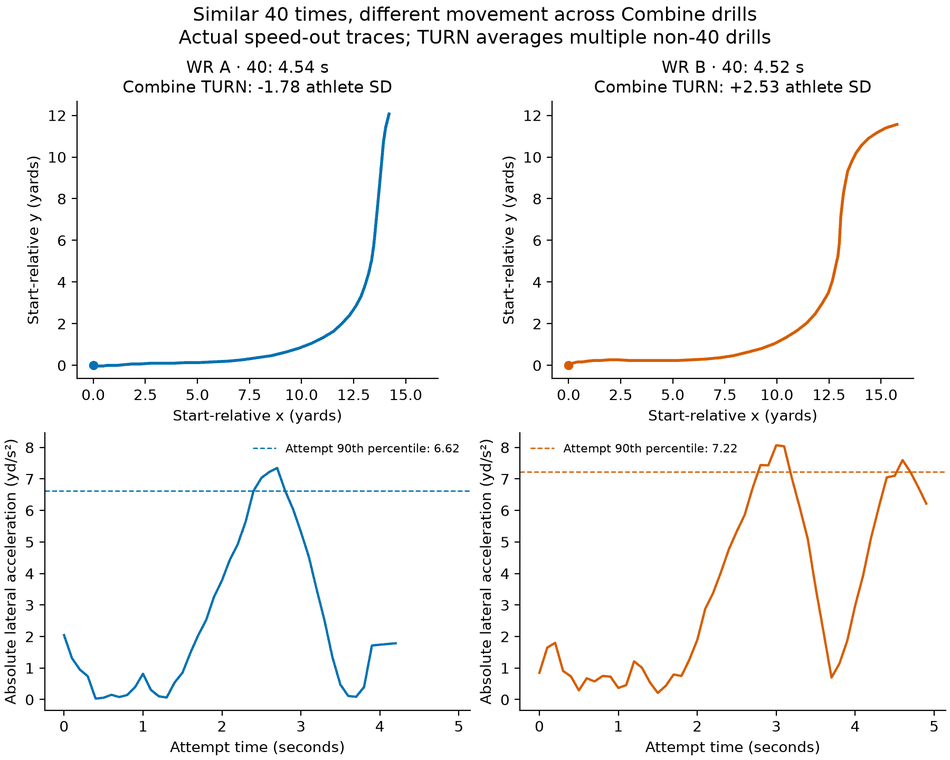

**Figure 2**

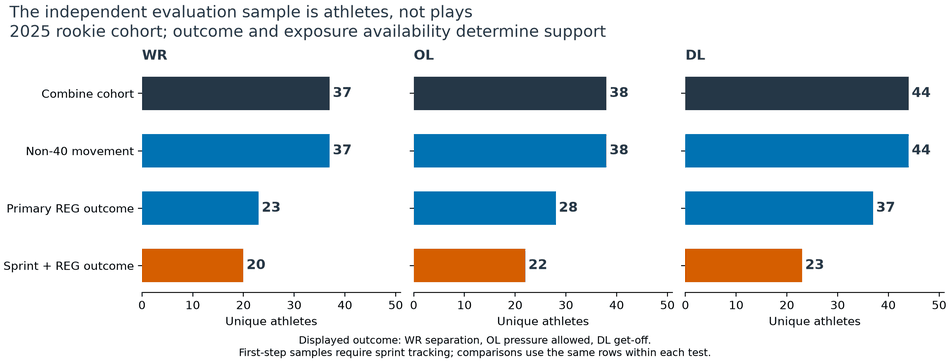

**Figure 3**

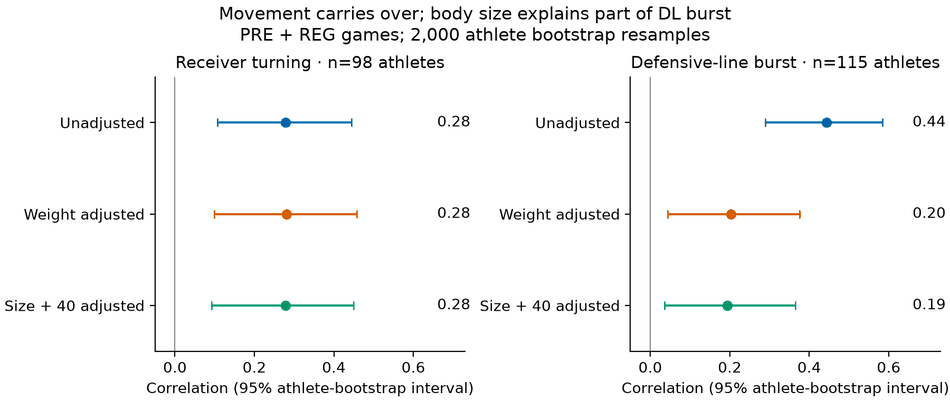

**Figure 4**

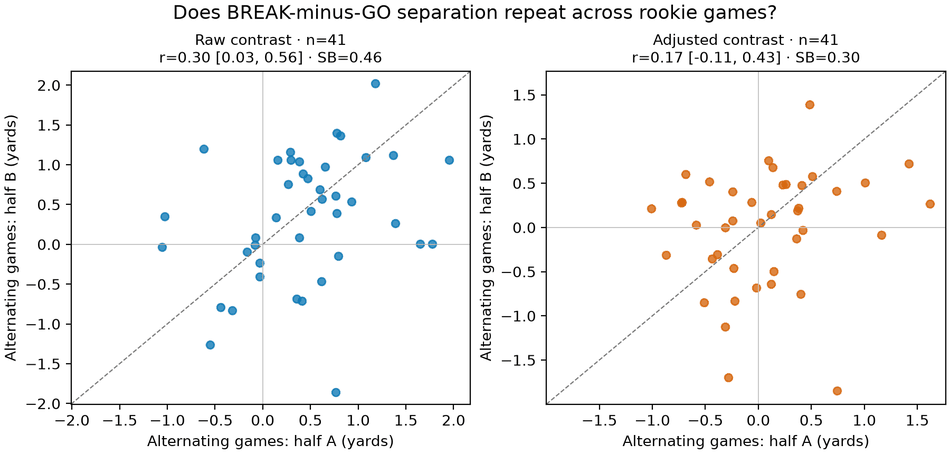

**Figure 5**

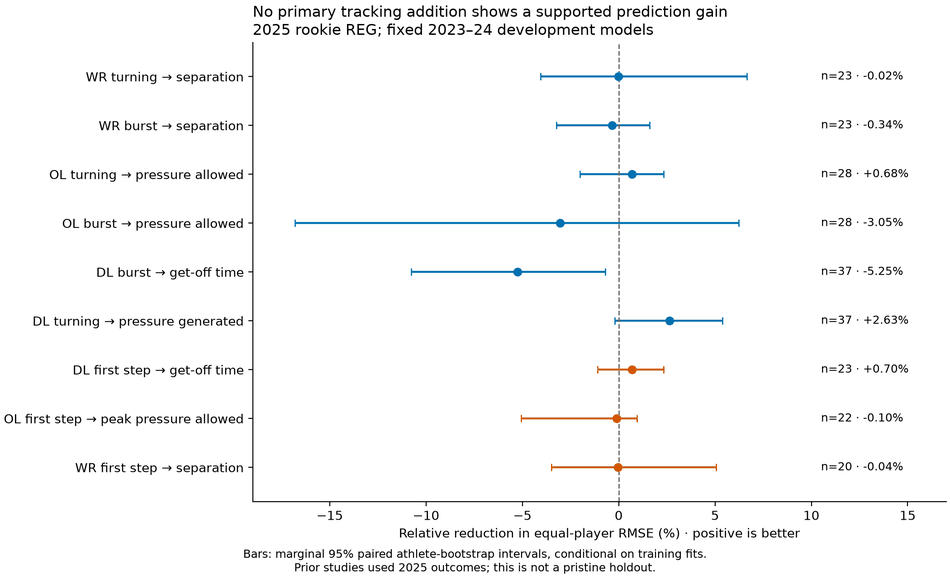

**Figure 6**

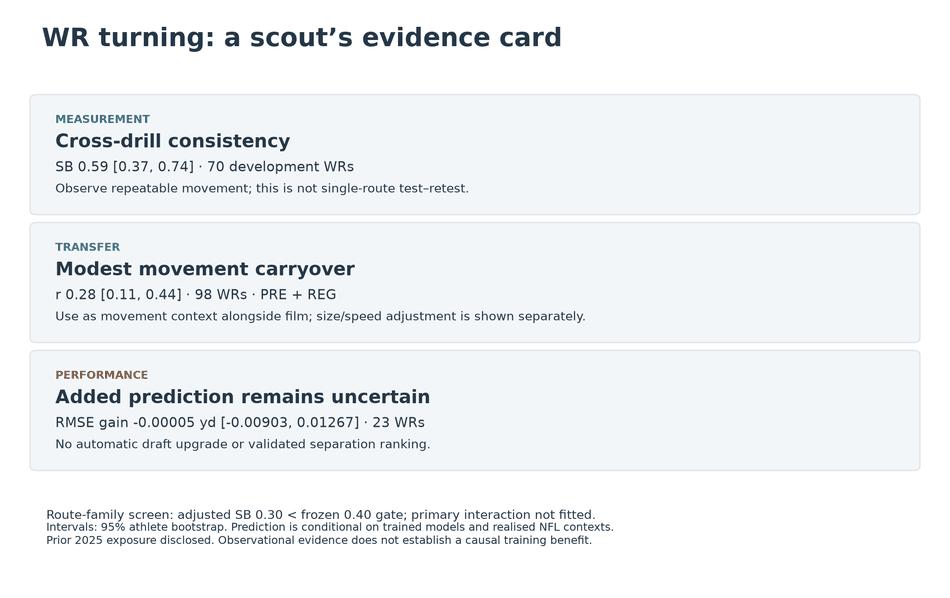

,comparison,units,evaluation_players,baseline_RMSE,tracking_RMSE,improvement_95_lo,improvement_95_hi
0,WR turning → separation,yards,23,0.23572,0.23577,-0.00903,0.01267
1,WR burst → separation,yards,23,0.23572,0.23651,-0.00641,0.00416
2,OL turning → pressure allowed,proportion,28,0.09511,0.09446,-0.00114,0.00171
3,OL burst → pressure allowed,proportion,28,0.09511,0.09800,-0.00728,0.00382
4,DL burst → get-off time,seconds,37,0.07583,0.07981,-0.00705,-0.00049
5,DL turning → pressure generated,proportion,37,0.04370,0.04255,-0.00008,0.00231
6,DL first step → get-off time,seconds,23,0.09281,0.09216,-0.00086,0.00195
7,OL first step → peak pressure allowed,proportion,22,0.09364,0.09373,-0.00181,0.00066
8,WR first step → separation,yards,20,0.21054,0.21062,-0.00779,0.00875


In [10]:
from IPython.display import Image, display, Markdown
import pandas as pd
FIGURES = ['combine_route_trace','evidence_support','transfer_audited',
           'study3_measurement','cohort_prediction','scout_evidence_card']
for index,name in enumerate(FIGURES,1):
    display(Markdown(f'**Figure {index}**'))
    display(Image(filename=str(run_root/'reports/figures'/(name+'.png'))))
table = pd.read_csv(run_root/'reports/evaluation_table.csv')
display(table[['comparison','units','evaluation_players','baseline_RMSE','tracking_RMSE',
               'improvement_95_lo','improvement_95_hi']].round(5))

## Complete record and decision

The evidence map supports describing repeatable movement and modest transfer while withholding
automatic draft upgrades. Nine primary marginal intervals do not support a prediction gain;
all original-family simultaneous intervals include zero. Uncertainty is not equivalence.
The route-family contrast failed the original measurement threshold before the interaction fit.

The full cone record retains the positive nine-athlete DL A0 cohort finding and the positive
historical DL TURN/pressure coefficient, as well as uncertain/adverse findings. These selected
subsets do not establish universal performance rankings. Rebuilt reports below include all tests,
sample attrition, context mappings, fit warnings and preprocessing metadata.

Limitations: prior 2025 exposure; small evaluation samples; training uncertainty omitted; selection
into NFL playing time and cone testing; observational context; incomplete opponent/ball tracking.
Player-only coordinates cannot reconstruct opponent geometry. Separation is the supplied
pass-forward-event field, not a break-specific causal effect. Practice/film review is a proposed use.

In [11]:
for name in ['reliability','transfer_audit','model_audit','study3_measurement','validation','cone_sensitivity']:
    display(Markdown((run_root/'reports'/(name+'.md')).read_text()))
stages = json.loads((run_root/'reports/rebuild_stages.json').read_text())
summary = {'source':'nine raw competition CSVs','cohort_pipeline_rebuilt_in_notebook':True,
           'all_headlines_verified':True,'figures':6,'tables':1,
           'elapsed_seconds':round(time.monotonic()-STARTED,2),
           'largest_stage_sampled_RSS_MiB':max(s['sampled_peak_RSS_MiB'] for s in stages),
           'versions':{p:version(p) for p in runtime_packages},'output_root':str(run_root)}
(run_root/'reports/full_notebook_execution.json').write_text(json.dumps(summary,indent=2)+'\n')
print(json.dumps(summary,indent=2))
# Public outputs contain summaries, not source/row-level data.
if Path('/kaggle/working').exists():
    import shutil
    shutil.rmtree(run_root/'data')
    print('Removed input links and intermediate row-level data from Kaggle outputs.')

# Movement reliability reproduction

Generated UTC: 2026-11-10T11:16:25.630036+00:00. Seed 20261109; 10,000 paired athlete bootstrap resamples.

Cross-drill halves use alphabetically ordered canonical drills, alternating within athlete, as in the original pipeline. These measure consistency across different tasks, not same-route test–retest. Spearman–Brown (SB) assumes comparable halves; negative values are retained and intervals describe substantial uncertainty.

| sample | position | feature | n | r | r_lo | r_hi | SB | SB_lo | SB_hi | valid_bootstraps |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| historical full cohort | WR | lat | 107 | 0.375 | 0.218 | 0.515 | 0.546 | 0.357 | 0.68 | 10000 |
| historical full cohort | WR | burst | 107 | 0.478 | 0.315 | 0.615 | 0.647 | 0.48 | 0.761 | 10000 |
| historical full cohort | WR | brake | 107 | 0.07 | -0.126 | 0.268 | 0.131 | -0.289 | 0.422 | 10000 |
| historical full cohort | WR | vmax | 107 | 0.37 | 0.189 | 0.533 | 0.541 | 0.318 | 0.696 | 10000 |
| development, training reference | WR | TURN | 70 | 0.421 | 0.229 | 0.583 | 0.593 | 0.373 | 0.737 | 10000 |
| historical full cohort | DB | lat | 122 | 0.141 | -0.053 | 0.317 | 0.247 | -0.111 | 0.482 | 10000 |
| historical full cohort | DB | burst | 122 | 0.06 | -0.136 | 0.248 | 0.114 | -0.316 | 0.398 | 10000 |
| historical full cohort | DB | brake | 122 | 0.185 | 0.01 | 0.351 | 0.312 | 0.019 | 0.52 | 10000 |
| historical full cohort | DB | vmax | 122 | 0.558 | 0.42 | 0.675 | 0.716 | 0.591 | 0.806 | 10000 |
| development, training reference | DB | TURN | 85 | 0.164 | -0.061 | 0.371 | 0.282 | -0.13 | 0.541 | 10000 |
| historical full cohort | OL | lat | 121 | 0.43 | 0.267 | 0.57 | 0.602 | 0.422 | 0.726 | 10000 |
| historical full cohort | OL | burst | 121 | 0.277 | 0.087 | 0.443 | 0.434 | 0.16 | 0.614 | 10000 |
| historical full cohort | OL | brake | 121 | -0.034 | -0.239 | 0.179 | -0.071 | -0.627 | 0.303 | 10000 |
| historical full cohort | OL | vmax | 121 | 0.65 | 0.534 | 0.75 | 0.788 | 0.696 | 0.857 | 10000 |
| development, training reference | OL | TURN | 83 | 0.335 | 0.118 | 0.522 | 0.502 | 0.211 | 0.686 | 10000 |
| historical full cohort | DL | lat | 118 | 0.404 | 0.258 | 0.54 | 0.575 | 0.41 | 0.701 | 10000 |
| historical full cohort | DL | burst | 118 | 0.418 | 0.246 | 0.559 | 0.589 | 0.395 | 0.717 | 10000 |
| historical full cohort | DL | brake | 118 | 0.234 | 0.072 | 0.387 | 0.379 | 0.134 | 0.558 | 10000 |
| historical full cohort | DL | vmax | 118 | 0.745 | 0.659 | 0.814 | 0.854 | 0.794 | 0.898 | 10000 |
| development, training reference | DL | TURN | 74 | 0.339 | 0.149 | 0.506 | 0.506 | 0.259 | 0.672 | 10000 |
| historical full cohort | TE | lat | 42 | 0.057 | -0.293 | 0.397 | 0.109 | -0.828 | 0.568 | 10000 |
| historical full cohort | TE | burst | 42 | 0.454 | 0.2 | 0.705 | 0.625 | 0.333 | 0.827 | 10000 |
| historical full cohort | TE | brake | 42 | 0.163 | -0.078 | 0.453 | 0.281 | -0.168 | 0.624 | 10000 |
| historical full cohort | TE | vmax | 42 | 0.307 | 0.044 | 0.555 | 0.47 | 0.085 | 0.714 | 10000 |
| development, training reference | TE | TURN | 25 | 0.179 | -0.217 | 0.55 | 0.303 | -0.555 | 0.71 | 10000 |

## Same-drill TURN repeats

First two attempts by recorded attempt number (event ID breaks ties). Pearson r is the repeat correlation; SB is a two-attempt composite estimate, not the reliability of a single attempt. Fewer than four pairs return no estimate. No reliability-based feature selection or attempt exclusion. These descriptive repeats include all classes.

| position | drill | n | r | r_lo | r_hi | SB | SB_lo | SB_hi | valid_bootstraps |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| DB | BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL | 2 | None | None | None | None | None | None | 0 |
| DB | BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION | 119 | 0.583 | 0.437 | 0.71 | 0.736 | 0.608 | 0.831 | 10000 |
| DB | BOX_DRILL | 3 | None | None | None | None | None | None | 0 |
| DB | GAUNTLET_DRILL | 4 | 0.663 | -1.0 | 1.0 | 0.797 | None | 1.0 | 9857 |
| DB | LINE_DRILL | 99 | 0.215 | 0.039 | 0.402 | 0.353 | 0.075 | 0.574 | 10000 |
| DB | SHORT_SHUTTLE | 8 | 0.159 | -0.563 | 0.868 | 0.274 | -2.572 | 0.929 | 10000 |
| DB | TERYL_AUSTIN_DRILL_1 | 2 | None | None | None | None | None | None | 0 |
| DB | TERYL_AUSTIN_DRILL_2 | 2 | None | None | None | None | None | None | 0 |
| DB | THREE_CONE_DRILL | 7 | 0.484 | -0.755 | 0.964 | 0.653 | -6.147 | 0.982 | 10000 |
| DB | W_DRILL | 3 | None | None | None | None | None | None | 0 |
| DL | BACK_PEDAL_AND_REACT | 3 | None | None | None | None | None | None | 0 |
| DL | BODY_CONTROL_DRILL | 2 | None | None | None | None | None | None | 0 |
| DL | PASS_RUSH_DRILL | 106 | 0.437 | 0.268 | 0.595 | 0.609 | 0.422 | 0.746 | 10000 |
| DL | RUN_AND_CLUB_DRILL | 1 | None | None | None | None | None | None | 0 |
| DL | RUN_THE_HOOP_DRILL | 10 | 0.483 | -0.147 | 0.828 | 0.652 | -0.344 | 0.906 | 10000 |
| DL | SHORT_SHUTTLE | 4 | -0.152 | -1.0 | 1.0 | -0.359 | None | 1.0 | 9857 |
| DL | SHORT_ZONE_BREAKS | 39 | 0.202 | -0.079 | 0.505 | 0.336 | -0.172 | 0.671 | 10000 |
| DL | THREE_CONE_DRILL | 12 | 0.087 | -0.542 | 0.666 | 0.16 | -2.362 | 0.8 | 10000 |
| OL | PASS_RUSH_DROP | 118 | 0.235 | 0.084 | 0.37 | 0.38 | 0.154 | 0.54 | 10000 |
| OL | SCREEN_DRILL | 1 | None | None | None | None | None | None | 0 |
| OL | SHORT_SHUTTLE | 13 | 0.583 | 0.268 | 0.886 | 0.737 | 0.422 | 0.94 | 10000 |
| OL | THREE_CONE_DRILL | 7 | 0.312 | -0.468 | 0.814 | 0.476 | -1.761 | 0.898 | 10000 |
| TE | BLOCK_EXPLOSION | 1 | None | None | None | None | None | None | 0 |
| TE | CORNER_ROUTE | 29 | 0.423 | 0.059 | 0.711 | 0.595 | 0.111 | 0.831 | 10000 |
| TE | END_ZONE_FADE_RIGHT | 7 | 0.703 | -0.406 | 0.995 | 0.826 | -1.365 | 0.998 | 10000 |
| TE | GAUNTLET_DRILL | 40 | 0.539 | 0.206 | 0.755 | 0.701 | 0.342 | 0.86 | 10000 |
| TE | HOOK_ROUTE_RIGHT | 4 | -0.538 | -1.0 | 1.0 | -2.329 | None | 1.0 | 9857 |
| TE | IN_ROUTE_LEFT | 3 | None | None | None | None | None | None | 0 |
| TE | OVER_SHOULDER_ADJUST | 4 | 0.132 | -1.0 | 1.0 | 0.234 | None | 1.0 | 9857 |
| TE | SHORT_SHUTTLE | 11 | 0.399 | -0.341 | 0.814 | 0.571 | -1.037 | 0.897 | 10000 |
| TE | THREE_CONE_DRILL | 7 | 0.587 | -0.314 | 0.997 | 0.74 | -0.918 | 0.999 | 10000 |
| TE | WHEEL_ROUTE_LEFT | 5 | 0.996 | 0.952 | 1.0 | 0.998 | 0.976 | 1.0 | 9982 |
| WR | CIRCUS_ROUTE_LEFT | 6 | 0.756 | -0.891 | 0.998 | 0.861 | -16.34 | 0.999 | 10000 |
| WR | COMEBACK_ROUTE_RIGHT | 12 | 0.534 | 0.043 | 0.963 | 0.697 | 0.082 | 0.981 | 10000 |
| WR | CURL_ROUTE_RIGHT | 7 | -0.391 | -0.927 | 0.681 | -1.285 | -25.429 | 0.81 | 10000 |
| WR | DAGGER_ROUTE_LEFT | 8 | 0.298 | -0.337 | 0.884 | 0.459 | -1.017 | 0.938 | 10000 |
| WR | GAUNTLET_DRILL | 93 | 0.331 | 0.105 | 0.506 | 0.498 | 0.189 | 0.672 | 10000 |
| WR | GO_ROUTE_RIGHT | 7 | 0.074 | -0.775 | 0.911 | 0.138 | -6.88 | 0.953 | 10000 |
| WR | OVER_SHOULDER_ADJUST | 1 | None | None | None | None | None | None | 0 |
| WR | POST_CORNER_ROUTE_LEFT | 10 | 0.495 | -0.276 | 0.909 | 0.662 | -0.762 | 0.952 | 10000 |
| WR | POST_CORNER_ROUTE_RIGHT | 15 | 0.375 | -0.179 | 0.874 | 0.546 | -0.436 | 0.933 | 10000 |
| WR | RED_ZONE_FADE_RIGHT | 13 | 0.511 | -0.065 | 0.859 | 0.676 | -0.138 | 0.924 | 10000 |
| WR | SHORT_SHUTTLE | 6 | -0.651 | -1.0 | 0.492 | -3.727 | -1139604.445 | 0.659 | 10000 |
| WR | SLANT_ROUTE_LEFT | 3 | None | None | None | None | None | None | 0 |
| WR | SLOT_SAIL_ROUTE_RIGHT | 8 | -0.011 | -0.951 | 0.929 | -0.022 | -39.159 | 0.963 | 10000 |
| WR | SLOT_STRIKE_ROUTE_LEFT | 1 | None | None | None | None | None | None | 0 |
| WR | SPEED_OUT_ROUTE_LEFT | 17 | 0.012 | -0.442 | 0.492 | 0.024 | -1.587 | 0.659 | 10000 |
| WR | THREE_CONE_DRILL | 5 | 0.723 | 0.147 | 1.0 | 0.839 | 0.257 | 1.0 | 9982 |

## Exposure QC and training-only reference

| attempts | nonfinite_turn_attempts | nonpositive_duration | nonfinite_coordinates | dropped_attempts | turn_range |
| --- | --- | --- | --- | --- | --- |
| 5517 | 0 | 0 | 0 | 0 | [0.30545849645434453, 7.743827875910975] |

Training-reference means/SDs use unique player/drill means from 2023–24 athletes across positions. The same reference transforms 2025 without using its distribution. Excluded constant/sparse drills: []; unseen drills: ['CIRCUS_ROUTE_LEFT', 'SHORT_ZONE_BREAK_FLAT_WHEEL', 'SHORT_ZONE_BREAK_FORWARD', 'SHORT_ZONE_BREAK_INSIDE']. Metadata: `study3_turn_reference.json`.

This check uses no NFL outcomes. Trace figures and the route-contrast measurement screen are separate requirements. Historical reports remain unchanged.


# Movement transfer audit

Generated UTC: 2026-11-10T11:16:53.080725+00:00.

| scope | position | trait | adjustment | game_SB | n | r | lo | hi | valid_bootstraps |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| historical, PRE+REG+POST | WR | lat | raw | 0.653 | 99 | 0.276 | 0.095 | 0.44 | 2000 |
| historical, PRE+REG+POST | WR | lat | weight-adjusted | 0.653 | 99 | 0.28 | 0.09 | 0.448 | 2000 |
| historical, PRE+REG+POST | WR | lat | size+forty-adjusted | 0.653 | 99 | 0.278 | 0.087 | 0.45 | 2000 |
| historical, PRE+REG+POST | DL | burst | raw | 0.804 | 115 | 0.45 | 0.297 | 0.589 | 2000 |
| historical, PRE+REG+POST | DL | burst | weight-adjusted | 0.804 | 115 | 0.206 | 0.044 | 0.382 | 2000 |
| historical, PRE+REG+POST | DL | burst | size+forty-adjusted | 0.804 | 115 | 0.195 | 0.035 | 0.365 | 2000 |
| corrected, PRE+REG | WR | lat | raw | 0.643 | 98 | 0.279 | 0.107 | 0.445 | 2000 |
| corrected, PRE+REG | WR | lat | weight-adjusted | 0.643 | 98 | 0.281 | 0.099 | 0.457 | 2000 |
| corrected, PRE+REG | WR | lat | size+forty-adjusted | 0.643 | 98 | 0.278 | 0.092 | 0.45 | 2000 |
| corrected, PRE+REG | DL | burst | raw | 0.804 | 115 | 0.443 | 0.289 | 0.584 | 2000 |
| corrected, PRE+REG | DL | burst | weight-adjusted | 0.804 | 115 | 0.203 | 0.044 | 0.376 | 2000 |
| corrected, PRE+REG | DL | burst | size+forty-adjusted | 0.804 | 115 | 0.194 | 0.035 | 0.365 | 2000 |
| sensitivity, REG only | WR | lat | raw | 0.694 | 74 | 0.322 | 0.122 | 0.503 | 2000 |
| sensitivity, REG only | WR | lat | weight-adjusted | 0.694 | 74 | 0.33 | 0.112 | 0.519 | 2000 |
| sensitivity, REG only | WR | lat | size+forty-adjusted | 0.694 | 74 | 0.339 | 0.092 | 0.538 | 2000 |
| sensitivity, REG only | DL | burst | raw | 0.84 | 92 | 0.418 | 0.234 | 0.581 | 2000 |
| sensitivity, REG only | DL | burst | weight-adjusted | 0.84 | 92 | 0.178 | -0.013 | 0.377 | 2000 |
| sensitivity, REG only | DL | burst | size+forty-adjusted | 0.84 | 92 | 0.169 | -0.028 | 0.364 | 2000 |

Each athlete contributes one pooled-season movement trait (≥30 player-plays). All seasons are full-cohort descriptive measurements, not development/evaluation prediction. Historical scope included POST; corrected scope explicitly excludes POST while retaining PRE+REG, as specified in the measurement preregistration. REG-only is a season-type sensitivity. Per-season traits with season-specific normalisation are also cached for later checks; these correlations are pooled.

Game normalisation retains the original lined-up-position × play-type cells. Receiver play type uses recorded route, OL uses dropback availability and DL uses sack availability. No outcome-nullification filter is newly added to historical movement measurement. Context is available only for the inner-joined source rows.

Adjusted correlations residualise both Combine and game traits on the stated covariates plus an intercept, within position. Size+forty uses position-sample median forty and a missing indicator. 2,000 paired athlete bootstrap resamples refit residualisation each time; percentile intervals. Adjustment definitions are explicit and need not match undocumented historical exploratory calculations. Game SB is alternating-game split-half reliability. Complete position/trait tables are in JSON, without selecting new performance hypotheses.

Joined movement plays: 311,731; POST excluded from corrected scope: 12,925. Historical `transfer.md` is unchanged.


# Studies 1–2 model audit

Generated UTC: 2026-11-10T11:17:03.674775+00:00. All recorded fits converged. Two-sided Holm-significant original-family rows: 0/9; binary cluster-sensitivity rows: 0/3.

| id | model | method | plays | players | beta | ci95 | p_two | p_two_holm |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| W1 | original specification | LMM | 31035 | 83 | -0.01499 | [-0.05001, 0.02004] | 0.4016 | 1.0 |
| W2 | original specification | LMM | 31035 | 83 | 0.00081 | [-0.03581, 0.03742] | 0.9655 | 1.0 |
| O1 | original specification | LMM | 48697 | 89 | 0.00137 | [-0.00474, 0.00749] | 0.6604 | 1.0 |
| O1 | original specification | player-clustered LPM sensitivity | 48697 | 89 | 0.00287 | [-0.00365, 0.00939] | 0.3841 | 0.7682 |
| O2 | original specification | LMM | 48697 | 89 | -0.00312 | [-0.00957, 0.00333] | 0.3432 | 1.0 |
| O2 | original specification | player-clustered LPM sensitivity | 48697 | 89 | -0.00259 | [-0.00858, 0.00341] | 0.3936 | 0.7682 |
| D1 | original specification | LMM | 33417 | 98 | 0.00237 | [-0.01381, 0.01854] | 0.7743 | 1.0 |
| D2 | original specification | LMM | 28970 | 98 | 0.00549 | [-0.00061, 0.01160] | 0.078 | 0.4677 |
| D2 | original specification | player-clustered LPM sensitivity | 28970 | 98 | 0.0042 | [-0.00067, 0.00908] | 0.0903 | 0.271 |
| F1 | confirmatory, player SDs | LMM | 25799 | 77 | -0.00119 | [-0.01900, 0.01662] | 0.8961 | 0.8961 |
| F1 | secondary, player SDs | LMM | 25799 | 77 | -0.00154 | [-0.01919, 0.01612] | 0.8646 | — |
| F2 | confirmatory, player SDs | LMM | 37216 | 73 | -0.0042 | [-0.01149, 0.00309] | 0.2591 | 0.7773 |
| F2 | secondary, player SDs | LMM | 37216 | 73 | -0.00399 | [-0.01072, 0.00273] | 0.2444 | — |
| F3 | confirmatory, player SDs | LMM | 26624 | 73 | -0.02029 | [-0.05890, 0.01831] | 0.3029 | 0.7773 |
| F3 | secondary, player SDs | LMM | 26624 | 73 | -0.02123 | [-0.06060, 0.01814] | 0.2905 | — |

## Corrections and limits

Historical reports remain unchanged. Study 1 LMM rows reproduce the original specification and are shown for audit, including its model-based binary SE deviation. Separate binary OLS linear-probability fits use player-clustered sandwich SE, finite-sample correction and t reference with players−1 degrees of freedom. They change the estimator as well as uncertainty and are explicitly sensitivities.

The preregistration stated expected signs but did not explicitly state one-sided testing. Original code used directional p-values. This audit conservatively reports two-sided p-values and Holm across the six Study 1 LMM and three Study 2 confirmatory rows separately. The three cluster sensitivities form a separately labelled Holm family. Historical directional values are saved in JSON, not promoted as new findings.

Study 2 A0 and 10-yard-split imputation/SDs now use unique sprint-tracked athletes within position, before joining to plays. Historical code weighted these moments by opportunity. Baseline Study 1 preprocessing is retained. This is a full-cohort historical audit, not held-out prediction or a pristine 2025 evaluation.

Patsy removes only rows missing required formula fields; model groups follow the actual retained indices. Constant/redundant columns are removed by an ordered rank rule before fitting; actual samples, dropped terms, warnings, covariate estimates and timings are recorded in `model_audit.json` and per-model checkpoints. Normal-reference LMM intervals retain the original continuous-model method. Covariate estimates are descriptive checks, not an additional confirmatory family.

A non-significant result does not establish equivalence or no predictive value. Held-out evaluation and same-sample 3-cone sensitivity remain separate required work.


# Study 3 — Frozen measurement screen

Generated UTC: 2026-11-10T11:16:27.407768+00:00. **Stop primary route-performance claim: frozen reliability screen fails.**

No TURN–separation association or 2025 performance evaluation was fitted. The only outcome fit is the frozen conventional baseline on 2023–24 rookie REG plays.

| draft_year | players_initial | plays_initial | players_fitted | plays_fitted |
| --- | --- | --- | --- | --- |
| 2023 | 25 | 2385 | 25 | 2385 |
| 2024 | 17 | 1586 | 17 | 1586 |
| 2025 | 16 | 1179 | 16 | 1179 |

## Alternating-game contrast reliability

| contrast | n | r | r_lo | r_hi | SB | SB_lo | SB_hi | valid_bootstraps |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| raw | 41 | 0.301 | 0.032 | 0.56 | 0.463 | 0.062 | 0.718 | 10000 |
| adjusted | 41 | 0.174 | -0.114 | 0.435 | 0.296 | -0.257 | 0.606 | 10000 |

Chronological game IDs are ordered within each athlete and alternated. Each diagnostic player has ≥3 outcome-recorded BREAK and GO plays in each half. Raw contrast is mean BREAK separation minus mean GO separation, in yards. Adjusted contrast removes non-player components of the conventional baseline, including conventional-measurable family interactions. The halves share estimated adjustments; this is a descriptive screen, not an independent replication. 10,000 paired player bootstrap resamples give percentile correlation intervals; negative SB values are retained.

Frozen gate: ≥25 diagnostic development players and adjusted SB point estimate ≥0.40. A pass still requires acknowledging its interval; a fail stops the primary route-performance claim without trying alternate groups or thresholds.

Baseline: 3,971 plays, 42 players, 384 games; design rank 65. Row weight is 1/n(player,family), giving equal total weight to each player/family. Player fixed intercepts; separate route/down/coverage/alignment indicators; linear yards-to-go, motion, cushion/missing indicator; six conventional BREAK interactions. All player SDs and forty imputation use unique 2023–24 WRs; cushion uses development plays. No evaluation statistics inform preprocessing.

Redundant columns removed in declared order: [].

Saved: `study3_measurement.json`, `study3_preprocessing.json`, `study3_baseline.json`; figure `figures/study3_measurement.png`. Full-cohort TURN numerical values differ from the training-reference recomputation by design. Prior 2025 exposure in Studies 1–2 remains disclosed.


# Studies 1–2 cohort prediction validation

Generated UTC: 2026-11-10T11:17:24.193262+00:00. Frozen development: 2026-11-10T11:17:21.200842+00:00.

Positive improvement means lower equal-player RMSE with tracking. Units are yards for WR separation, seconds for DL get-off, and outcome-scale probability/proportion units for pressure outcomes. This is retrospective conditional prediction on realised NFL context.

| test | family | train_players | eval_players | eval_plays | baseline_RMSE | tracking_RMSE | improvement | ci95 | family_interval |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| W1 | primary | 57 | 23 | 3701 | 0.23572 | 0.23577 | -5e-05 | [-0.00903, 0.01267] | [-0.01138, 0.01746] |
| W2 | primary | 57 | 23 | 3701 | 0.23572 | 0.23651 | -0.00079 | [-0.00641, 0.00416] | [-0.00779, 0.00536] |
| O1 | primary | 54 | 28 | 8475 | 0.09511 | 0.09446 | 0.00065 | [-0.00114, 0.00171] | [-0.00156, 0.00198] |
| O2 | primary | 54 | 28 | 8475 | 0.09511 | 0.098 | -0.0029 | [-0.00728, 0.00382] | [-0.00972, 0.00596] |
| D1 | primary | 57 | 37 | 5245 | 0.07583 | 0.07981 | -0.00398 | [-0.00705, -0.00049] | [-0.00791, 0.00064] |
| D2 | primary | 57 | 37 | 4644 | 0.0437 | 0.04255 | 0.00115 | [-0.00008, 0.00231] | [-0.00049, 0.00266] |
| F1 | primary | 50 | 23 | 2589 | 0.09281 | 0.09216 | 0.00065 | [-0.00086, 0.00195] | [-0.00117, 0.00220] |
| F2 | primary | 45 | 22 | 6428 | 0.09364 | 0.09373 | -9e-05 | [-0.00181, 0.00066] | [-0.00217, 0.00085] |
| F3 | primary | 51 | 20 | 3525 | 0.21054 | 0.21062 | -8e-05 | [-0.00779, 0.00875] | [-0.00913, 0.01047] |

## Prespecified secondary and cone comparisons

| test | family | train_players | eval_players | eval_plays | baseline_RMSE | tracking_RMSE | improvement | ci95 | family_interval |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| W1_joint | joint secondary | 57 | 23 | 3701 | 0.23572 | 0.23593 | -0.00021 | [-0.00857, 0.00870] | [-0.00857, 0.00870] |
| O1_joint | joint secondary | 54 | 28 | 8475 | 0.09511 | 0.09689 | -0.00179 | [-0.00564, 0.00373] | [-0.00564, 0.00373] |
| D1_joint | joint secondary | 57 | 37 | 5245 | 0.07583 | 0.08097 | -0.00514 | [-0.01033, -0.00068] | [-0.01033, -0.00068] |
| D2_joint | joint secondary | 57 | 37 | 4644 | 0.0437 | 0.04302 | 0.00067 | [-0.00117, 0.00243] | [-0.00117, 0.00243] |
| F1_no10 | no-10yd secondary | 50 | 23 | 2589 | 0.09234 | 0.09193 | 0.00041 | [-0.00058, 0.00122] | [-0.00058, 0.00122] |
| F2_no10 | no-10yd secondary | 45 | 22 | 6428 | 0.0931 | 0.0946 | -0.0015 | [-0.00330, -0.00014] | [-0.00330, -0.00014] |
| F3_no10 | no-10yd secondary | 51 | 20 | 3525 | 0.20558 | 0.20494 | 0.00064 | [-0.00559, 0.00761] | [-0.00559, 0.00761] |
| W1_cone | cone sensitivity | 17 | 7 | 1508 | 0.39482 | 0.36205 | 0.03276 | [-0.04748, 0.09115] | [-0.04748, 0.09115] |
| W2_cone | cone sensitivity | 17 | 7 | 1508 | 0.39482 | 0.64975 | -0.25493 | [-0.39734, -0.12727] | [-0.39734, -0.12727] |
| O1_cone | cone sensitivity | 26 | 13 | 3491 | 0.13922 | 0.13969 | -0.00047 | [-0.00116, 0.00075] | [-0.00116, 0.00075] |
| O2_cone | cone sensitivity | 26 | 13 | 3491 | 0.13922 | 0.14207 | -0.00286 | [-0.00523, 0.00038] | [-0.00523, 0.00038] |
| D1_cone | cone sensitivity | 20 | 13 | 1732 | 0.06833 | 0.08501 | -0.01668 | [-0.04755, 0.01432] | [-0.04755, 0.01432] |
| D2_cone | cone sensitivity | 20 | 13 | 1501 | 0.04805 | 0.04836 | -0.00032 | [-0.00598, 0.00569] | [-0.00598, 0.00569] |
| F1_cone | cone sensitivity | 20 | 9 | 979 | 0.0671 | 0.05955 | 0.00755 | [0.00443, 0.01080] | [0.00443, 0.01080] |
| F2_cone | cone sensitivity | 26 | 12 | 3323 | 0.13365 | 0.13377 | -0.00012 | [-0.00140, 0.00040] | [-0.00140, 0.00040] |
| F3_cone | cone sensitivity | 16 | 6 | 1353 | 0.44357 | 0.33364 | 0.10993 | [-0.01557, 0.21656] | [-0.01557, 0.21656] |

## Validation boundaries

Rookie REG, non-nullified plays; 2023–24 development and 2025 evaluation. No evaluation-player effects, imputation moments, context coefficients or recalibration are fitted from evaluation outcomes. Fixed predictions are averaged within athlete; a common baseline context adjustment leaves the compared errors unchanged. All nine original exposures/outcomes are reported, without promoting a winning secondary.

10,000 paired athlete resamples give percentile improvement intervals conditional on the frozen development fits. Primary family intervals use Bonferroni-adjusted percentiles within six Study 1 / three Study 2 comparisons; finite bootstrap tails and small evaluation samples limit precision. Training uncertainty is not included. The ≥30-play sensitivity, MAE, relative changes and unknown-level counts are in JSON.

The historical studies already used 2025 outcomes: this is not a pristine holdout. An unseen 2025 calendar intercept maps to the latest trained season; other unseen context levels use frozen UNK/modal encodings. Boundary warnings are retained in development metadata. Binary LPM predictions are not clipped or described as calibrated probabilities. Small cone subsets are sensitivities, not general scouting validation.

No Study 3 interaction is fitted; its measurement gate remains failed. Full protocol: `evaluation_protocol.md`; frozen preprocessing/coefficients: `evaluation_development.json`, `evaluation_models/`; per-athlete errors: `data/interim/evaluation_player_scores.parquet`.


# Same-sample 3-cone sensitivity

Generated UTC: 2026-11-10T11:17:33.588000+00:00. Recorded cone times only; no imputation.

| test | outcome_players | cone_players | plays | beta_without_cone | ci_without | beta_with_cone | ci_with |
| --- | --- | --- | --- | --- | --- | --- | --- |
| W1 | 83 | 25 | 9438 | 0.00549 | [-0.12147, 0.13246] | 0.01139 | [-0.11490, 0.13768] |
| W2 | 83 | 25 | 9438 | -0.02039 | [-0.11930, 0.07851] | -0.02772 | [-0.13337, 0.07793] |
| O1 | 89 | 43 | 20730 | -0.00268 | [-0.00969, 0.00433] | -0.00235 | [-0.00953, 0.00482] |
| O2 | 89 | 43 | 20730 | -0.00146 | [-0.00693, 0.00400] | 0.00042 | [-0.00597, 0.00681] |
| D1 | 98 | 37 | 12470 | -0.01074 | [-0.05166, 0.03018] | -0.01068 | [-0.05361, 0.03226] |
| D2 | 98 | 37 | 10874 | 0.01517 | [0.00621, 0.02413] | 0.01521 | [0.00682, 0.02359] |
| F1 | 77 | 33 | 11717 | -0.02255 | [-0.05177, 0.00666] | -0.0226 | [-0.05251, 0.00731] |
| F2 | 73 | 42 | 19773 | -0.00274 | [-0.01076, 0.00528] | -0.00199 | [-0.00957, 0.00558] |
| F3 | 73 | 23 | 7918 | -0.08269 | [-0.15167, -0.01371] | -0.08328 | [-0.15586, -0.01069] |

## Support and selection

| combine_position | draft_year | players | cone_recorded |
| --- | --- | --- | --- |
| DL | 2023 | 37 | 18 |
| DL | 2024 | 37 | 10 |
| DL | 2025 | 44 | 15 |
| OL | 2023 | 37 | 20 |
| OL | 2024 | 46 | 25 |
| OL | 2025 | 38 | 16 |
| WR | 2023 | 39 | 13 |
| WR | 2024 | 31 | 9 |
| WR | 2025 | 37 | 11 |

| combine_position | draft_status | players | cone_recorded |
| --- | --- | --- | --- |
| DL | UDFA | 29 | 15 |
| DL | drafted | 89 | 28 |
| OL | UDFA | 32 | 18 |
| OL | drafted | 89 | 43 |
| WR | UDFA | 30 | 10 |
| WR | drafted | 77 | 23 |

| combine_position | cone_recorded | players | median_weight | median_forty | median_pick_drafted | UDFA_fraction |
| --- | --- | --- | --- | --- | --- | --- |
| DL | False | 75 | 279.0 | 4.775 | 125.0 | 0.18666666666666668 |
| DL | True | 43 | 279.0 | 4.84 | 103.5 | 0.3488372093023256 |
| OL | False | 60 | 315.0 | 5.1 | 79.0 | 0.23333333333333334 |
| OL | True | 61 | 310.0 | 5.18 | 118.0 | 0.29508196721311475 |
| WR | False | 74 | 201.0 | 4.46 | 129.0 | 0.2702702702702703 |
| WR | True | 33 | 197.0 | 4.46 | 110.0 | 0.30303030303030304 |

## Interpretation and method

These secondary association fits use all available REG non-nullified plays and include all cohorts, preserving the historical analysis window. They are separate from the frozen rookie-season cohort prediction models; no prediction coefficients are changed using these results. Every comparison uses identical players/plays for baseline, baseline+tracking, baseline+cone and baseline+cone+tracking. Intervals are two-sided, normal-reference LMM for continuous outcomes and player-clustered finite-sample t for binary LPM. This is not a new confirmatory family.

Trait scaling retains the historical player-level definitions and the audited unique-player Study 2 preprocessing. Cone SD is calculated from unique cone-observed athletes within position. No missing times are fabricated. Exact retained samples, rank removals, numerical retry warnings and all nested coefficients are saved in JSON. Small selected samples can yield wide intervals; no universal incremental ranking claim follows. Cohort cone-subset prediction appears separately in `validation.md`.


{
  "source": "nine raw competition CSVs",
  "cohort_pipeline_rebuilt_in_notebook": true,
  "all_headlines_verified": true,
  "figures": 6,
  "tables": 1,
  "elapsed_seconds": 523.08,
  "largest_stage_sampled_RSS_MiB": 1183.0,
  "versions": {
    "duckdb": "1.5.6",
    "polars": "2.0.0",
    "numpy": "2.5.3",
    "pandas": "3.0.6",
    "scipy": "1.18.1",
    "statsmodels": "0.15.0",
    "matplotlib": "3.11.2"
  },
  "output_root": "/tmp/bdb_raw_rebuild_6yezqm_k"
}
